<a href="https://colab.research.google.com/github/mallikarjunrao-sketch/ADA_CP/blob/main/ADA_CP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
   from google.colab import drive
   drive.mount('/content/drive')
   %cd "/content/drive/MyDrive/ADA Jackfruit"
   !ls
   !pip install -q sentence-transformers pyarrow
   !python patch_config.py

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/ADA Jackfruit
00_make_synthetic.py		      data
01_load_dataset.py		      data_ext
02_embed_cluster.py		      data_rep
03_label_agreement.py		      diffusion
04_targets.py			      figs
05_baseline.py			      figs_25pct_sample
06b_composition_controls.py	      figs_compctrl
06_pressure.py			      figs_primary_full
07_main_test.py			      figs_rep
08_classification.py		      generate_dataset3_figures.py
09_adapt_external.py		      patch_config.py
11_summary.py			      __pycache__
12_adapt_external_batch.py	      README.md
13_preprocess_external.py	      requirements.txt
14_embed_external.py		      results
24_external_baseline.py		      results_25pct_sample
25_external_competition_test.py       results_compctrl
26_external_competition_remaining.py  results_primary_full
27_external_corrected_placebo.py      results_rep
31A_external_placebo_b

In [ ]:
   !python 02_embed_cluster.py --tweets data/tweets.parquet --backend st --k 4
   !python 03_label_agreement.py

564873 en tweets in window
dropped 580 tweets with <4 words after cleaning (mostly bare links); 564293 left
embedding 480655 distinct texts (of 564293 tweets)
modules.json: 100% 349/349 [00:00<00:00, 1.78MB/s]
config_sentence_transformers.json: 100% 116/116 [00:00<00:00, 641kB/s]
README.md: 100% 10.5k/10.5k [00:00<00:00, 30.5MB/s]
sentence_bert_config.json: 100% 53.0/53.0 [00:00<00:00, 360kB/s]
config.json: 100% 612/612 [00:00<00:00, 3.89MB/s]

model.safetensors: downloading bytes:  81% 73.9M/90.9M [00:00<00:00, 105MB/s, 5.90MB/s  ] 
model.safetensors: downloading bytes: 100% 85.0M/85.0M [00:01<00:00, 67.9MB/s, 8.13MB/s  ]
model.safetensors: reconstructing file: 100% 90.9M/90.9M [00:01<00:00, 72.5MB/s, 8.82MB/s  ]
Loading weights: 100% 103/103 [00:00<00:00, 11242.73it/s]
tokenizer_config.json: 100% 350/350 [00:00<00:00, 2.03MB/s]
vocab.txt: 100% 232k/232k [00:00<00:00, 15.3MB/s]
tokenizer.json: 100% 466k/466k [00:00<00:00, 55.2MB/s]
special_tokens_map.json: 100% 112/112 [00:00<00:00, 7

In [ ]:
!python 04_targets.py
!python 06_pressure.py
!python 05_baseline.py --targets drift_db abs_sent_change abs_stance_change entity_turnover abs_frag_change abs_share_change abs_merge_change

panel: 276 cells (4 narratives x 69 weeks); valid-drift cells: 272
                n  drift_db  ...  abs_share_change  abs_merge_change
narrative                    ...                                    
0           609.0     0.017  ...             0.021             0.020
1          1510.0     0.019  ...             0.047             0.026
2           787.0     0.014  ...             0.024             0.017
3          1775.0     0.014  ...             0.043             0.015

[4 rows x 8 columns]
Sanity: Spearman(drift_db, log n) = -0.21  (should be much closer to 0 than the raw drift above)

Sanity: Spearman(drift, log n) = -0.42  (strongly negative => small cells look 'driftier' because of noise; keep log_n as a control)
CHECKPOINT (end of week 2): drift median=0.0256, p75=0.0359. If almost nothing moves, switch to a binary 'large change' target (top quartile) or a coarser bin.
              spearman_raw  spearman_within_narr    n
component                                           

In [ ]:
!python 07_main_test.py --target drift_db --n-placebo 500


=== [competition] drift_db | test from 2023-01-01 | model=ridge | 80 held-out narrative-weeks ===
                         n      mae      mse  skill_vs_persist  gain_vs_base
model                                                                       
persistence             80  0.01205  0.00050           0.00000      -0.43193
base                    80  0.01119  0.00035           0.30164       0.00000
base+ALL                80  0.01165  0.00033           0.33864       0.05298
base+pressure_eq        80  0.01098  0.00034           0.31648       0.02125
base+cpa                80  0.01101  0.00035           0.30510       0.00495
abl: drop comp_stance   80  0.01169  0.00033           0.33061       0.04148
abl: drop comp_sem      80  0.01156  0.00032           0.34670       0.06453
abl: drop comp_growth   80  0.01105  0.00032           0.35406       0.07506
abl: drop comp_reach    80  0.01164  0.00033           0.33970       0.05451
abl: drop comp_overlap  80  0.01172  0.00035          

In [ ]:
!for t in abs_sent_change abs_stance_change entity_turnover abs_frag_change abs_share_change abs_merge_change; do python 07_main_test.py --target $t --n-placebo 500; done
!python 07_main_test.py --target drift_db --n-placebo 500 --test-start 2022-11-01
!python 07_main_test.py --target drift_db --n-placebo 500 --test-start 2023-03-01
!python 07_main_test.py --target abs_stance_change --n-placebo 500 --test-start 2022-11-01
!python 08_classification.py --n-placebo 200
!python 11_summary.py


=== [competition] abs_sent_change | test from 2023-01-01 | model=ridge | 80 held-out narrative-weeks ===
                         n      mae      mse  skill_vs_persist  gain_vs_base
model                                                                       
persistence             80  0.03080  0.00171           0.00000      -0.33223
base                    80  0.02901  0.00128           0.24938       0.00000
base+ALL                80  0.02949  0.00130           0.23931      -0.01341
base+pressure_eq        80  0.02865  0.00125           0.26687       0.02330
base+cpa                80  0.02863  0.00129           0.24814      -0.00165
abl: drop comp_stance   80  0.02922  0.00129           0.24487      -0.00601
abl: drop comp_sem      80  0.02947  0.00130           0.24071      -0.01155
abl: drop comp_growth   80  0.02948  0.00130           0.24199      -0.00984
abl: drop comp_reach    80  0.02862  0.00125           0.26948       0.02678
abl: drop comp_overlap  80  0.02946  0.00131   

In [ ]:
!cp -r results results_primary_full
!cp -r figs figs_primary_full

In [ ]:
!python 06b_composition_controls.py
!python 07_main_test.py --target drift_db --n-placebo 500 --extra-base shift_country,shift_channel --tag "competition+compctrl"
!python 07_main_test.py --target drift_db --n-placebo 500 --extra-base shift_country,shift_channel --tag "competition+compctrl" --test-start 2022-11-01

       shift_country  shift_channel
count        272.000        272.000
mean           0.016          0.114
std            0.015          0.068
min            0.001          0.019
25%            0.006          0.058
50%            0.011          0.106
75%            0.023          0.160
max            0.101          0.404
added shift_country, shift_channel to data/panel_pressure.parquet

=== [competition+compctrl] drift_db | test from 2023-01-01 | model=ridge | 80 held-out narrative-weeks ===
                         n      mae      mse  skill_vs_persist  gain_vs_base
model                                                                       
persistence             80  0.01205  0.00050           0.00000      -0.40853
base                    80  0.01134  0.00035           0.29004       0.00000
base+ALL                80  0.01178  0.00033           0.32909       0.05500
base+pressure_eq        80  0.01116  0.00035           0.30537       0.02159
base+cpa                80  0.01116  0.0

In [ ]:
!cp -r results results_compctrl
!cp -r figs figs_compctrl

In [ ]:
!wget -O /content/dataset_zenodo.jsonl "https://zenodo.org/records/8043459/files/dataset_zenodo.jsonl?download=1"
!NARR_RUN=_rep python 01_load_dataset.py --src /content/dataset_zenodo.jsonl --out data_rep/tweets.parquet --lang nonen

--2026-11-09 07:46:57--  https://zenodo.org/records/8043459/files/dataset_zenodo.jsonl?download=1
Resolving zenodo.org (zenodo.org)... 188.185.40.132, 188.185.47.192, 188.185.51.60, ...
Connecting to zenodo.org (zenodo.org)|188.185.40.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 7516195088 (7.0G) [application/octet-stream]
Saving to: ‘/content/dataset_zenodo.jsonl’

/content/dataset_ze 100%[===================>]   7.00G  2.83MB/s    in 44m 14s 

2026-11-09 08:31:12 (2.70 MB/s) - ‘/content/dataset_zenodo.jsonl’ saved [7516195088/7516195088]

  read 100,000 records, kept 99,550
  read 300,000 records, kept 166,574
  read 400,000 records, kept 266,574
  read 500,000 records, kept 366,574
  read 600,000 records, kept 466,574
  read 700,000 records, kept 566,574
  read 800,000 records, kept 666,574
  read 900,000 records, kept 766,574
  read 1,000,000 records, kept 866,574
read 1,524,832 records, kept 943,363 (lang=nonen)
rows: 943363 -> 901291 after (text, 

In [ ]:
!python -c "import pandas as pd; d=pd.read_parquet('data_rep/tweets.parquet'); print(len(d)); print(d.lang.value_counts().head()); print(d.text_en.sample(8, random_state=1).tolist())"

901291
lang
ar    166369
es    144544
fr    108557
de     71883
it     52509
Name: count, dtype: int64
['Russia and Ukraine have different explanations for the sinking of the Russian warship # Moskwa . A US expert is now', "Sanchez is calling for coordination between allies in response to Ukraine 's request for fighter jets .", 'The Russian Defense Ministry confirmed that the cruise missiles used by the Russian military in its special operations in Ukraine do not target civilian facilities .', "Germany says it wo n't send # Ukraine Leopard tanks if the US does n't send its Abrams ( dz )", 'Russian special forces have entered the Bucha settlement , 8 kilometers from Kiev , the capital of Ukraine ...', "Death penalty for foreigners : Ukraine responds to the occupation 's futile sentence", 'RT : 🔴 Ten civilians were killed in Kiev today while waiting in line for bread and the World Health Organization reported ...', 'War in Ukraine , Russia takes control of Kherson , explosions in Kiev']


In [ ]:
!NARR_RUN=_rep python 02_embed_cluster.py --tweets data_rep/tweets.parquet --lang nonen --backend st --frac 0.5 --centroids data/narrative_centroids.npy
!NARR_RUN=_rep python 04_targets.py
!NARR_RUN=_rep python 06_pressure.py
!NARR_RUN=_rep python 07_main_test.py --target drift_db --n-placebo 500

using a 50% uniform sample
449150 en tweets in window
dropped 84 tweets with <4 words after cleaning (mostly bare links); 449066 left
embedding 445644 distinct texts (of 449066 tweets)
Loading weights: 100% 103/103 [00:00<00:00, 16495.98it/s]
Batches: 100% 1741/1741 [03:26<00:00,  8.44it/s]
assigned 449066 tweets to the FIXED narratives from data/narrative_centroids.npy:
narrative
0    0.120
1    0.264
2    0.180
3    0.436
Name: proportion, dtype: float64
panel: 276 cells (4 narratives x 69 weeks); valid-drift cells: 272
                n  drift_db  ...  abs_share_change  abs_merge_change
narrative                    ...                                    
0           475.0     0.014  ...             0.023             0.016
1          1189.0     0.010  ...             0.037             0.015
2           683.0     0.007  ...             0.021             0.013
3          1815.0     0.008  ...             0.045             0.010

[4 rows x 8 columns]
Sanity: Spearman(drift_db, log n) = 

In [ ]:
!cp -r results_rep results_rep_backup
!cp -r data_rep/*.parquet /content/ 2>/dev/null; ls results_rep

component_checks.csv   main_drift_db_ridge.csv
main_drift_db_hgb.csv  pvalues.csv


In [ ]:
!for t in d_volume d_breadth d_geo; do python 07_main_test.py --target $t --tag transformation->diffusion --n-placebo 500 --extra drift_db,abs_sent_change,abs_stance_change,entity_turnover,abs_frag_change,abs_merge_change --extra2 ""; done
!python 11_summary.py

PRIMARY WINDOW (test from 2023-01-01); gains are relative MSE reduction vs baseline; p_holm corrects across outcomes

                 tag            target              set  n_test  gain_ridge  gain_hgb  ci_lo_rel  ci_hi_rel  placebo_p  p_holm
         competition   abs_frag_change         base+ALL      80     -0.0455   -0.0418    -0.0928     0.0042     0.8842  1.0000
         competition  abs_merge_change         base+ALL      80     -0.0309   -0.0075    -0.1103     0.0634     0.5788  1.0000
         competition   abs_sent_change         base+ALL      80     -0.0134   -0.0468    -0.0799     0.0517     0.4571  1.0000
         competition  abs_share_change         base+ALL      80     -0.0221   -0.0347    -0.1551     0.1202     0.2395  1.0000
         competition abs_stance_change         base+ALL      80     -0.0229   -0.0226    -0.1611     0.0964     0.8643  1.0000
         competition          drift_db         base+ALL      80      0.0530    0.0502    -0.0659     0.2056     0.0120  

In [ ]:
!pwd
!ls -lah

/content/drive/MyDrive/ADA Jackfruit
total 132K
drwx------ 16 root root 4.0K Nov  9 05:45 .
drwx------  6 root root 4.0K Nov 10 15:39 ..
-rw-------  1 root root 3.7K Nov  9 05:42 00_make_synthetic.py
-rw-------  1 root root 6.3K Nov  9 05:42 01_load_dataset.py
-rw-------  1 root root 8.4K Nov  9 05:42 02_embed_cluster.py
-rw-------  1 root root 3.0K Nov  9 05:42 03_label_agreement.py
-rw-------  1 root root 7.3K Nov  9 05:42 04_targets.py
-rw-------  1 root root 1.1K Nov  9 05:42 05_baseline.py
-rw-------  1 root root 1.8K Nov  9 07:20 06b_composition_controls.py
-rw-------  1 root root 5.3K Nov  9 05:42 06_pressure.py
-rw-------  1 root root 5.8K Nov  9 07:21 07_main_test.py
-rw-------  1 root root 5.2K Nov  9 05:42 08_classification.py
-rw-------  1 root root 2.7K Nov  9 05:42 09_adapt_external.py
-rw-------  1 root root 1.9K Nov  9 05:42 11_summary.py
-rw-------  1 root root 5.3K Nov  9 05:42 common.py
-rw-------  1 root root 1011 Nov  9 05:42 config.py
drwx------  2 root root 4.0K 

In [ ]:
!pip install -q kagglehub

In [ ]:
import kagglehub

path = kagglehub.dataset_download(
    "bwandowando/ukraine-russian-crisis-twitter-dataset-1-2-m-rows"
)

print("Path to dataset files:", path)

100%|██████████| 16.9G/16.9G [04:03<00:00, 74.8MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/bwandowando/ukraine-russian-crisis-twitter-dataset-1-2-m-rows/versions/510


In [ ]:
import os

print("Dataset path:", path)

total_size = 0
file_count = 0

for root, dirs, files in os.walk(path):
    for file in files:
        filepath = os.path.join(root, file)
        size = os.path.getsize(filepath)
        total_size += size
        file_count += 1

        print(f"{file} | {size / (1024**2):.2f} MB")

print("\nTotal files:", file_count)
print(f"Total size: {total_size / (1024**3):.2f} GB")

Dataset path: /root/.cache/kagglehub/datasets/bwandowando/ukraine-russian-crisis-twitter-dataset-1-2-m-rows/versions/510
1223_UkraineCombinedTweetsDeduped.csv | 38.79 MB
1225_UkraineCombinedTweetsDeduped.csv | 45.57 MB
1203_UkraineCombinedTweetsDeduped.csv | 27.57 MB
20230513_UkraineCombinedTweetsDeduped.csv | 32.53 MB
20230523_UkraineCombinedTweetsDeduped.csv | 17.51 MB
20230222_UkraineCombinedTweetsDeduped.csv | 65.73 MB
0929_UkraineCombinedTweetsDeduped.csv | 45.32 MB
20230123_UkraineCombinedTweetsDeduped.csv | 30.10 MB
0919_UkraineCombinedTweetsDeduped.csv | 34.14 MB
1211_UkraineCombinedTweetsDeduped.csv | 29.41 MB
1027_UkraineCombinedTweetsDeduped.csv | 29.53 MB
20230316_UkraineCombinedTweetsDeduped.csv | 99.90 MB
1105_UkraineCombinedTweetsDeduped.csv | 31.44 MB
20230101_UkraineCombinedTweetsDeduped.csv | 30.88 MB
0828_UkraineCombinedTweetsDeduped.csv | 24.97 MB
1019_UkraineCombinedTweetsDeduped.csv | 41.78 MB
20230125_UkraineCombinedTweetsDeduped.csv | 47.72 MB
20230526_UkraineCo

In [ ]:
import glob
import os

all_files = glob.glob(path + "/**/*", recursive=True)

data_files = [
    f for f in all_files
    if os.path.isfile(f)
    and f.lower().endswith((".csv", ".csv.gz", ".gzip", ".parquet"))
]

print("Data files found:", len(data_files))

for f in data_files[:30]:
    print(os.path.basename(f))

Data files found: 461
1223_UkraineCombinedTweetsDeduped.csv
1225_UkraineCombinedTweetsDeduped.csv
1203_UkraineCombinedTweetsDeduped.csv
20230513_UkraineCombinedTweetsDeduped.csv
20230523_UkraineCombinedTweetsDeduped.csv
20230222_UkraineCombinedTweetsDeduped.csv
0929_UkraineCombinedTweetsDeduped.csv
20230123_UkraineCombinedTweetsDeduped.csv
0919_UkraineCombinedTweetsDeduped.csv
1211_UkraineCombinedTweetsDeduped.csv
1027_UkraineCombinedTweetsDeduped.csv
20230316_UkraineCombinedTweetsDeduped.csv
1105_UkraineCombinedTweetsDeduped.csv
20230101_UkraineCombinedTweetsDeduped.csv
0828_UkraineCombinedTweetsDeduped.csv
1019_UkraineCombinedTweetsDeduped.csv
20230125_UkraineCombinedTweetsDeduped.csv
20230526_UkraineCombinedTweetsDeduped.csv
1031_UkraineCombinedTweetsDeduped.csv
20230422_UkraineCombinedTweetsDeduped.csv
0916_UkraineCombinedTweetsDeduped.csv
20230411_UkraineCombinedTweetsDeduped.csv
1102_UkraineCombinedTweetsDeduped.csv
20230321_UkraineCombinedTweetsDeduped.csv
20230203_UkraineCombin

In [ ]:
import pandas as pd
import os

for f in data_files[:3]:
    print("\nFILE:", os.path.basename(f))

    try:
        sample = pd.read_csv(f, nrows=5, compression="infer")
        print("Columns:", sample.columns.tolist())
        display(sample.head(2))
    except Exception as e:
        print("Error:", e)


FILE: 1223_UkraineCombinedTweetsDeduped.csv
Columns: ['Unnamed: 0', 'userid', 'username', 'acctdesc', 'location', 'following', 'followers', 'totaltweets', 'usercreatedts', 'tweetid', 'tweetcreatedts', 'retweetcount', 'text', 'hashtags', 'language', 'coordinates', 'favorite_count', 'is_retweet', 'original_tweet_id', 'original_tweet_userid', 'original_tweet_username', 'in_reply_to_status_id', 'in_reply_to_user_id', 'in_reply_to_screen_name', 'is_quote_status', 'quoted_status_id', 'quoted_status_userid', 'quoted_status_username', 'extractedts']


,Unnamed: 0,userid,username,acctdesc,location,following,followers,totaltweets,usercreatedts,tweetid,...,original_tweet_userid,original_tweet_username,in_reply_to_status_id,in_reply_to_user_id,in_reply_to_screen_name,is_quote_status,quoted_status_id,quoted_status_userid,quoted_status_username,extractedts
0,196713,72393727,ADNOpinion,"Hoy más que nunca, todos necesitamos saber más...",TV AZTECA,1367,45821,171639,2009-09-07 22:00:32,1606077122942046209,...,0,NaN,0,0,NaN,False,0,0,NaN,2022-12-23 14:47:12.622208
1,196714,803594213140987904,orfhindi,"सुरक्षा, रणनीति, अर्थव्यवस्था, विकास, ऊर्जा, स...",India,113,7816,64418,2016-11-29 13:39:25,1606077123495694336,...,0,NaN,0,0,NaN,False,0,0,NaN,2022-12-23 01:51:59.694673



FILE: 1225_UkraineCombinedTweetsDeduped.csv
Columns: ['Unnamed: 0', 'userid', 'username', 'acctdesc', 'location', 'following', 'followers', 'totaltweets', 'usercreatedts', 'tweetid', 'tweetcreatedts', 'retweetcount', 'text', 'hashtags', 'language', 'coordinates', 'favorite_count', 'is_retweet', 'original_tweet_id', 'original_tweet_userid', 'original_tweet_username', 'in_reply_to_status_id', 'in_reply_to_user_id', 'in_reply_to_screen_name', 'is_quote_status', 'quoted_status_id', 'quoted_status_userid', 'quoted_status_username', 'extractedts']


,Unnamed: 0,userid,username,acctdesc,location,following,followers,totaltweets,usercreatedts,tweetid,...,original_tweet_userid,original_tweet_username,in_reply_to_status_id,in_reply_to_user_id,in_reply_to_screen_name,is_quote_status,quoted_status_id,quoted_status_userid,quoted_status_username,extractedts
0,200179,1497959435410542598,UkraineOnGround,Retweeting the latest tweets from people repor...,NaN,161,974,125337,2022-02-27 15:39:07,1606801898547322882,...,0,NaN,0,0,NaN,False,0,0,NaN,2022-12-25 10:35:59.655521
1,200180,180515028,diariocorreoec,"Información al instante de El Oro, Ecuador y e...","Machala, Ecuador",231,21148,61724,2010-08-19 20:40:00,1606801898899734529,...,0,NaN,0,0,NaN,False,0,0,NaN,2022-12-25 10:26:40.040455



FILE: 1203_UkraineCombinedTweetsDeduped.csv
Columns: ['Unnamed: 0', 'userid', 'username', 'acctdesc', 'location', 'following', 'followers', 'totaltweets', 'usercreatedts', 'tweetid', 'tweetcreatedts', 'retweetcount', 'text', 'hashtags', 'language', 'coordinates', 'favorite_count', 'is_retweet', 'original_tweet_id', 'original_tweet_userid', 'original_tweet_username', 'in_reply_to_status_id', 'in_reply_to_user_id', 'in_reply_to_screen_name', 'is_quote_status', 'quoted_status_id', 'quoted_status_userid', 'quoted_status_username', 'extractedts']


,Unnamed: 0,userid,username,acctdesc,location,following,followers,totaltweets,usercreatedts,tweetid,...,original_tweet_userid,original_tweet_username,in_reply_to_status_id,in_reply_to_user_id,in_reply_to_screen_name,is_quote_status,quoted_status_id,quoted_status_userid,quoted_status_username,extractedts
0,86369,2451042176,tkalyuzhna,I am a jewelry artist \nMember of the Union o...,"Kyiv, Ukraine",172,53,39,2014-04-18 08:03:29,1598829366364045316,...,0,NaN,0,0,NaN,False,0,0,NaN,2022-12-03 04:46:28.243074
1,86370,906522312,AED_Canada,Donnez un cadeau durable ! \nPrier ● Informer ...,Québec,806,786,2571,2012-10-26 18:30:54,1598829369337823233,...,0,NaN,0,0,NaN,False,0,0,NaN,2022-12-03 04:46:28.233154


In [ ]:
!sed -n '1,300p' 09_adapt_external.py

"""Optional: convert an external tweet CSV (e.g. Dataset 3, Kaggle 'Russia-Ukraine Conflict Twitter Dataset') into the schema of step 01's output,
so steps 02(--centroids)->04->06->07 can replicate on it.  Only text/time/user/engagement exist there (no stance, sentiment, followers, country), so stance/emotion
outcomes and some components are unavailable: the replication is a REDUCED model.  Needs >= ~30 weeks of data with >= ~100 tweets per narrative-week to be useful.
  python 09_adapt_external.py --src kaggle.csv --out data_rep/tweets.parquet
Column names follow that Kaggle file; override with flags if yours differ. Check the date span first!"""
import argparse, numpy as np, pandas as pd
import config as C
ap = argparse.ArgumentParser(); ap.add_argument("--src", required=True); ap.add_argument("--out", required=True)
for k, v in dict(text="Text", date="Datetime", id="Tweet Id", user="Username", lang="Language", retweets="RetweetCount", likes="LikeCount",
                 replies="Rep

In [ ]:
!grep -nE "tweet|text|date|created|user|timestamp|retweet|reply|quote|country|stance|sentiment" 09_adapt_external.py

1:"""Optional: convert an external tweet CSV (e.g. Dataset 3, Kaggle 'Russia-Ukraine Conflict Twitter Dataset') into the schema of step 01's output,
2:so steps 02(--centroids)->04->06->07 can replicate on it.  Only text/time/user/engagement exist there (no stance, sentiment, followers, country), so stance/emotion
3:outcomes and some components are unavailable: the replication is a REDUCED model.  Needs >= ~30 weeks of data with >= ~100 tweets per narrative-week to be useful.
4:  python 09_adapt_external.py --src kaggle.csv --out data_rep/tweets.parquet
5:Column names follow that Kaggle file; override with flags if yours differ. Check the date span first!"""
9:for k, v in dict(text="Text", date="Datetime", id="Tweet Id", user="Username", lang="Language", retweets="RetweetCount", likes="LikeCount",
10:                 replies="ReplyCount", quotes="QuoteCount", hashtags="hashtag").items(): ap.add_argument(f"--{k}", default=v)
13:dt = pd.to_datetime(d[a.date], errors="coerce", utc=True); o

In [ ]:
!python 09_adapt_external.py \
    --src "{path}/20230301_UkraineCombinedTweetsDeduped.csv" \
    --out data_ext/test_tweets.parquet \
    --text text \
    --date tweetcreatedts \
    --id tweetid \
    --user userid \
    --lang language \
    --retweets retweetcount \
    --likes favorite_count \
    --hashtags hashtags

154714 tweets, 2023-02-27 .. 2023-02-27, 1 weeks; tweets/week median=154714
USABLE for a weekly walk-forward replication only if this spans >= ~30 weeks with enough tweets per week.


In [ ]:
import pandas as pd

test = pd.read_parquet("data_ext/test_tweets.parquet")

print("Shape:", test.shape)
print("\nColumns:", test.columns.tolist())
print("\nDate range:", test.date.min(), "to", test.date.max())
print("\nWeekly distribution:")
print(test.groupby("week").size())

display(test.head())

Shape: (154714, 16)

Columns: ['tweet_id', 'date', 'lang', 'channel', 'country', 'verified', 'followers', 'text_en', 'stance', 'stance_pro_ru_max', 'stance_pro_ua_max', 'sentiment', 'sentiment_prob', 'entities', 'engagement', 'week']

Date range: 2023-03-01 00:00:00+00:00 to 2023-03-01 23:59:59+00:00

Weekly distribution:
week
2023-02-27    154714
dtype: int64


,tweet_id,date,lang,channel,country,verified,followers,text_en,stance,stance_pro_ru_max,stance_pro_ua_max,sentiment,sentiment_prob,entities,engagement,week
0,1630719497123373058,2023-03-01 00:00:00+00:00,en,3951058893,NaN,False,NaN,The Canadian Armed Forces conduct urban operat...,unsure,NaN,NaN,NaN,NaN,"[[{, TAG], [text, TAG], [:, TAG], [democracyal...",11,2023-02-27
1,1630719497471655936,2023-03-01 00:00:00+00:00,en,1629112447390068739,NaN,False,NaN,#USA March Freedom\n#people #africanamerican #...,unsure,NaN,NaN,NaN,NaN,"[[{, TAG], [text, TAG], [:, TAG], [usa, TAG], ...",0,2023-02-27
2,1630719497568145408,2023-03-01 00:00:00+00:00,en,30095152,NaN,False,NaN,💦 Transform your shower experience with this h...,unsure,NaN,NaN,NaN,NaN,"[[{, TAG], [text, TAG], [:, TAG], [showerhead,...",1,2023-02-27
3,1630719498042089473,2023-03-01 00:00:00+00:00,en,1503889772867203075,NaN,False,NaN,Dog Photography Canvas Wall Art Cute Smiling D...,unsure,NaN,NaN,NaN,NaN,"[[{, TAG], [text, TAG], [:, TAG], [wallart, TA...",1,2023-02-27
4,1630719498184536064,2023-03-01 00:00:00+00:00,en,1497959435410542598,NaN,False,NaN,Follow me to hear the latest information from ...,unsure,NaN,NaN,NaN,NaN,"[[{, TAG], [text, TAG], [:, TAG], [ukraine, TA...",0,2023-02-27


In [ ]:
import pandas as pd
import glob
import os

csv_files = glob.glob(
    os.path.join(path, "**", "*.csv"),
    recursive=True
)

global_min = None
global_max = None
total_valid = 0
total_rows = 0

for i, file in enumerate(csv_files, 1):
    try:
        for chunk in pd.read_csv(
            file,
            usecols=["tweetcreatedts"],
            chunksize=200000
        ):
            total_rows += len(chunk)

            dates = pd.to_datetime(
                chunk["tweetcreatedts"],
                errors="coerce",
                utc=True
            ).dropna()

            if len(dates):
                total_valid += len(dates)
                mn, mx = dates.min(), dates.max()

                global_min = mn if global_min is None else min(global_min, mn)
                global_max = mx if global_max is None else max(global_max, mx)

    except Exception as e:
        print("Error:", os.path.basename(file), str(e))

    if i % 25 == 0:
        print(f"Processed {i}/{len(csv_files)} files")

print("\n========== DATASET 3 ==========")
print("Total files:", len(csv_files))
print("Total rows:", total_rows)
print("Valid timestamps:", total_valid)
print("Start:", global_min)
print("End:", global_max)

if global_min is not None:
    print("Coverage weeks:", (global_max-global_min).days / 7)

Error: 20230515_to_20230516_UkraineCombinedTweetsDeduped.csv [Errno 21] Is a directory: '/root/.cache/kagglehub/datasets/bwandowando/ukraine-russian-crisis-twitter-dataset-1-2-m-rows/versions/510/20230515_to_20230516_UkraineCombinedTweetsDeduped.csv'
Processed 25/462 files
Processed 50/462 files
Processed 75/462 files
Processed 100/462 files
Processed 125/462 files
Processed 150/462 files
Processed 175/462 files
Processed 200/462 files
Processed 225/462 files
Processed 250/462 files
Processed 275/462 files
Processed 300/462 files
Processed 325/462 files
Processed 350/462 files
Processed 375/462 files
Processed 400/462 files
Processed 425/462 files
Processed 450/462 files


/tmp/ipykernel_1654/2097468942.py:24: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  dates = pd.to_datetime(



========== DATASET 3 ==========
Total files: 462
Total rows: 70876102
Valid timestamps: 70876102
Start: 2022-02-24 06:48:02+00:00
End: 2023-06-14 15:27:24+00:00
Coverage weeks: 67.85714285714286


In [ ]:
import os
import glob

csv_files = [
    f for f in glob.glob(
        os.path.join(path, "**", "*.csv"),
        recursive=True
    )
    if os.path.isfile(f)
]

print("Actual CSV files:", len(csv_files))

Actual CSV files: 461


In [ ]:
import pandas as pd
import os

weekly_counts = []

for i, file in enumerate(csv_files, 1):

    try:
        for chunk in pd.read_csv(
            file,
            usecols=["tweetcreatedts"],
            chunksize=200000
        ):

            dates = pd.to_datetime(
                chunk["tweetcreatedts"],
                errors="coerce",
                utc=True
            ).dropna()

            weeks = (
                dates.dt.tz_localize(None)
                .dt.to_period("W")
                .dt.start_time
            )

            weekly_counts.extend(
                weeks.value_counts().items()
            )

    except Exception as e:
        print("Error:", os.path.basename(file), e)

    if i % 50 == 0:
        print(f"Processed {i}/{len(csv_files)}")

weekly_df = (
    pd.DataFrame(weekly_counts, columns=["week", "tweets"])
    .groupby("week")["tweets"]
    .sum()
    .sort_index()
    .reset_index()
)

print("\nWeekly statistics:")
print(weekly_df["tweets"].describe())

print("\nTotal weeks:", len(weekly_df))
print("Minimum weekly tweets:", weekly_df["tweets"].min())
print("Median weekly tweets:", weekly_df["tweets"].median())
print("Maximum weekly tweets:", weekly_df["tweets"].max())

display(weekly_df)

Processed 50/461
Processed 100/461
Processed 150/461
Processed 200/461
Processed 250/461
Processed 300/461
Processed 350/461
Processed 400/461
Processed 450/461


/tmp/ipykernel_1654/4115864454.py:15: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  dates = pd.to_datetime(



Weekly statistics:
count    6.900000e+01
mean     1.027190e+06
std      8.953307e+05
min      1.510130e+05
25%      3.523330e+05
50%      4.837930e+05
75%      1.582490e+06
max      3.301423e+06
Name: tweets, dtype: float64

Total weeks: 69
Minimum weekly tweets: 151013
Median weekly tweets: 483793.0
Maximum weekly tweets: 3301423


,week,tweets
0,2022-02-21,1586367
1,2022-02-28,3194090
2,2022-03-07,3301423
3,2022-03-14,3156400
4,2022-03-21,2896063
...,...,...
64,2023-05-15,279464
65,2023-05-22,151013
66,2023-05-29,195916
67,2023-06-05,627092


In [ ]:
import os

os.makedirs("data_ext", exist_ok=True)

weekly_df.to_csv(
    "data_ext/dataset3_weekly_counts.csv",
    index=False
)

print("Weekly feasibility results saved.")

Weekly feasibility results saved.


In [ ]:
import pandas as pd
import os

sample_file = csv_files[0]

sample = pd.read_csv(
    sample_file,
    usecols=["tweetid"],
    nrows=100000
)

print("Sample rows:", len(sample))
print("Unique tweet IDs:", sample["tweetid"].nunique())
print("Duplicate IDs:", sample["tweetid"].duplicated().sum())

Sample rows: 57814
Unique tweet IDs: 57814
Duplicate IDs: 0


In [ ]:
!df -h /content

Filesystem      Size  Used Avail Use% Mounted on
overlay         113G   45G   69G  40% /


In [ ]:
import pyarrow.parquet as pq

pf = pq.ParquetFile("data/tweets.parquet")

print("Original rows:", pf.metadata.num_rows)
print("Original columns:", pf.schema.names)

Original rows: 566588
Original columns: ['tweet_id', 'date', 'lang', 'channel', 'country', 'verified', 'followers', 'text_en', 'stance', 'stance_pro_ru_max', 'stance_pro_ua_max', 'sentiment', 'sentiment_prob', 'element', 'week']


In [ ]:
!sed -n '1,260p' 02_embed_cluster.py

"""Step 2 (Person A): English filter -> embeddings -> narratives defined on the TRAINING period only
-> assign every tweet to a narrative -> draw the hand-labeling sample.

  python 02_embed_cluster.py --tweets data/tweets.parquet --backend st
  python 02_embed_cluster.py --tweets data/synthetic.parquet --backend tfidf     # plumbing test
"""
import argparse, re, numpy as np, pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.feature_extraction.text import TfidfVectorizer
import config as C


_URL = re.compile(r"https?://\S+|www\.\S+|\bt\.co/\S+|\burl_\d+\b", re.I)


def clean_text(t: str) -> str:
    """Strip URLs / 'url_1' placeholders / RT markers / hashtag+mention symbols / 'Read more' boilerplate.
    These tokens carry no narrative content but dominate the embeddings otherwise."""
    t = _URL.sub(" ", t)
    t = re.sub(r"\bRT\b", " ", t)
    t = re.sub(r"\bread more\b\s*:?", " ", t, flags=re.I)
    t = r

In [ ]:
import numpy as np
import os

centroid_path = "data/narrative_centroids.npy"
embedding_path = "data/emb.npy"

print("Centroid exists:", os.path.exists(centroid_path))
print("Embedding exists:", os.path.exists(embedding_path))

if os.path.exists(centroid_path):
    cent = np.load(centroid_path, mmap_mode="r")
    print("Centroid shape:", cent.shape)

if os.path.exists(embedding_path):
    emb = np.load(embedding_path, mmap_mode="r")
    print("Original embedding shape:", emb.shape)

Centroid exists: True
Embedding exists: True
Centroid shape: (4, 384)
Original embedding shape: (564293, 384)


In [ ]:
import config as C

print("Event start:", C.EVENT_START)
print("Event end:", C.EVENT_END)
print("Training end:", C.TRAIN_END)
print("Language:", C.LANG)
print("K range:", C.K_RANGE)
print("Seed:", C.SEED)

Event start: 2022-02-01
Event end: 2023-05-28
Training end: 2022-09-30
Language: en
K range: range(4, 9)
Seed: 42


In [ ]:
import pandas as pd
import os

# Original dataset IDs
original_ids = set(
    pd.read_parquet(
        "data/tweets.parquet",
        columns=["tweet_id"]
    )["tweet_id"].dropna().astype("int64").astype(str)
)

print("Original unique IDs:", len(original_ids))

# External dataset CSV files
csv_files = [
    f for f in csv_files
    if os.path.isfile(f) and f.lower().endswith(".csv")
]

matched_rows = 0
matched_unique_ids = set()
total_rows = 0

for i, file in enumerate(csv_files, 1):
    try:
        for chunk in pd.read_csv(
            file,
            usecols=["tweetid"],
            dtype={"tweetid": "string"},
            chunksize=500_000
        ):
            ids = pd.to_numeric(
                chunk["tweetid"], errors="coerce"
            ).dropna().astype("int64").astype(str)

            total_rows += len(ids)
            matches = ids[ids.isin(original_ids)]

            matched_rows += len(matches)
            matched_unique_ids.update(matches.unique())

    except Exception as e:
        print("Error:", os.path.basename(file), str(e))

    if i % 25 == 0:
        print(f"Scanned {i}/{len(csv_files)} files")

print("\n--- OVERLAP RESULTS ---")
print("External IDs scanned:", total_rows)
print("Matching external rows:", matched_rows)
print("Unique matching IDs:", len(matched_unique_ids))
print(
    "Overlap with original:",
    round(100 * len(matched_unique_ids) / len(original_ids), 4),
    "%"
)

Original unique IDs: 566588
Scanned 25/461 files
Scanned 50/461 files
Scanned 75/461 files
Scanned 100/461 files
Scanned 125/461 files
Scanned 150/461 files
Scanned 175/461 files
Scanned 200/461 files
Scanned 225/461 files
Scanned 250/461 files
Scanned 275/461 files
Scanned 300/461 files
Scanned 325/461 files
Scanned 350/461 files
Scanned 375/461 files
Scanned 400/461 files
Scanned 425/461 files
Scanned 450/461 files

--- OVERLAP RESULTS ---
External IDs scanned: 70876102
Matching external rows: 49730
Unique matching IDs: 49683
Overlap with original: 8.7688 %


In [ ]:
!sed -n '1,220p' 04_targets.py
!sed -n '1,220p' 06_pressure.py
!sed -n '1,220p' 07_main_test.py

"""Step 4 (Person A): narrative x week panel with per-cell features and the transformation measures.

Outcomes (all measured AT week t relative to t-1; the model predicts them at t+DELTA):
  drift              1 - cosine(centroid_t, centroid_{t-1})       semantic drift
  abs_sent_change    |mean sentiment_t - mean sentiment_{t-1}|
  abs_stance_change  |mean stance_t - mean stance_{t-1}|
  entity_turnover    1 - Jaccard(top-20 entities_t, top-20 entities_{t-1})
Cells with fewer than MIN_TWEETS_CELL tweets get NaN features (centroids of tiny cells are noise).
"""
import argparse, numpy as np, pandas as pd
from collections import Counter
from scipy.stats import entropy, spearmanr
import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
import config as C

ap = argparse.ArgumentParser()
ap.add_argument("--tweets", default=str(C.DATA / "tweets_en.parquet"))
ap.add_argument("--emb", default=str(C.DATA / "emb.npy"))
a = ap.parse_args()

df = pd.read_parquet(a.tweets); E = np.

In [ ]:
!sed -n '1,280p' common.py


"""Shared feature building + walk-forward evaluation (used by steps 05-07)."""
import numpy as np, pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
import config as C

COMP_COLS = ["comp_stance", "comp_sem", "comp_growth", "comp_reach", "comp_overlap", "comp_network"]
OUTCOMES = ["drift_db", "abs_sent_change", "abs_stance_change", "entity_turnover",
            "abs_frag_change", "abs_share_change", "abs_merge_change"]        # the pre-specified family (5 dimensions, 7 measures)
DIMENSIONS = {"semantic": ["drift_db"], "emotional": ["abs_sent_change"], "stance": ["abs_stance_change"],
              "entity": ["entity_turnover"], "structural": ["abs_frag_change", "abs_share_change", "abs_merge_change"]}
DIFFUSION = ["d_volume", "d_breadth", "d_geo"]

MODEL

In [ ]:
!sed -n '1,240p' config.py

"""Single source of truth for the Day-1 decisions. Edit ONCE with your teammate, then freeze."""
from pathlib import Path

ROOT = Path(__file__).parent
import os
_RUN = os.environ.get("NARR_RUN", "")      # "" = main run; "_rep" = replication run
DATA, FIGS, RESULTS = ROOT / f"data{_RUN}", ROOT / f"figs{_RUN}", ROOT / f"results{_RUN}"
for _p in (DATA, FIGS, RESULTS):
    _p.mkdir(exist_ok=True)

SEED = 42
TIME_BIN = "W"                 # weekly bins (Monday start)
DELTA_BINS = 1                 # predict 1 bin ahead
EVENT_START = "2022-02-01"
EVENT_END = "2023-05-28"
TRAIN_END = "2022-09-30"       # narratives are defined ONLY on data up to here
TEST_START = "2023-01-01"      # held-out period for walk-forward evaluation
LANG = "en"                    # first pass: English only (581k tweets)
K_RANGE = range(4, 9)          # 4-8 narratives
MIN_TWEETS_CELL = 30           # min tweets in a narrative-week for stable centroids
STANCE_THRESH = 0.9            # dataset paper's rule


In [ ]:
import pandas as pd

original = pd.read_parquet("data/tweets_en.parquet")

print("Columns:")
print(original.columns.tolist())

print("\nEntity-related columns:")
print([c for c in original.columns if "entit" in c.lower() or "element" in c.lower()])

print("\nWeek range:")
print(original.week.min(), original.week.max())

Columns:
['tweet_id', 'date', 'lang', 'channel', 'country', 'verified', 'followers', 'text_en', 'stance', 'stance_pro_ru_max', 'stance_pro_ua_max', 'sentiment', 'sentiment_prob', 'entities', 'week', 'text_clean', 'narrative']

Entity-related columns:
['entities']

Week range:
2022-01-31 00:00:00 2023-05-22 00:00:00


In [ ]:
import pandas as pd
from collections import Counter
import os

language_counts = Counter()
date_counts = Counter()

for i, file in enumerate(csv_files, 1):
    for chunk in pd.read_csv(
        file,
        usecols=["language", "tweetcreatedts"],
        chunksize=200_000,
        low_memory=False
    ):
        dates = pd.to_datetime(
            chunk["tweetcreatedts"], errors="coerce", utc=True
        )

        valid = (
            dates.notna()
            & chunk["language"].notna()
            & (dates >= "2022-02-01")
            & (dates <= "2023-05-29")
        )

        language_counts.update(
            chunk.loc[valid, "language"].astype(str).str.lower()
        )

    if i % 50 == 0:
        print(f"Scanned {i}/{len(csv_files)} files")

print("\nTop languages:")
print(language_counts.most_common(15))

print("\nEnglish tweets:", language_counts.get("en", 0))

Scanned 50/461 files
Scanned 100/461 files
Scanned 150/461 files
Scanned 200/461 files
Scanned 250/461 files
Scanned 300/461 files
Scanned 350/461 files
Scanned 400/461 files
Scanned 450/461 files


/tmp/ipykernel_1654/3508199069.py:15: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  dates = pd.to_datetime(



Top languages:
[('en', 43830067), ('und', 3839078), ('de', 3814230), ('fr', 3717810), ('it', 3201320), ('es', 2913303), ('uk', 1522525), ('ru', 954044), ('tr', 703816), ('ja', 683335), ('th', 522421), ('pl', 471017), ('hi', 365979), ('nl', 308583), ('pt', 281693)]

English tweets: 43830067


In [ ]:
!df -h /content
!df -h /content/drive

Filesystem      Size  Used Avail Use% Mounted on
overlay         113G   45G   68G  40% /
Filesystem      Size  Used Avail Use% Mounted on
drive           113G   49G   65G  43% /content/drive


In [ ]:
!pip -q install duckdb

In [ ]:
import duckdb
import pandas as pd

con = duckdb.connect()

# Keep memory usage controlled
con.execute("SET memory_limit='4GB'")
con.execute("SET threads=4")
con.execute("SET temp_directory='/content/duckdb_tmp'")

# Original tweet IDs
original_ids_df = pd.read_parquet(
    "data/tweets.parquet",
    columns=["tweet_id"]
)

original_ids_df["tweet_id"] = pd.to_numeric(
    original_ids_df["tweet_id"], errors="coerce"
).astype("Int64")

original_ids_df = original_ids_df.dropna().drop_duplicates()

con.register("original_ids_df", original_ids_df)

con.execute("""
CREATE TEMP TABLE original_ids AS
SELECT CAST(tweet_id AS BIGINT) AS tweet_id
FROM original_ids_df
""")

# Scan external CSVs using only required columns
con.execute("""
CREATE TEMP TABLE external_filtered AS
SELECT
    TRY_CAST(tweetid AS BIGINT) AS tweet_id,
    LOWER(language) AS language
FROM read_csv(
    ?,
    union_by_name = true,
    all_varchar = true,
    ignore_errors = true
)
WHERE LOWER(language) = 'en'
  AND TRY_CAST(tweetcreatedts AS TIMESTAMPTZ)
      >= TIMESTAMPTZ '2022-02-01 00:00:00+00'
  AND TRY_CAST(tweetcreatedts AS TIMESTAMPTZ)
      < TIMESTAMPTZ '2023-05-29 00:00:00+00'
""", [csv_files])

# Calculate counts
print("Eligible external rows:",
      con.execute("SELECT COUNT(*) FROM external_filtered").fetchone()[0])

print("Unique external tweet IDs:",
      con.execute("""
          SELECT COUNT(DISTINCT tweet_id)
          FROM external_filtered
          WHERE tweet_id IS NOT NULL
      """).fetchone()[0])

print("Duplicate rows:",
      con.execute("""
          SELECT COUNT(*) - COUNT(DISTINCT tweet_id)
          FROM external_filtered
          WHERE tweet_id IS NOT NULL
      """).fetchone()[0])

print("Overlapping unique IDs:",
      con.execute("""
          SELECT COUNT(DISTINCT e.tweet_id)
          FROM external_filtered e
          INNER JOIN original_ids o USING (tweet_id)
      """).fetchone()[0])

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Eligible external rows: 43830067


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Unique external tweet IDs: 43747149


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Duplicate rows: 82918
Overlapping unique IDs: 49271


In [ ]:
weekly_counts = con.execute("""
WITH raw AS (
    SELECT
        TRY_CAST(tweetid AS BIGINT) AS tweet_id,
        TRY_CAST(tweetcreatedts AS TIMESTAMPTZ) AS tweet_date
    FROM read_csv(
        ?,
        union_by_name = true,
        all_varchar = true,
        ignore_errors = true
    )
    WHERE LOWER(language) = 'en'
),
eligible AS (
    SELECT
        tweet_id,
        tweet_date
    FROM raw
    WHERE tweet_id IS NOT NULL
      AND tweet_date >= TIMESTAMPTZ '2022-02-01 00:00:00+00'
      AND tweet_date < TIMESTAMPTZ '2023-05-29 00:00:00+00'
    QUALIFY ROW_NUMBER() OVER (
        PARTITION BY tweet_id ORDER BY tweet_date
    ) = 1
),
clean AS (
    SELECT e.*
    FROM eligible e
    ANTI JOIN original_ids o USING (tweet_id)
)
SELECT
    CAST(DATE_TRUNC('week', tweet_date) AS DATE) AS week,
    COUNT(*) AS unique_tweets
FROM clean
GROUP BY 1
ORDER BY 1
""", [csv_files]).df()

print(weekly_counts.to_string(index=False))
print("\nTotal:", weekly_counts["unique_tweets"].sum())
print("Weeks:", len(weekly_counts))
print("Minimum weekly count:", weekly_counts["unique_tweets"].min())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

      week  unique_tweets
2022-02-21         887712
2022-02-28        2127856
2022-03-07        2232448
2022-03-14        2165250
2022-03-21        2015769
2022-03-28        1808532
2022-04-04        1929698
2022-04-11        1766438
2022-04-18        1785056
2022-04-25        1589462
2022-05-02        1647271
2022-05-09        1523701
2022-05-16        1277356
2022-05-23        1112977
2022-05-30        1093720
2022-06-06        1171795
2022-06-13        1020285
2022-06-20         934618
2022-06-27         916555
2022-07-04         803115
2022-07-11         872547
2022-07-18         652174
2022-07-25         690350
2022-08-01         901235
2022-08-08         186168
2022-08-15         154977
2022-08-22         173762
2022-08-29         174205
2022-09-05         192679
2022-09-12         210482
2022-09-19         226769
2022-09-26         204766
2022-10-03         211733
2022-10-10         240723
2022-10-17         175335
2022-10-24         199852
2022-10-31         167882
2022-11-07  

In [ ]:
import os

os.makedirs("data_rep", exist_ok=True)
os.makedirs("figs_rep", exist_ok=True)
os.makedirs("results_rep", exist_ok=True)

weekly_counts.to_csv(
    "data_rep/dataset3_weekly_feasibility.csv",
    index=False
)

print("Weekly feasibility report saved.")

Weekly feasibility report saved.


In [ ]:
total_eligible = int(weekly_counts["unique_tweets"].sum())

print("Eligible population:", f"{total_eligible:,}")
print("3% target:", f"{round(total_eligible * 0.03):,}")
print("Sampling fraction: 3%")
print("Random seed: 42")

Eligible population: 43,697,878
3% target: 1,310,936
Sampling fraction: 3%
Random seed: 42


In [ ]:
import os

# Create separate Dataset 3 output folders
for folder in ["data_rep", "figs_rep", "results_rep"]:
    os.makedirs(folder, exist_ok=True)

# Save weekly feasibility report
weekly_counts.to_csv(
    "data_rep/dataset3_weekly_feasibility.csv",
    index=False
)

# Keep only actual CSV files
csv_files = [
    f for f in csv_files
    if os.path.isfile(f) and f.lower().endswith(".csv")
]

# Save the manifest
with open("data_rep/dataset3_csv_manifest.txt", "w") as f:
    f.write("\n".join(csv_files))

print("CSV files:", len(csv_files))
print("Weekly report:", os.path.exists(
    "data_rep/dataset3_weekly_feasibility.csv"
))
print("Manifest:", os.path.exists(
    "data_rep/dataset3_csv_manifest.txt"
))
print("Expected 3% sample:",
      round(weekly_counts["unique_tweets"].sum() * 0.03))

CSV files: 461
Weekly report: True
Manifest: True
Expected 3% sample: 1310936


In [ ]:

%%writefile 12_adapt_external_batch.py

import argparse
import os
import re
import gc
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import pyarrow.dataset as ds


def parse_entities(value):
    """Convert hashtags into the original entities representation."""
    if value is None or pd.isna(value):
        return [["none", "NONE"]]

    tags = re.findall(r"[A-Za-z0-9_]+", str(value))
    tags = [tag.lower() for tag in tags[:10]]

    return [[tag, "TAG"] for tag in tags] or [["none", "NONE"]]


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--manifest", default="data_rep/dataset3_csv_manifest.txt")
    ap.add_argument("--original", default="data/tweets.parquet")
    ap.add_argument("--out", default="data_rep/tweets_external_sample.parquet")
    ap.add_argument("--fraction", type=float, default=0.03)
    ap.add_argument("--seed", type=int, default=42)
    ap.add_argument("--chunk-size", type=int, default=100_000)
    ap.add_argument("--memory", default="4GB")
    args = ap.parse_args()

    if not 0 < args.fraction <= 1:
        raise ValueError("fraction must be in (0, 1].")

    paths = [
        line.strip()
        for line in Path(args.manifest).read_text().splitlines()
        if line.strip() and Path(line.strip()).is_file()
    ]

    if not paths:
        raise RuntimeError("No CSV files found in manifest.")

    print(f"Reading {len(paths)} CSV files.")

    Path(args.out).parent.mkdir(parents=True, exist_ok=True)
    raw_path = str(Path(args.out).with_name("_external_sample_raw.parquet"))

    con = duckdb.connect()
    con.execute(f"SET memory_limit='{args.memory}'")
    con.execute("SET threads=4")
    con.execute("SET temp_directory='/content/duckdb_tmp'")

    # Load original tweet IDs only.
    original = pd.read_parquet(args.original, columns=["tweet_id"])
    original_ids = pd.to_numeric(
        original["tweet_id"], errors="coerce"
    ).dropna().astype("int64").drop_duplicates()

    con.register("original_df", pd.DataFrame({"tweet_id": original_ids}))
    con.execute("""
        CREATE TEMP TABLE original_ids AS
        SELECT tweet_id FROM original_df
    """)

    del original, original_ids
    gc.collect()

    # First pass: find unique eligible external IDs and dates.
    print("\nPass 1/2: filtering, deduplicating and excluding overlap...")

    con.execute("""
        CREATE TEMP TABLE eligible_ids AS
        SELECT
            TRY_CAST(tweetid AS BIGINT) AS tweet_id,
            TRY_CAST(tweetcreatedts AS TIMESTAMPTZ) AS tweet_date
        FROM read_csv(
            ?,
            union_by_name=true,
            all_varchar=true,
            ignore_errors=true
        )
        WHERE LOWER(language) = 'en'
          AND TRY_CAST(tweetid AS BIGINT) IS NOT NULL
          AND TRY_CAST(tweetcreatedts AS TIMESTAMPTZ)
              >= TIMESTAMPTZ '2022-02-01 00:00:00+00'
          AND TRY_CAST(tweetcreatedts AS TIMESTAMPTZ)
              < TIMESTAMPTZ '2023-05-29 00:00:00+00'
        QUALIFY ROW_NUMBER() OVER (
            PARTITION BY TRY_CAST(tweetid AS BIGINT)
            ORDER BY TRY_CAST(tweetcreatedts AS TIMESTAMPTZ)
        ) = 1
    """, [paths])

    con.execute("""
        CREATE TEMP TABLE clean_ids AS
        SELECT e.*
        FROM eligible_ids e
        ANTI JOIN original_ids o USING (tweet_id)
    """)

    population = con.execute(
        "SELECT COUNT(*) FROM clean_ids"
    ).fetchone()[0]

    sample_size = round(population * args.fraction)

    print(f"Eligible unique non-overlapping tweets: {population:,}")
    print(f"Sampling fraction: {args.fraction:.1%}")
    print(f"Exact sample size: {sample_size:,}")
    print(f"Seed: {args.seed}")

    # Deterministic sampling. Seed is included in the hash input.
    print("\nSelecting deterministic sample...")

    con.execute(f"""
        CREATE TEMP TABLE selected_ids AS
        SELECT tweet_id
        FROM clean_ids
        ORDER BY MD5(CAST(tweet_id AS VARCHAR) || ':{args.seed}')
        LIMIT {sample_size}
    """)

    # Second pass: retrieve the selected tweets with their required columns.
    print("\nPass 2/2: retrieving selected tweet records...")

    con.execute("""
        COPY (
            SELECT *
            FROM (
                SELECT
                    TRY_CAST(tweetid AS BIGINT) AS tweet_id,
                    TRY_CAST(tweetcreatedts AS TIMESTAMPTZ) AS tweet_date,
                    userid,
                    text,
                    language,
                    retweetcount,
                    favorite_count,
                    hashtags,
                    ROW_NUMBER() OVER (
                        PARTITION BY TRY_CAST(tweetid AS BIGINT)
                        ORDER BY TRY_CAST(tweetcreatedts AS TIMESTAMPTZ)
                    ) AS rn
                FROM read_csv(
                    ?,
                    union_by_name=true,
                    all_varchar=true,
                    ignore_errors=true
                )
                WHERE LOWER(language) = 'en'
                  AND TRY_CAST(tweetid AS BIGINT) IS NOT NULL
                  AND TRY_CAST(tweetcreatedts AS TIMESTAMPTZ)
                      >= TIMESTAMPTZ '2022-02-01 00:00:00+00'
                  AND TRY_CAST(tweetcreatedts AS TIMESTAMPTZ)
                      < TIMESTAMPTZ '2023-05-29 00:00:00+00'
            ) r
            INNER JOIN selected_ids s USING (tweet_id)
            WHERE rn = 1
        )
        TO ?
        (FORMAT PARQUET, COMPRESSION ZSTD)
    """, [paths, raw_path])

    # Convert selected raw records to the original adapter schema in batches.
    print("\nConverting selected records to research schema...")

    parquet_file = pq.ParquetFile(raw_path)
    writer = None
    written = 0

    for batch in parquet_file.iter_batches(batch_size=args.chunk_size):
        d = batch.to_pandas()

        dates = pd.to_datetime(d["tweet_date"], utc=True, errors="coerce")
        valid = dates.notna() & d["text"].notna()
        d = d.loc[valid].copy()
        dates = dates.loc[valid]

        if d.empty:
            continue

        retweets = pd.to_numeric(
            d["retweetcount"], errors="coerce"
        ).fillna(0)

        likes = pd.to_numeric(
            d["favorite_count"], errors="coerce"
        ).fillna(0)

        output = pd.DataFrame({
            "tweet_id": d["tweet_id"].astype("int64"),
            "date": dates,
            "lang": "en",
            "channel": d["userid"].fillna("unknown").astype(str),
            "country": np.nan,
            "verified": False,
            "followers": np.nan,
            "text_en": d["text"].astype(str),
            "stance": "unsure",
            "stance_pro_ru_max": np.nan,
            "stance_pro_ua_max": np.nan,
            "sentiment": np.nan,
            "sentiment_prob": np.nan,
            "entities": d["hashtags"].map(parse_entities),
            "engagement": (retweets + likes).astype(float),
        })

        output["week"] = (
            output["date"]
            .dt.tz_localize(None)
            .dt.to_period("W")
            .dt.start_time
        )

        table = pa.Table.from_pandas(output, preserve_index=False)

        if writer is None:
            writer = pq.ParquetWriter(
                args.out, table.schema, compression="zstd"
            )

        writer.write_table(table)
        written += len(output)

        print(f"Converted {written:,} records", end="\r")

    if writer is not None:
        writer.close()

    if os.path.exists(raw_path):
        os.remove(raw_path)

    print("\n\n--- COMPLETED ---")
    print(f"Eligible population: {population:,}")
    print(f"Selected sample target: {sample_size:,}")
    print(f"Valid records written: {written:,}")
    print(f"Output: {args.out}")

    con.close()


if __name__ == "__main__":
    main()


Writing 12_adapt_external_batch.py


In [ ]:
!python 12_adapt_external_batch.py \
    --manifest data_rep/dataset3_csv_manifest.txt \
    --original data/tweets.parquet \
    --out data_rep/tweets_external_sample.parquet \
    --fraction 0.03 \
    --seed 42 \
    --chunk-size 100000 \
    --memory 4GB

Reading 461 CSV files.

Pass 1/2: filtering, deduplicating and excluding overlap...
Eligible unique non-overlapping tweets: 43,697,878
Sampling fraction: 3.0%
Exact sample size: 1,310,936
Seed: 42

Selecting deterministic sample...

Pass 2/2: retrieving selected tweet records...
Traceback (most recent call last):
  File "/content/drive/MyDrive/ADA Jackfruit/12_adapt_external_batch.py", line 249, in <module>
    main()
    ~~~~^^
  File "/content/drive/MyDrive/ADA Jackfruit/12_adapt_external_batch.py", line 133, in main
    con.execute("""
    ~~~~~~~~~~~^^^^
        COPY (
        ^^^^^^
    ...<32 lines>...
        (FORMAT PARQUET, COMPRESSION ZSTD)
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    """, [paths, raw_path])
    ^^^^^^^^^^^^^^^^^^^^^^^
duckdb.duckdb.ParserException: Parser Error: syntax error at or near "?"


In [ ]:
from pathlib import Path

script_path = Path(
    "/content/drive/MyDrive/ADA Jackfruit/12_adapt_external_batch.py"
)

source = script_path.read_text()

start_marker = '    con.execute("""\n        COPY ('
end_marker = '    """, [paths, raw_path])'

start = source.find(start_marker)
end = source.find(end_marker, start)

if start == -1 or end == -1:
    raise RuntimeError("Could not locate the original Pass 2 SQL block.")

end += len(end_marker)

replacement = '''    # Use SQL literals here: DuckDB COPY does not accept
    # parameter placeholders in this query.
    paths_sql = "[" + ", ".join(
        "'" + p.replace("'", "''") + "'" for p in paths
    ) + "]"

    raw_sql = raw_path.replace("'", "''")

    if os.path.exists(raw_path):
        os.remove(raw_path)

    copy_sql = f"""
        COPY (
            SELECT *
            FROM (
                SELECT
                    TRY_CAST(tweetid AS BIGINT) AS tweet_id,
                    TRY_CAST(tweetcreatedts AS TIMESTAMPTZ) AS tweet_date,
                    userid,
                    text,
                    language,
                    retweetcount,
                    favorite_count,
                    hashtags,
                    ROW_NUMBER() OVER (
                        PARTITION BY TRY_CAST(tweetid AS BIGINT)
                        ORDER BY TRY_CAST(tweetcreatedts AS TIMESTAMPTZ)
                    ) AS rn
                FROM read_csv(
                    {paths_sql},
                    union_by_name=true,
                    all_varchar=true,
                    ignore_errors=true
                )
                WHERE LOWER(language) = 'en'
                  AND TRY_CAST(tweetid AS BIGINT) IS NOT NULL
                  AND TRY_CAST(tweetcreatedts AS TIMESTAMPTZ)
                      >= TIMESTAMPTZ '2022-02-01 00:00:00+00'
                  AND TRY_CAST(tweetcreatedts AS TIMESTAMPTZ)
                      < TIMESTAMPTZ '2023-05-29 00:00:00+00'
            ) r
            INNER JOIN selected_ids s USING (tweet_id)
            WHERE rn = 1
        )
        TO '{raw_sql}'
        (FORMAT PARQUET, COMPRESSION ZSTD)
    """

    con.execute(copy_sql)'''

script_path.write_text(source[:start] + replacement + source[end:])

print("Pass 2 SQL patched successfully.")
print("Script:", script_path)

Pass 2 SQL patched successfully.
Script: /content/drive/MyDrive/ADA Jackfruit/12_adapt_external_batch.py


In [ ]:
!python "/content/drive/MyDrive/ADA Jackfruit/12_adapt_external_batch.py" \
    --manifest "/content/drive/MyDrive/ADA Jackfruit/data_rep/dataset3_csv_manifest.txt" \
    --original "/content/drive/MyDrive/ADA Jackfruit/data/tweets.parquet" \
    --out "/content/drive/MyDrive/ADA Jackfruit/data_rep/tweets_external_sample.parquet" \
    --fraction 0.03 \
    --seed 42 \
    --chunk-size 100000 \
    --memory 4GB

Reading 461 CSV files.

Pass 1/2: filtering, deduplicating and excluding overlap...
Eligible unique non-overlapping tweets: 43,697,878
Sampling fraction: 3.0%
Exact sample size: 1,310,936
Seed: 42

Selecting deterministic sample...

Pass 2/2: retrieving selected tweet records...
Traceback (most recent call last):
  File "/content/drive/MyDrive/ADA Jackfruit/12_adapt_external_batch.py", line 262, in <module>
    main()
    ~~~~^^
  File "/content/drive/MyDrive/ADA Jackfruit/12_adapt_external_batch.py", line 181, in main
    con.execute(copy_sql)
    ~~~~~~~~~~~^^^^^^^^^^
duckdb.duckdb.OutOfMemoryException: Out of Memory Error: failed to pin block of size 168.8 MiB (3.6 GiB/3.7 GiB used)

Possible solutions:
* Reducing the number of threads (SET threads=X)
* Disabling insertion-order preservation (SET preserve_insertion_order=false)
* Increasing the memory limit (SET memory_limit='...GB')

See also https://duckdb.org/docs/stable/guides/performance/how_to_tune_workloads


In [ ]:
from pathlib import Path
import os

manifest = Path(
    "/content/drive/MyDrive/ADA Jackfruit/data_rep/dataset3_csv_manifest.txt"
)

print("Manifest exists:", manifest.exists())

if manifest.exists():
    paths = [
        x.strip()
        for x in manifest.read_text().splitlines()
        if x.strip()
    ]

    print("Paths recorded:", len(paths))
    print("\nFirst 3 paths:")

    for p in paths[:3]:
        print(p, "->", Path(p).exists())

    print(
        "\nAccessible CSV files:",
        sum(Path(p).is_file() for p in paths)
    )

print("\nCurrent working directory:", os.getcwd())

Manifest exists: True
Paths recorded: 461

First 3 paths:
/root/.cache/kagglehub/datasets/bwandowando/ukraine-russian-crisis-twitter-dataset-1-2-m-rows/versions/510/20230420_UkraineCombinedTweetsDeduped.csv -> True
/root/.cache/kagglehub/datasets/bwandowando/ukraine-russian-crisis-twitter-dataset-1-2-m-rows/versions/510/20230312_UkraineCombinedTweetsDeduped.csv -> True
/root/.cache/kagglehub/datasets/bwandowando/ukraine-russian-crisis-twitter-dataset-1-2-m-rows/versions/510/20230601_UkraineCombinedTweetsDeduped.csv -> True

Accessible CSV files: 461

Current working directory: /content/drive/MyDrive/ADA Jackfruit


In [ ]:
!df -h /content
!df -h /content/drive

Filesystem      Size  Used Avail Use% Mounted on
overlay         108G   91M  108G   1% /
Filesystem      Size  Used Avail Use% Mounted on
drive           108G  5.5G  103G   6% /content/drive


In [ ]:
import kagglehub
import os

path = kagglehub.dataset_download(
    "bwandowando/ukraine-russian-crisis-twitter-dataset-1-2-m-rows"
)

print("Dataset restored at:", path)
print("Path exists:", os.path.exists(path))

100%|██████████| 16.9G/16.9G [04:14<00:00, 71.5MB/s]

Extracting files...


Dataset restored at: /root/.cache/kagglehub/datasets/bwandowando/ukraine-russian-crisis-twitter-dataset-1-2-m-rows/versions/510
Path exists: True


In [ ]:
import glob
import os

csv_files = [
    f for f in glob.glob(path + "/**/*.csv", recursive=True)
    if os.path.isfile(f)
]

print("Actual CSV files:", len(csv_files))

with open(
    "data_rep/dataset3_csv_manifest.txt", "w"
) as f:
    f.write("\n".join(csv_files))

print("Manifest rebuilt.")

Actual CSV files: 461
Manifest rebuilt.


In [ ]:
accessible = sum(os.path.isfile(f) for f in csv_files)

print("Accessible files:", accessible)
print("Manifest entries:", len(csv_files))
print("First file:", csv_files[0])

Accessible files: 461
Manifest entries: 461
First file: /root/.cache/kagglehub/datasets/bwandowando/ukraine-russian-crisis-twitter-dataset-1-2-m-rows/versions/510/20230420_UkraineCombinedTweetsDeduped.csv


In [ ]:
from pathlib import Path

p = Path("/content/drive/MyDrive/ADA Jackfruit/12_adapt_external_batch.py")
lines = p.read_text().splitlines()

for i in range(135, 205):
    print(f"{i+1:03}: {lines[i]}")

136:         "'" + p.replace("'", "''") + "'" for p in paths
137:     ) + "]"
138: 
139:     raw_sql = raw_path.replace("'", "''")
140: 
141:     if os.path.exists(raw_path):
142:         os.remove(raw_path)
143: 
144:     copy_sql = f"""
145:         COPY (
146:             SELECT *
147:             FROM (
148:                 SELECT
149:                     TRY_CAST(tweetid AS BIGINT) AS tweet_id,
150:                     TRY_CAST(tweetcreatedts AS TIMESTAMPTZ) AS tweet_date,
151:                     userid,
152:                     text,
153:                     language,
154:                     retweetcount,
155:                     favorite_count,
156:                     hashtags,
157:                     ROW_NUMBER() OVER (
158:                         PARTITION BY TRY_CAST(tweetid AS BIGINT)
159:                         ORDER BY TRY_CAST(tweetcreatedts AS TIMESTAMPTZ)
160:                     ) AS rn
161:                 FROM read_csv(
162:                     {paths_sql},
163

In [ ]:
from pathlib import Path

p = Path("/content/drive/MyDrive/ADA Jackfruit/12_adapt_external_batch.py")
lines = p.read_text().splitlines()

print("=== SAMPLE ID CREATION ===")
for i in range(90, 136):
    print(f"{i+1:03}: {lines[i]}")

print("\n=== BATCH CONVERSION ===")
for i in range(183, min(235, len(lines))):
    print(f"{i+1:03}: {lines[i]}")

=== SAMPLE ID CREATION ===
091:           AND TRY_CAST(tweetcreatedts AS TIMESTAMPTZ)
092:               >= TIMESTAMPTZ '2022-02-01 00:00:00+00'
093:           AND TRY_CAST(tweetcreatedts AS TIMESTAMPTZ)
094:               < TIMESTAMPTZ '2023-05-29 00:00:00+00'
095:         QUALIFY ROW_NUMBER() OVER (
096:             PARTITION BY TRY_CAST(tweetid AS BIGINT)
097:             ORDER BY TRY_CAST(tweetcreatedts AS TIMESTAMPTZ)
098:         ) = 1
099:     """, [paths])
100: 
101:     con.execute("""
102:         CREATE TEMP TABLE clean_ids AS
103:         SELECT e.*
104:         FROM eligible_ids e
105:         ANTI JOIN original_ids o USING (tweet_id)
106:     """)
107: 
108:     population = con.execute(
109:         "SELECT COUNT(*) FROM clean_ids"
110:     ).fetchone()[0]
111: 
112:     sample_size = round(population * args.fraction)
113: 
114:     print(f"Eligible unique non-overlapping tweets: {population:,}")
115:     print(f"Sampling fraction: {args.fraction:.1%}")
116:     print(f"

In [ ]:
from pathlib import Path

script = Path("/content/drive/MyDrive/ADA Jackfruit/12_adapt_external_batch.py")
code = script.read_text()

old_sql = '''                SELECT
                    TRY_CAST(tweetid AS BIGINT) AS tweet_id,
                    TRY_CAST(tweetcreatedts AS TIMESTAMPTZ) AS tweet_date,
                    userid,
                    text,
                    language,
                    retweetcount,
                    favorite_count,
                    hashtags,
                    ROW_NUMBER() OVER (
                        PARTITION BY TRY_CAST(tweetid AS BIGINT)
                        ORDER BY TRY_CAST(tweetcreatedts AS TIMESTAMPTZ)
                    ) AS rn
                FROM read_csv(
                    {paths_sql},
                    union_by_name=true,
                    all_varchar=true,
                    ignore_errors=true
                )
                WHERE LOWER(language) = 'en'
                  AND TRY_CAST(tweetid AS BIGINT) IS NOT NULL
                  AND TRY_CAST(tweetcreatedts AS TIMESTAMPTZ)
                      >= TIMESTAMPTZ '2022-02-01 00:00:00+00'
                  AND TRY_CAST(tweetcreatedts AS TIMESTAMPTZ)
                      < TIMESTAMPTZ '2023-05-29 00:00:00+00'
            ) r
            INNER JOIN selected_ids s USING (tweet_id)
            WHERE rn = 1'''

new_sql = '''                TRY_CAST(tweetid AS BIGINT) AS tweet_id,
                TRY_CAST(tweetcreatedts AS TIMESTAMPTZ) AS tweet_date,
                userid,
                text,
                language,
                retweetcount,
                favorite_count,
                hashtags
            FROM read_csv(
                {paths_sql},
                union_by_name=true,
                all_varchar=true,
                ignore_errors=true
            )
            WHERE LOWER(language) = 'en'
              AND TRY_CAST(tweetid AS BIGINT) IS NOT NULL
              AND TRY_CAST(tweetcreatedts AS TIMESTAMPTZ)
                  >= TIMESTAMPTZ '2022-02-01 00:00:00+00'
              AND TRY_CAST(tweetcreatedts AS TIMESTAMPTZ)
                  < TIMESTAMPTZ '2023-05-29 00:00:00+00'
        ) r
        INNER JOIN selected_ids s USING (tweet_id)'''

if old_sql not in code:
    raise RuntimeError("Expected SQL block not found. Script unchanged.")

code = code.replace(old_sql, new_sql, 1)

old_loop = '''    writer = None
    written = 0

    for batch in parquet_file.iter_batches(batch_size=args.chunk_size):
        d = batch.to_pandas()

        dates = pd.to_datetime(d["tweet_date"], utc=True, errors="coerce")
        valid = dates.notna() & d["text"].notna()
        d = d.loc[valid].copy()
        dates = dates.loc[valid]

        if d.empty:
            continue
'''

new_loop = '''    writer = None
    written = 0
    seen_ids = set()

    for batch in parquet_file.iter_batches(batch_size=args.chunk_size):
        d = batch.to_pandas()

        dates = pd.to_datetime(d["tweet_date"], utc=True, errors="coerce")
        valid = dates.notna() & d["text"].notna()
        d = d.loc[valid].copy()
        dates = dates.loc[valid]

        if d.empty:
            continue

        # Deduplicate across batches without a global SQL sort.
        keep = ~d["tweet_id"].isin(seen_ids)
        d = d.loc[keep].copy()
        dates = dates.loc[keep]

        if d.empty:
            continue

        seen_ids.update(d["tweet_id"].tolist())
'''

if old_loop not in code:
    raise RuntimeError("Expected conversion loop not found. Script unchanged.")

code = code.replace(old_loop, new_loop, 1)

# Reduce DuckDB memory pressure and allow temporary disk spilling.
needle = 'con.execute("SET memory_limit'
idx = code.find(needle)
if idx != -1:
    line_end = code.find("\\n", idx)
    code = (
        code[:line_end + 1]
        + '    con.execute("SET threads=2")\\n'
        + '    con.execute("SET preserve_insertion_order=false")\\n'
        + code[line_end + 1:]
    )

script.write_text(code)
print("Patch applied successfully.")
print("Global ROW_NUMBER sort removed.")
print("Batch-level deduplication added.")

Patch applied successfully.
Global ROW_NUMBER sort removed.
Batch-level deduplication added.


In [ ]:
code = script.read_text()

print("ROW_NUMBER still present:", "ROW_NUMBER() OVER" in code)
print("Batch dedup added:", "seen_ids = set()" in code)
print("Insertion order disabled:", "preserve_insertion_order=false" in code)

ROW_NUMBER still present: True
Batch dedup added: True
Insertion order disabled: False


In [ ]:
from pathlib import Path

script = Path("/content/drive/MyDrive/ADA Jackfruit/12_adapt_external_batch.py")
lines = script.read_text().splitlines()

print("=== ALL ROW_NUMBER OCCURRENCES ===")
for i, line in enumerate(lines):
    if "ROW_NUMBER" in line.upper():
        print(f"{i+1}: {line.strip()}")

print("\n=== DUCKDB CONFIGURATION ===")
for i, line in enumerate(lines):
    if "memory_limit" in line or "threads" in line or "preserve_insertion" in line:
        print(f"{i+1}: {line.strip()}")

print("\n=== PASS 2 SQL ===")
for i in range(125, 185):
    print(f"{i+1:03}: {lines[i]}")

=== ALL ROW_NUMBER OCCURRENCES ===
95: QUALIFY ROW_NUMBER() OVER (

=== DUCKDB CONFIGURATION ===
56: con.execute(f"SET memory_limit='{args.memory}'")
57: con.execute("SET threads=4")

=== PASS 2 SQL ===
126:         ORDER BY MD5(CAST(tweet_id AS VARCHAR) || ':{args.seed}')
127:         LIMIT {sample_size}
128:     """)
129: 
130:     # Second pass: retrieve the selected tweets with their required columns.
131:     print("\nPass 2/2: retrieving selected tweet records...")
132: 
133:     # Use SQL literals here: DuckDB COPY does not accept
134:     # parameter placeholders in this query.
135:     paths_sql = "[" + ", ".join(
136:         "'" + p.replace("'", "''") + "'" for p in paths
137:     ) + "]"
138: 
139:     raw_sql = raw_path.replace("'", "''")
140: 
141:     if os.path.exists(raw_path):
142:         os.remove(raw_path)
143: 
144:     copy_sql = f"""
145:         COPY (
146:             SELECT *
147:             FROM (
148:                 TRY_CAST(tweetid AS BIGINT) AS tweet_id

In [ ]:
from pathlib import Path
import re

script = Path("/content/drive/MyDrive/ADA Jackfruit/12_adapt_external_batch.py")
code = script.read_text()

# 1. Reduce DuckDB parallel memory usage.
code = code.replace(
    'con.execute("SET threads=4")',
    'con.execute("SET threads=2")\n'
    '    con.execute("SET preserve_insertion_order=false")'
)

# 2. Replace the complete Pass 2 COPY query with valid SQL.
pattern = r'    copy_sql = f""".*?    """'

replacement = '''    copy_sql = f"""
        COPY (
            SELECT r.*
            FROM (
                SELECT
                    TRY_CAST(tweetid AS BIGINT) AS tweet_id,
                    TRY_CAST(tweetcreatedts AS TIMESTAMPTZ) AS tweet_date,
                    userid,
                    text,
                    language,
                    retweetcount,
                    favorite_count,
                    hashtags
                FROM read_csv(
                    {paths_sql},
                    union_by_name=true,
                    all_varchar=true,
                    ignore_errors=true
                )
                WHERE LOWER(language) = 'en'
                  AND TRY_CAST(tweetid AS BIGINT) IS NOT NULL
                  AND TRY_CAST(tweetcreatedts AS TIMESTAMPTZ)
                      >= TIMESTAMPTZ '2022-02-01 00:00:00+00'
                  AND TRY_CAST(tweetcreatedts AS TIMESTAMPTZ)
                      < TIMESTAMPTZ '2023-05-29 00:00:00+00'
            ) r
            INNER JOIN selected_ids s USING (tweet_id)
        )
        TO '{raw_sql}'
        (FORMAT PARQUET, COMPRESSION ZSTD)
    """'''

code, count = re.subn(pattern, replacement, code, count=1, flags=re.DOTALL)

if count != 1:
    raise RuntimeError("Pass 2 SQL block not found. Script not saved.")

script.write_text(code)
print("Pass 2 SQL fixed.")
print("DuckDB threads set to 2.")
print("Insertion-order preservation disabled.")

Pass 2 SQL fixed.
DuckDB threads set to 2.
Insertion-order preservation disabled.


In [ ]:
code = script.read_text()

print("Pass 1 ROW_NUMBER retained:", "ROW_NUMBER() OVER" in code)
print("Threads reduced:", 'SET threads=2' in code)
print("Insertion order disabled:", 'SET preserve_insertion_order=false' in code)
print("Pass 2 SELECT r.*:", "SELECT r.*" in code)

Pass 1 ROW_NUMBER retained: True
Threads reduced: True
Insertion order disabled: True
Pass 2 SELECT r.*: True


In [ ]:
!python "/content/drive/MyDrive/ADA Jackfruit/12_adapt_external_batch.py" \
 --manifest "/content/drive/MyDrive/ADA Jackfruit/data_rep/dataset3_csv_manifest.txt" \
 --original "/content/drive/MyDrive/ADA Jackfruit/data/tweets.parquet" \
 --out "/content/drive/MyDrive/ADA Jackfruit/data_rep/tweets_external_sample.parquet" \
 --fraction 0.03 --seed 42 --chunk-size 100000 --memory 4GB

Reading 461 CSV files.

Pass 1/2: filtering, deduplicating and excluding overlap...
Eligible unique non-overlapping tweets: 43,697,878
Sampling fraction: 3.0%
Exact sample size: 1,310,936
Seed: 42

Selecting deterministic sample...

Pass 2/2: retrieving selected tweet records...

Converting selected records to research schema...
Converted 1,313,332 records

--- COMPLETED ---
Eligible population: 43,697,878
Selected sample target: 1,310,936
Valid records written: 1,313,332
Output: /content/drive/MyDrive/ADA Jackfruit/data_rep/tweets_external_sample.parquet


In [ ]:
import duckdb
import os

out = "/content/drive/MyDrive/ADA Jackfruit/data_rep/tweets_external_sample.parquet"

con = duckdb.connect()
con.execute("SET threads=2")

total, unique_ids, null_ids, min_date, max_date = con.execute(f"""
    SELECT
        COUNT(*),
        COUNT(DISTINCT tweet_id),
        COUNT(*) FILTER (WHERE tweet_id IS NULL),
        MIN(date),
        MAX(date)
    FROM read_parquet('{out}')
""").fetchone()

print("File exists:", os.path.exists(out))
print("File size (GB):", round(os.path.getsize(out) / 1e9, 3))
print("Total rows:", f"{total:,}")
print("Unique tweet IDs:", f"{unique_ids:,}")
print("Duplicate rows:", f"{total - unique_ids:,}")
print("Null tweet IDs:", f"{null_ids:,}")
print("Date range:", min_date, "to", max_date)

File exists: True
File size (GB): 0.192
Total rows: 1,313,332
Unique tweet IDs: 1,310,936
Duplicate rows: 2,396
Null tweet IDs: 0
Date range: 2022-02-24 06:48:04+00:00 to 2023-05-28 23:38:17+00:00


In [ ]:
import duckdb
import os

out = "/content/drive/MyDrive/ADA Jackfruit/data_rep/tweets_external_sample.parquet"
temp = "/content/drive/MyDrive/ADA Jackfruit/data_rep/_tweets_external_sample_dedup.parquet"

con = duckdb.connect()
con.execute("SET memory_limit='2GB'")
con.execute("SET threads=2")
con.execute("SET preserve_insertion_order=false")

con.execute(f"""
    COPY (
        SELECT * EXCLUDE (rn)
        FROM (
            SELECT *,
                   ROW_NUMBER() OVER (
                       PARTITION BY tweet_id
                       ORDER BY date ASC
                   ) AS rn
            FROM read_parquet('{out}')
        )
        WHERE rn = 1
    )
    TO '{temp}'
    (FORMAT PARQUET, COMPRESSION ZSTD)
""")

count, unique_count = con.execute(f"""
    SELECT COUNT(*), COUNT(DISTINCT tweet_id)
    FROM read_parquet('{temp}')
""").fetchone()

print("Deduplicated rows:", f"{count:,}")
print("Unique IDs:", f"{unique_count:,}")

if count == 1_310_936 and unique_count == 1_310_936:
    os.replace(temp, out)
    print("SUCCESS: Final sample replaced with validated deduplicated sample.")
else:
    print("VALIDATION FAILED: Original sample retained. Do not proceed.")

con.close()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Deduplicated rows: 1,310,936
Unique IDs: 1,310,936
SUCCESS: Final sample replaced with validated deduplicated sample.


In [ ]:
from pathlib import Path
import json
from datetime import datetime

ROOT = Path("/content/drive/MyDrive/ADA Jackfruit")
DATA = ROOT / "data_rep"
CHECKPOINT = ROOT / "SESSION_CHECKPOINT"

CHECKPOINT.mkdir(exist_ok=True)

state = {
    "project": "Competition-Conditioned Narrative Evolution",
    "dataset": "Dataset 3 - BwandoWando Ukraine Twitter",
    "sampling_fraction": 0.03,
    "sampling_seed": 42,
    "eligible_population": 43697878,
    "expected_sample_size": 1310936,
    "sample_file": str(DATA / "tweets_external_sample.parquet"),
    "adapter_script": str(ROOT / "12_adapt_external_batch.py"),
    "date_start": "2022-02-01",
    "date_end_exclusive": "2023-05-29",
    "language": "en",
    "overlap_excluded": True,
    "original_analysis_frozen": True,
    "last_checkpoint": datetime.now().isoformat()
}

(CHECKPOINT / "dataset3_state.json").write_text(
    json.dumps(state, indent=2)
)

print("Checkpoint saved:", CHECKPOINT)
print("Sample exists:", Path(state["sample_file"]).exists())
print("Adapter exists:", Path(state["adapter_script"]).exists())

Checkpoint saved: /content/drive/MyDrive/ADA Jackfruit/SESSION_CHECKPOINT
Sample exists: True
Adapter exists: True


In [ ]:
import duckdb
import os
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/ADA Jackfruit")
DATA = ROOT / "data_rep"

sample = DATA / "tweets_external_sample.parquet"

con = duckdb.connect()
con.execute("SET threads=2")

# Overall validation
print("=== FINAL SAMPLE ===")

result = con.execute(f"""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT tweet_id) AS unique_ids,
        MIN(date) AS first_tweet,
        MAX(date) AS last_tweet,
        COUNT(*) FILTER (WHERE text_en IS NULL) AS missing_text,
        COUNT(*) FILTER (WHERE week IS NULL) AS missing_week
    FROM read_parquet('{sample}')
""").fetchdf()

display(result)

# Schema
print("\n=== SCHEMA ===")
display(con.execute(f"""
    DESCRIBE SELECT * FROM read_parquet('{sample}')
""").fetchdf())

# Weekly distribution
print("\n=== WEEKLY DISTRIBUTION ===")

weekly = con.execute(f"""
    SELECT
        week,
        COUNT(*) AS tweet_count
    FROM read_parquet('{sample}')
    GROUP BY week
    ORDER BY week
""").fetchdf()

display(weekly)

weekly.to_csv(DATA / "13_dataset3_weekly_counts.csv", index=False)

print("\nWeeks:", len(weekly))
print("Median tweets/week:", int(weekly.tweet_count.median()))
print("Minimum tweets/week:", int(weekly.tweet_count.min()))
print("Maximum tweets/week:", int(weekly.tweet_count.max()))
print("Weekly counts saved.")

=== FINAL SAMPLE ===


,total_rows,unique_ids,first_tweet,last_tweet,missing_text,missing_week
0,1310936,1310936,2022-02-24 06:48:04+00:00,2023-05-28 23:38:17+00:00,0,0



=== SCHEMA ===


,column_name,column_type,null,key,default,extra
0,tweet_id,BIGINT,YES,None,None,None
1,date,TIMESTAMP WITH TIME ZONE,YES,None,None,None
2,lang,VARCHAR,YES,None,None,None
3,channel,VARCHAR,YES,None,None,None
4,country,DOUBLE,YES,None,None,None
5,verified,BOOLEAN,YES,None,None,None
6,followers,DOUBLE,YES,None,None,None
7,text_en,VARCHAR,YES,None,None,None
8,stance,VARCHAR,YES,None,None,None
9,stance_pro_ru_max,DOUBLE,YES,None,None,None



=== WEEKLY DISTRIBUTION ===


,week,tweet_count
0,2022-02-21,26729
1,2022-02-28,63896
2,2022-03-07,66656
3,2022-03-14,65060
4,2022-03-21,60043
...,...,...
61,2023-04-24,2413
62,2023-05-01,2623
63,2023-05-08,3123
64,2023-05-15,2754



Weeks: 66
Median tweets/week: 7164
Minimum tweets/week: 1670
Maximum tweets/week: 66656
Weekly counts saved.


In [ ]:
from pathlib import Path
import numpy as np

ROOT = Path("/content/drive/MyDrive/ADA Jackfruit")

# Inspect original preprocessing script
script = ROOT / "02_embed_cluster.py"

print("=== ORIGINAL PREPROCESSING SCRIPT ===")
if script.exists():
    lines = script.read_text().splitlines()

    for i, line in enumerate(lines):
        if any(term in line.lower() for term in [
            "def clean", "def main", "text_clean",
            "drop_duplicates", "min_words", "min_words",
            "sentence_transformer", "encode(",
            "centroids", "cosine_similarity",
            "narrative", "filter"
        ]):
            start = max(0, i - 2)
            end = min(len(lines), i + 5)

            print(f"\n--- Lines {start+1}-{end} ---")
            for j in range(start, end):
                print(f"{j+1:03}: {lines[j]}")
else:
    print("02_embed_cluster.py NOT FOUND")

# Inspect original centroids
centroid_path = ROOT / "data" / "narrative_centroids.npy"

print("\n=== ORIGINAL NARRATIVE CENTROIDS ===")
if centroid_path.exists():
    centroids = np.load(centroid_path)
    print("Shape:", centroids.shape)
    print("Data type:", centroids.dtype)
    print("All finite:", np.isfinite(centroids).all())
else:
    print("Centroid file NOT FOUND")

=== ORIGINAL PREPROCESSING SCRIPT ===

--- Lines 1-5 ---
001: """Step 2 (Person A): English filter -> embeddings -> narratives defined on the TRAINING period only
002: -> assign every tweet to a narrative -> draw the hand-labeling sample.
003: 
004:   python 02_embed_cluster.py --tweets data/tweets.parquet --backend st
005:   python 02_embed_cluster.py --tweets data/synthetic.parquet --backend tfidf     # plumbing test

--- Lines 1-6 ---
001: """Step 2 (Person A): English filter -> embeddings -> narratives defined on the TRAINING period only
002: -> assign every tweet to a narrative -> draw the hand-labeling sample.
003: 
004:   python 02_embed_cluster.py --tweets data/tweets.parquet --backend st
005:   python 02_embed_cluster.py --tweets data/synthetic.parquet --backend tfidf     # plumbing test
006: """

--- Lines 15-21 ---
015: 
016: 
017: def clean_text(t: str) -> str:
018:     """Strip URLs / 'url_1' placeholders / RT markers / hashtag+mention symbols / 'Read more' boilerplate.
01

In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/ADA Jackfruit")

# Exact original preprocessing logic
p = ROOT / "02_embed_cluster.py"
lines = p.read_text().splitlines()

print("=== ORIGINAL CLEANING AND FILTERING ===")
for i in range(14, 76):
    print(f"{i+1:03}: {lines[i]}")

# Original configuration
print("\n=== ORIGINAL CONFIGURATION ===")
p = ROOT / "config.py"
if p.exists():
    print(p.read_text())
else:
    print("config.py not found at project root")

=== ORIGINAL CLEANING AND FILTERING ===
015: 
016: 
017: def clean_text(t: str) -> str:
018:     """Strip URLs / 'url_1' placeholders / RT markers / hashtag+mention symbols / 'Read more' boilerplate.
019:     These tokens carry no narrative content but dominate the embeddings otherwise."""
020:     t = _URL.sub(" ", t)
021:     t = re.sub(r"\bRT\b", " ", t)
022:     t = re.sub(r"\bread more\b\s*:?", " ", t, flags=re.I)
023:     t = re.sub(r"[#@]\s*(?=\w)", "", t)
024:     return re.sub(r"\s+", " ", t).strip()
025: 
026: 
027: def embed(texts, backend, model_name):
028:     if backend == "st":
029:         from sentence_transformers import SentenceTransformer
030:         m = SentenceTransformer(model_name)
031:         return m.encode(texts, batch_size=256, show_progress_bar=True, normalize_embeddings=True).astype(np.float32)
032:     from sklearn.decomposition import TruncatedSVD
033:     from sklearn.preprocessing import normalize
034:     X = TfidfVectorizer(min_df=2, max_features=2

In [ ]:
from pathlib import Path

p = Path("/content/drive/MyDrive/ADA Jackfruit/02_embed_cluster.py")
lines = p.read_text().splitlines()

for i in range(0, 25):
    print(f"{i+1:03}: {lines[i]}")

001: """Step 2 (Person A): English filter -> embeddings -> narratives defined on the TRAINING period only
002: -> assign every tweet to a narrative -> draw the hand-labeling sample.
003: 
004:   python 02_embed_cluster.py --tweets data/tweets.parquet --backend st
005:   python 02_embed_cluster.py --tweets data/synthetic.parquet --backend tfidf     # plumbing test
006: """
007: import argparse, re, numpy as np, pandas as pd
008: from sklearn.cluster import KMeans
009: from sklearn.metrics import silhouette_score, adjusted_rand_score
010: from sklearn.feature_extraction.text import TfidfVectorizer
011: import config as C
012: 
013: 
014: _URL = re.compile(r"https?://\S+|www\.\S+|\bt\.co/\S+|\burl_\d+\b", re.I)
015: 
016: 
017: def clean_text(t: str) -> str:
018:     """Strip URLs / 'url_1' placeholders / RT markers / hashtag+mention symbols / 'Read more' boilerplate.
019:     These tokens carry no narrative content but dominate the embeddings otherwise."""
020:     t = _URL.sub(" ", t)
0

In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/ADA Jackfruit")
script = ROOT / "13_preprocess_external.py"

code = r'''"""Dataset 3 preprocessing using the original project's frozen cleaning rules."""

import argparse
import re
from pathlib import Path

import numpy as np
import pandas as pd


_URL = re.compile(r"https?://\S+|www\.\S+|\bt\.co/\S+|\burl_\d+\b", re.I)


def clean_text(t: str) -> str:
    """Exact cleaning function from 02_embed_cluster.py."""
    t = _URL.sub(" ", t)
    t = re.sub(r"\bRT\b", " ", t)
    t = re.sub(r"\bread more\b\s*:?", " ", t, flags=re.I)
    t = re.sub(r"[#@]\s*(?=\w)", "", t)
    return re.sub(r"\s+", " ", t).strip()


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--src", required=True)
    ap.add_argument("--out-dir", required=True)
    args = ap.parse_args()

    out_dir = Path(args.out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    print("Reading Dataset 3 sample...", flush=True)
    df = pd.read_parquet(args.src)

    initial = len(df)
    assert df["tweet_id"].is_unique, "Duplicate tweet IDs detected."
    assert df["text_en"].notna().all(), "Missing text detected."

    # Preserve original event-window and English-language rules.
    df["week"] = pd.to_datetime(df["week"])
    df = df[
        (df["lang"] == "en")
        & (df["week"] >= pd.Timestamp("2022-02-01") - pd.Timedelta(days=6))
        & (df["week"] <= pd.Timestamp("2023-05-28"))
    ].copy()

    print(f"Rows after original filters: {len(df):,}", flush=True)

    # Exact original text cleaning.
    df["text_clean"] = df["text_en"].map(clean_text)

    before_length_filter = len(df)
    df = df[
        df["text_clean"].str.split().str.len() >= 4
    ].reset_index(drop=True)

    print(
        f"Removed short texts: {before_length_filter - len(df):,}",
        flush=True
    )
    print(f"Cleaned tweets retained: {len(df):,}", flush=True)

    # Match np.unique ordering used by the original embedding script.
    unique_texts, inverse = np.unique(
        df["text_clean"].to_numpy(),
        return_inverse=True
    )

    df["text_idx"] = inverse.astype(np.int32)

    cleaned_path = out_dir / "tweets_external_clean.parquet"
    unique_path = out_dir / "external_unique_texts.parquet"

    # Store each unique text once for the embedding stage.
    unique_df = pd.DataFrame({
        "text_idx": np.arange(len(unique_texts), dtype=np.int32),
        "text_clean": unique_texts
    })

    df.to_parquet(cleaned_path, index=False, compression="zstd")
    unique_df.to_parquet(unique_path, index=False, compression="zstd")

    print("\n=== PREPROCESSING COMPLETE ===")
    print(f"Original sample: {initial:,}")
    print(f"Cleaned tweets: {len(df):,}")
    print(f"Unique cleaned texts: {len(unique_texts):,}")
    print(f"Repeated cleaned texts: {len(df) - len(unique_texts):,}")
    print(f"Cleaned dataset: {cleaned_path}")
    print(f"Unique text corpus: {unique_path}")


if __name__ == "__main__":
    main()
'''

if script.exists():
    raise FileExistsError(f"Script already exists: {script}")

script.write_text(code)
print("Created:", script)

Created: /content/drive/MyDrive/ADA Jackfruit/13_preprocess_external.py


In [ ]:
!python "/content/drive/MyDrive/ADA Jackfruit/13_preprocess_external.py" \
 --src "/content/drive/MyDrive/ADA Jackfruit/data_rep/tweets_external_sample.parquet" \
 --out-dir "/content/drive/MyDrive/ADA Jackfruit/data_rep"

Reading Dataset 3 sample...
Rows after original filters: 1,310,936
Removed short texts: 5,664
Cleaned tweets retained: 1,305,272

=== PREPROCESSING COMPLETE ===
Original sample: 1,310,936
Cleaned tweets: 1,305,272
Unique cleaned texts: 732,096
Repeated cleaned texts: 573,176
Cleaned dataset: /content/drive/MyDrive/ADA Jackfruit/data_rep/tweets_external_clean.parquet
Unique text corpus: /content/drive/MyDrive/ADA Jackfruit/data_rep/external_unique_texts.parquet


In [ ]:
import torch
import shutil
from pathlib import Path

print("=== HARDWARE ===")
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):", round(
        torch.cuda.get_device_properties(0).total_memory / 1e9, 2
    ))

print("\n=== STORAGE ===")
print("Colab local free (GB):", round(
    shutil.disk_usage("/content").free / 1e9, 2
))

root = Path("/content/drive/MyDrive/ADA Jackfruit")
print("Project Drive accessible:", root.exists())

print("\n=== MODEL FILE ===")
centroids = root / "data" / "narrative_centroids.npy"
print("Original centroids exist:", centroids.exists())

=== HARDWARE ===
PyTorch: 2.14.1+cpu
CUDA available: False

=== STORAGE ===
Colab local free (GB): 67.36
Project Drive accessible: True

=== MODEL FILE ===
Original centroids exist: True


In [ ]:
!pip -q install sentence-transformers

In [ ]:
import time
import torch
from sentence_transformers import SentenceTransformer

ROOT = "/content/drive/MyDrive/ADA Jackfruit"

model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2",
    device="cpu"
)

texts = [
    "The situation in Ukraine continues to evolve across the region.",
] * 2000

start = time.time()

emb = model.encode(
    texts,
    batch_size=256,
    normalize_embeddings=True,
    show_progress_bar=False
)

elapsed = time.time() - start

print("Texts:", len(texts))
print("Embedding shape:", emb.shape)
print("Time:", round(elapsed, 2), "seconds")
print("Estimated full corpus time (hours):",
      round(elapsed * (732096 / 2000) / 3600, 2))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Texts: 2000
Embedding shape: (2000, 384)
Time: 13.37 seconds
Estimated full corpus time (hours): 1.36


In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/ADA Jackfruit")
script = ROOT / "14_embed_external.py"

code = r'''
import argparse
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from sentence_transformers import SentenceTransformer

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--input", required=True)
    ap.add_argument("--out-dir", required=True)
    ap.add_argument("--model", default="sentence-transformers/all-MiniLM-L6-v2")
    ap.add_argument("--chunk-size", type=int, default=25000)
    ap.add_argument("--batch-size", type=int, default=256)
    args = ap.parse_args()

    out = Path(args.out_dir)
    chunks = out / "embedding_chunks"
    chunks.mkdir(parents=True, exist_ok=True)

    df = pd.read_parquet(args.input)
    texts = df.sort_values("text_idx")["text_clean"].tolist()
    n = len(texts)

    print(f"Unique texts: {n:,}", flush=True)
    print(f"Device: {'cuda' if torch.cuda.is_available() else 'cpu'}")

    model = SentenceTransformer(
        args.model,
        device="cuda" if torch.cuda.is_available() else "cpu"
    )

    metadata = {
        "model": args.model,
        "dimension": 384,
        "unique_texts": n,
        "chunk_size": args.chunk_size,
        "batch_size": args.batch_size,
        "normalized": True
    }

    metadata_path = chunks / "metadata.json"

    if metadata_path.exists():
        old = json.loads(metadata_path.read_text())
        if old != metadata:
            raise RuntimeError("Embedding configuration differs from existing chunks.")
    else:
        metadata_path.write_text(json.dumps(metadata, indent=2))

    total_chunks = (n + args.chunk_size - 1) // args.chunk_size

    for i in range(total_chunks):
        start = i * args.chunk_size
        end = min(start + args.chunk_size, n)
        chunk_path = chunks / f"embedding_{i:04d}.npy"

        if chunk_path.exists():
            existing = np.load(chunk_path, mmap_mode="r")
            if existing.shape == (end-start, 384):
                print(f"Skipping completed chunk {i+1}/{total_chunks}")
                continue
            chunk_path.unlink()

        print(
            f"\nEmbedding chunk {i+1}/{total_chunks}: "
            f"texts {start:,}–{end:,}",
            flush=True
        )

        embeddings = model.encode(
            texts[start:end],
            batch_size=args.batch_size,
            show_progress_bar=True,
            normalize_embeddings=True,
            convert_to_numpy=True
        ).astype(np.float32)

        if embeddings.shape != (end-start, 384):
            raise RuntimeError(f"Unexpected embedding shape: {embeddings.shape}")

        temp_path = chunk_path.with_suffix(".tmp.npy")
        np.save(temp_path, embeddings)
        temp_path.replace(chunk_path)

        print(f"Saved: {chunk_path}", flush=True)

    print("\n=== EMBEDDING COMPLETE ===")
    print("Chunks:", total_chunks)
    print("Texts embedded:", f"{n:,}")
    print("Output directory:", chunks)

if __name__ == "__main__":
    main()
'''

if script.exists():
    raise FileExistsError(f"Already exists: {script}")

script.write_text(code)
print("Created:", script)

Created: /content/drive/MyDrive/ADA Jackfruit/14_embed_external.py


In [ ]:
!python "/content/drive/MyDrive/ADA Jackfruit/14_embed_external.py" \
 --input "/content/drive/MyDrive/ADA Jackfruit/data_rep/external_unique_texts.parquet" \
 --out-dir "/content/drive/MyDrive/ADA Jackfruit/data_rep" \
 --chunk-size 25000 \
 --batch-size 256

Unique texts: 732,096
Device: cpu
modules.json: 100% 349/349 [00:00<00:00, 959kB/s]
config_sentence_transformers.json: 100% 116/116 [00:00<00:00, 356kB/s]
README.md: 100% 10.5k/10.5k [00:00<00:00, 18.8MB/s]
sentence_bert_config.json: 100% 53.0/53.0 [00:00<00:00, 186kB/s]
config.json: 100% 612/612 [00:00<00:00, 2.68MB/s]

model.safetensors: downloading bytes:  94% 85.0M/90.9M [00:01<00:00, 107MB/s, 7.27MB/s  ] 
model.safetensors: downloading bytes: 100% 85.0M/85.0M [00:01<00:00, 70.3MB/s, 8.21MB/s  ]
model.safetensors: reconstructing file: 100% 90.9M/90.9M [00:01<00:00, 75.2MB/s, 8.83MB/s  ]
Loading weights: 100% 103/103 [00:00<00:00, 4877.37it/s]
tokenizer_config.json: 100% 350/350 [00:00<00:00, 1.51MB/s]
vocab.txt: 100% 232k/232k [00:00<00:00, 38.0MB/s]
tokenizer.json: 100% 466k/466k [00:00<00:00, 80.4MB/s]
special_tokens_map.json: 100% 112/112 [00:00<00:00, 400kB/s]
config.json: 100% 190/190 [00:00<00:00, 960kB/s]

Embedding chunk 1/30: texts 0–25,000
Batches: 100% 98/98 [18:10<00:00

In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path("/content/drive/MyDrive/ADA Jackfruit")
CHUNK_DIR = ROOT / "data_rep" / "embedding_chunks"
TEXT_FILE = ROOT / "data_rep" / "external_unique_texts.parquet"

EXPECTED_TEXTS = 732_096
CHUNK_SIZE = 25_000
EXPECTED_DIM = 384

# Load unique-text count
texts = pd.read_parquet(TEXT_FILE)
assert len(texts) == EXPECTED_TEXTS, f"Unexpected text count: {len(texts)}"

# Validate all embedding chunks
files = sorted(CHUNK_DIR.glob("embedding_*.npy"))

assert len(files) == 30, f"Expected 30 chunks, found {len(files)}"

total_rows = 0
all_finite = True
norm_min = float("inf")
norm_max = 0.0

for i, file in enumerate(files):
    arr = np.load(file, mmap_mode="r")

    expected_rows = min(
        CHUNK_SIZE,
        EXPECTED_TEXTS - i * CHUNK_SIZE
    )

    assert arr.shape == (expected_rows, EXPECTED_DIM), (
        f"Incorrect shape in {file.name}: {arr.shape}"
    )

    assert arr.dtype == np.float32, (
        f"Incorrect dtype in {file.name}: {arr.dtype}"
    )

    finite = np.isfinite(arr).all()
    all_finite = all_finite and finite
    assert finite, f"Non-finite values in {file.name}"

    norms = np.linalg.norm(arr, axis=1)
    norm_min = min(norm_min, float(norms.min()))
    norm_max = max(norm_max, float(norms.max()))

    total_rows += arr.shape[0]

    print(
        f"{file.name}: {arr.shape}, "
        f"finite={finite}, "
        f"norm range=({norms.min():.5f}, {norms.max():.5f})"
    )

assert total_rows == EXPECTED_TEXTS
assert all_finite
assert abs(norm_min - 1.0) < 0.01
assert abs(norm_max - 1.0) < 0.01

print("\n=== VALIDATION SUCCESSFUL ===")
print("Total embeddings:", total_rows)
print("Dimensions:", EXPECTED_DIM)
print("Data type: float32")
print("All values finite:", all_finite)
print("Overall norm range:", norm_min, norm_max)


embedding_0000.npy: (25000, 384), finite=True, norm range=(1.00000, 1.00000)
embedding_0001.npy: (25000, 384), finite=True, norm range=(1.00000, 1.00000)
embedding_0002.npy: (25000, 384), finite=True, norm range=(1.00000, 1.00000)
embedding_0003.npy: (25000, 384), finite=True, norm range=(1.00000, 1.00000)
embedding_0004.npy: (25000, 384), finite=True, norm range=(1.00000, 1.00000)
embedding_0005.npy: (25000, 384), finite=True, norm range=(1.00000, 1.00000)
embedding_0006.npy: (25000, 384), finite=True, norm range=(1.00000, 1.00000)
embedding_0007.npy: (25000, 384), finite=True, norm range=(1.00000, 1.00000)
embedding_0008.npy: (25000, 384), finite=True, norm range=(1.00000, 1.00000)
embedding_0009.npy: (25000, 384), finite=True, norm range=(1.00000, 1.00000)
embedding_0010.npy: (25000, 384), finite=True, norm range=(1.00000, 1.00000)
embedding_0011.npy: (25000, 384), finite=True, norm range=(1.00000, 1.00000)
embedding_0012.npy: (25000, 384), finite=True, norm range=(1.00000, 1.00000)

In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
import os

ROOT = Path("/content/drive/MyDrive/ADA Jackfruit")
REP = ROOT / "data_rep"
CHUNK_DIR = REP / "embedding_chunks"

TEXT_FILE = REP / "external_unique_texts.parquet"
OUT_FILE = REP / "emb_external.npy"
TEMP_FILE = REP / "emb_external.tmp.npy"

EXPECTED_TEXTS = 732_096
DIM = 384
CHUNK_SIZE = 25_000

# Confirm the source corpus order and size
texts = pd.read_parquet(TEXT_FILE)
assert len(texts) == EXPECTED_TEXTS

# Create a memory-mapped output matrix
emb = np.lib.format.open_memmap(
    TEMP_FILE,
    mode="w+",
    dtype=np.float32,
    shape=(EXPECTED_TEXTS, DIM)
)

# Copy chunks sequentially
position = 0

for i in range(30):
    chunk_file = CHUNK_DIR / f"embedding_{i:04d}.npy"
    assert chunk_file.exists(), f"Missing: {chunk_file}"

    chunk = np.load(chunk_file, mmap_mode="r")

    expected_rows = min(
        CHUNK_SIZE,
        EXPECTED_TEXTS - position
    )

    assert chunk.shape == (expected_rows, DIM)

    emb[position:position + len(chunk)] = chunk
    position += len(chunk)

    print(f"Copied chunk {i+1}/30 | Total rows: {position:,}")

emb.flush()
del emb

assert position == EXPECTED_TEXTS

# Atomically replace the final output
os.replace(TEMP_FILE, OUT_FILE)

# Final verification
final = np.load(OUT_FILE, mmap_mode="r")

assert final.shape == (EXPECTED_TEXTS, DIM)
assert final.dtype == np.float32

print("\n=== ASSEMBLY COMPLETE ===")
print("Shape:", final.shape)
print("Dtype:", final.dtype)
print("File size (GB):", round(OUT_FILE.stat().st_size / 1e9, 3))
print("Saved:", OUT_FILE)


Copied chunk 1/30 | Total rows: 25,000
Copied chunk 2/30 | Total rows: 50,000
Copied chunk 3/30 | Total rows: 75,000
Copied chunk 4/30 | Total rows: 100,000
Copied chunk 5/30 | Total rows: 125,000
Copied chunk 6/30 | Total rows: 150,000
Copied chunk 7/30 | Total rows: 175,000
Copied chunk 8/30 | Total rows: 200,000
Copied chunk 9/30 | Total rows: 225,000
Copied chunk 10/30 | Total rows: 250,000
Copied chunk 11/30 | Total rows: 275,000
Copied chunk 12/30 | Total rows: 300,000
Copied chunk 13/30 | Total rows: 325,000
Copied chunk 14/30 | Total rows: 350,000
Copied chunk 15/30 | Total rows: 375,000
Copied chunk 16/30 | Total rows: 400,000
Copied chunk 17/30 | Total rows: 425,000
Copied chunk 18/30 | Total rows: 450,000
Copied chunk 19/30 | Total rows: 475,000
Copied chunk 20/30 | Total rows: 500,000
Copied chunk 21/30 | Total rows: 525,000
Copied chunk 22/30 | Total rows: 550,000
Copied chunk 23/30 | Total rows: 575,000
Copied chunk 24/30 | Total rows: 600,000
Copied chunk 25/30 | Total r

In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path("/content/drive/MyDrive/ADA Jackfruit")

# Load Dataset 3 unique texts and assembled embeddings
texts = pd.read_parquet(
    ROOT / "data_rep" / "external_unique_texts.parquet"
)
emb = np.load(
    ROOT / "data_rep" / "emb_external.npy",
    mmap_mode="r"
)

# Load original frozen centroids
centroids = np.load(
    ROOT / "data" / "narrative_centroids.npy"
)

print("=== DATASET 3 ===")
print("Unique text rows:", len(texts))
print("Columns:", texts.columns.tolist())
print("First rows:")
print(texts.head(3).to_string())

print("\n=== EMBEDDINGS ===")
print("Shape:", emb.shape)
print("Dtype:", emb.dtype)

print("\n=== ORIGINAL CENTROIDS ===")
print("Shape:", centroids.shape)
print("Dtype:", centroids.dtype)
print("All finite:", np.isfinite(centroids).all())
print("Centroid norms:", np.linalg.norm(centroids, axis=1))

# Inspect original narrative label convention
original_file = ROOT / "data" / "tweets_en.parquet"

if original_file.exists():
    original = pd.read_parquet(
        original_file,
        columns=["narrative"]
    )
    print("\n=== ORIGINAL NARRATIVE LABELS ===")
    print(original["narrative"].value_counts(dropna=False))
else:
    print("\nOriginal tweets_en.parquet not found at expected path.")

# Basic compatibility checks
assert len(texts) == emb.shape[0]
assert emb.shape[1] == centroids.shape[1]
assert centroids.shape[0] == 4
assert np.isfinite(centroids).all()

print("\n=== DIMENSION CHECK PASSED ===")


=== DATASET 3 ===
Unique text rows: 732096
Columns: ['text_idx', 'text_clean']
First rows:
   text_idx                                                                                                                                                                                                                                            text_clean
0         0  ! Another 🇷🇺missile strike at cities far from front line. At least 5 people died &amp; 25 injured as a result of 🇷🇺missile strike at Kropyvnytskyi RussiaIsATerroristState Ukraine UkraineWar UkraineRussianWar RussiaUkraineWar RussianUkrainianWar
1         1                                                                                                                                                                                       ! Biden Issues Blanket Pardons For Simple Marijuana Possessions
2         2                                                                                                                            

In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path("/content/drive/MyDrive/ADA Jackfruit")
REP = ROOT / "data_rep"

# Load inputs
texts = pd.read_parquet(
    REP / "external_unique_texts.parquet"
)

emb = np.load(
    REP / "emb_external.npy",
    mmap_mode="r"
)

centroids = np.load(
    ROOT / "data" / "narrative_centroids.npy"
)

# Verify compatibility
assert emb.shape == (len(texts), 384)
assert centroids.shape == (4, 384)
assert np.isfinite(centroids).all()

# Original assignment rule: cosine similarity via normalized vectors
# Both embeddings and centroids are already normalized.
similarities = np.asarray(emb @ centroids.T)

# Assign the nearest frozen centroid
narrative = similarities.argmax(axis=1).astype(np.int8)

# Confidence diagnostics
max_similarity = similarities.max(axis=1).astype(np.float32)

sorted_sim = np.sort(similarities, axis=1)
similarity_margin = (
    sorted_sim[:, -1] - sorted_sim[:, -2]
).astype(np.float32)

# Create labeled unique-text dataset
labeled = texts.copy()
labeled["narrative"] = narrative
labeled["narrative_similarity"] = max_similarity
labeled["narrative_margin"] = similarity_margin

OUT_FILE = REP / "external_unique_texts_labeled.parquet"
labeled.to_parquet(OUT_FILE, index=False)

# Report distribution
print("=== NARRATIVE ASSIGNMENT COMPLETE ===")
print("Unique texts:", len(labeled))
print("\nNarrative distribution:")
print(
    labeled["narrative"]
    .value_counts()
    .sort_index()
)

print("\nNarrative proportions:")
print(
    (labeled["narrative"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

print("\nSimilarity statistics:")
print(labeled["narrative_similarity"].describe())

print("\nSimilarity margin statistics:")
print(labeled["narrative_margin"].describe())

print("\nSaved:", OUT_FILE)


=== NARRATIVE ASSIGNMENT COMPLETE ===
Unique texts: 732096

Narrative distribution:
narrative
0    118718
1    187568
2    225918
3    199892
Name: count, dtype: int64

Narrative proportions:
narrative
0    16.22
1    25.62
2    30.86
3    27.30
Name: proportion, dtype: float64

Similarity statistics:
count    732096.000000
mean          0.483491
std           0.193974
min          -0.143874
25%           0.341190
50%           0.536855
75%           0.637372
max           0.885746
Name: narrative_similarity, dtype: float64

Similarity margin statistics:
count    7.320960e+05
mean     5.371203e-02
std      4.305809e-02
min      5.960464e-08
25%      1.951646e-02
50%      4.356559e-02
75%      7.786591e-02
max      2.919590e-01
Name: narrative_margin, dtype: float64

Saved: /content/drive/MyDrive/ADA Jackfruit/data_rep/external_unique_texts_labeled.parquet


In [ ]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/ADA Jackfruit")
REP = ROOT / "data_rep"

TWEETS_FILE = REP / "tweets_external_clean.parquet"
LABELS_FILE = REP / "external_unique_texts_labeled.parquet"
OUT_FILE = REP / "tweets_external_labeled.parquet"

# Load cleaned tweets and unique-text labels
tweets = pd.read_parquet(TWEETS_FILE)
labels = pd.read_parquet(
    LABELS_FILE,
    columns=[
        "text_idx",
        "narrative",
        "narrative_similarity",
        "narrative_margin"
    ]
)

print("Cleaned tweets:", len(tweets))
print("Unique text labels:", len(labels))

# Validate mapping keys
assert "text_idx" in tweets.columns
assert labels["text_idx"].is_unique
assert tweets["text_idx"].notna().all()
assert tweets["text_idx"].isin(labels["text_idx"]).all()

# Map each unique-text label to its corresponding tweets
result = tweets.merge(
    labels,
    on="text_idx",
    how="left",
    validate="many_to_one"
)

# Validate complete mapping
assert len(result) == len(tweets)
assert result["narrative"].notna().all()
assert result["narrative"].between(0, 3).all()

# Save separately; original cleaned data remains unchanged
result.to_parquet(OUT_FILE, index=False)

print("\n=== TWEET-LEVEL MAPPING COMPLETE ===")
print("Output rows:", len(result))
print("Unique tweet IDs:", result["tweet_id"].nunique())
print("\nNarrative distribution:")
print(result["narrative"].value_counts().sort_index())

print("\nNarrative proportions (%):")
print(
    (result["narrative"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

print("\nMissing narrative labels:", result["narrative"].isna().sum())
print("Saved:", OUT_FILE)


Cleaned tweets: 1305272
Unique text labels: 732096

=== TWEET-LEVEL MAPPING COMPLETE ===
Output rows: 1305272
Unique tweet IDs: 1305272

Narrative distribution:
narrative
0    166728
1    409183
2    404231
3    325130
Name: count, dtype: int64

Narrative proportions (%):
narrative
0    12.77
1    31.35
2    30.97
3    24.91
Name: proportion, dtype: float64

Missing narrative labels: 0
Saved: /content/drive/MyDrive/ADA Jackfruit/data_rep/tweets_external_labeled.parquet


In [9]:

from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path("/content/drive/MyDrive/ADA Jackfruit")
REP = ROOT / "data_rep"

FILE = REP / "tweets_external_labeled.parquet"

df = pd.read_parquet(FILE)

print("Columns:", df.columns.tolist())

# Parse timestamps
df["date"] = pd.to_datetime(df["date"], utc=True, errors="coerce")

assert df["date"].notna().all(), "Missing or invalid dates detected"

# Recalculate Monday-based weekly periods
df["week_check"] = (
    df["date"].dt.tz_localize(None)
      .dt.to_period("W-SUN")
      .dt.start_time
)

# Compare with existing week column, if available
if "week" in df.columns:
    existing_week = pd.to_datetime(df["week"], errors="coerce")
    matches = (
        existing_week.dt.normalize()
        == df["week_check"]
    )
    print("\nExisting week column agreement:", matches.mean())
    print("Week mismatches:", (~matches).sum())

# Weekly volume and unique channels
weekly = (
    df.groupby("week_check")
      .agg(
          tweet_count=("tweet_id", "count"),
          unique_tweets=("tweet_id", "nunique"),
          unique_channels=("channel", "nunique")
      )
)

# Narrative counts per week
narrative_counts = pd.crosstab(
    df["week_check"],
    df["narrative"]
).reindex(columns=[0, 1, 2, 3], fill_value=0)

narrative_counts.columns = [
    f"narrative_{i}_count" for i in range(4)
]

weekly = weekly.join(narrative_counts)

# Save weekly diagnostics
weekly = weekly.reset_index()
weekly["week"] = weekly["week_check"].dt.strftime("%Y-%m-%d")
weekly = weekly.drop(columns=["week_check"])

OUT = REP / "15_dataset3_weekly_coverage.csv"
weekly.to_csv(OUT, index=False)

print("\n=== WEEKLY COVERAGE ===")
print("Number of weeks:", len(weekly))
print("Total tweets:", weekly["tweet_count"].sum())
print("First week:", weekly["week"].min())
print("Last week:", weekly["week"].max())
print("Minimum weekly volume:", weekly["tweet_count"].min())
print("Maximum weekly volume:", weekly["tweet_count"].max())
print("Weeks below 30 tweets:", (weekly["tweet_count"] < 30).sum())

print("\nWeekly summary:")
print(weekly["tweet_count"].describe())

print("\nFirst 5 weeks:")
print(weekly.head().to_string(index=False))

print("\nLast 5 weeks:")
print(weekly.tail().to_string(index=False))

print("\nSaved:", OUT)


Columns: ['tweet_id', 'date', 'lang', 'channel', 'country', 'verified', 'followers', 'text_en', 'stance', 'stance_pro_ru_max', 'stance_pro_ua_max', 'sentiment', 'sentiment_prob', 'entities', 'engagement', 'week', 'text_clean', 'text_idx', 'narrative', 'narrative_similarity', 'narrative_margin']

Existing week column agreement: 1.0
Week mismatches: 0

=== WEEKLY COVERAGE ===
Number of weeks: 66
Total tweets: 1305272
First week: 2022-02-21
Last week: 2023-05-22
Minimum weekly volume: 1663
Maximum weekly volume: 66409
Weeks below 30 tweets: 0

Weekly summary:
count       66.000000
mean     19776.848485
std      19004.692752
min       1663.000000
25%       5505.250000
50%       7108.000000
75%      27906.750000
max      66409.000000
Name: tweet_count, dtype: float64

First 5 weeks:
 tweet_count  unique_tweets  unique_channels  narrative_0_count  narrative_1_count  narrative_2_count  narrative_3_count       week
       26611          26611            25230               1828               6

In [10]:

from pathlib import Path
import re

ROOT = Path("/content/drive/MyDrive/ADA Jackfruit")

# List original Python scripts
scripts = sorted(ROOT.glob("*.py"))

print("=== ORIGINAL PYTHON SCRIPTS ===")
for p in scripts:
    print(p.name)

# Search for weekly aggregation and metric definitions
keywords = [
    "groupby",
    "resample",
    "drift_db",
    "entity_turnover",
    "abs_frag_change",
    "abs_share_change",
    "abs_merge_change",
    "d_volume",
    "d_breadth",
    "comp_sem",
    "comp_growth",
    "comp_network",
    "pressure_eq",
    "MIN_TWEETS_CELL",
]

print("\n=== RELEVANT CODE LOCATIONS ===")

for p in scripts:
    try:
        lines = p.read_text(encoding="utf-8").splitlines()
    except Exception:
        continue

    matches = [
        i for i, line in enumerate(lines)
        if any(k in line for k in keywords)
    ]

    if matches:
        print(f"\n\n######## {p.name} ########")

        shown = set()
        for i in matches:
            start = max(0, i - 3)
            end = min(len(lines), i + 5)

            if any(j in shown for j in range(start, end)):
                continue

            for j in range(start, end):
                print(f"{j+1:4}: {lines[j]}")
                shown.add(j)

# Inspect common.py separately
common = ROOT / "common.py"

if common.exists():
    print("\n\n######## common.py ########")
    print(common.read_text(encoding="utf-8"))


=== ORIGINAL PYTHON SCRIPTS ===
00_make_synthetic.py
01_load_dataset.py
02_embed_cluster.py
03_label_agreement.py
04_targets.py
05_baseline.py
06_pressure.py
06b_composition_controls.py
07_main_test.py
08_classification.py
09_adapt_external.py
11_summary.py
12_adapt_external_batch.py
13_preprocess_external.py
14_embed_external.py
common.py
config.py
patch_config.py

=== RELEVANT CODE LOCATIONS ===


######## 01_load_dataset.py ########
 152:     df.to_parquet(args.out, index=False)
 153:     print(df[["tweet_id", "date", "lang", "country", "stance", "sentiment"]].head())
 154:     print("\nFields:", list(df.columns))
 155:     print("\nTweets/week:\n", df.groupby("week").size().describe())
 156:     print("\nStance:\n", df["stance"].value_counts(normalize=True).round(3))
 157: 
 158: 
 159: if __name__ == "__main__":


######## 04_targets.py ########
   4:   drift              1 - cosine(centroid_t, centroid_{t-1})       semantic drift
   5:   abs_sent_change    |mean sentiment_t - mea

In [11]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/ADA Jackfruit")

for filename in [
    "04_targets.py",
    "06_pressure.py",
    "06b_composition_controls.py"
]:
    path = ROOT / filename

    print("\n" + "=" * 90)
    print(f"FILE: {filename}")
    print("=" * 90)

    print(path.read_text(encoding="utf-8"))



FILE: 04_targets.py
"""Step 4 (Person A): narrative x week panel with per-cell features and the transformation measures.

Outcomes (all measured AT week t relative to t-1; the model predicts them at t+DELTA):
  drift              1 - cosine(centroid_t, centroid_{t-1})       semantic drift
  abs_sent_change    |mean sentiment_t - mean sentiment_{t-1}|
  abs_stance_change  |mean stance_t - mean stance_{t-1}|
  entity_turnover    1 - Jaccard(top-20 entities_t, top-20 entities_{t-1})
Cells with fewer than MIN_TWEETS_CELL tweets get NaN features (centroids of tiny cells are noise).
"""
import argparse, numpy as np, pandas as pd
from collections import Counter
from scipy.stats import entropy, spearmanr
import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
import config as C

ap = argparse.ArgumentParser()
ap.add_argument("--tweets", default=str(C.DATA / "tweets_en.parquet"))
ap.add_argument("--emb", default=str(C.DATA / "emb.npy"))
a = ap.parse_args()

df = pd.read_parqu

In [12]:

from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
from scipy.stats import entropy

ROOT = Path("/content/drive/MyDrive/ADA Jackfruit")
REP = ROOT / "data_rep"

TWEETS_FILE = REP / "tweets_external_labeled.parquet"
EMB_FILE = REP / "emb_external.npy"

OUT_PANEL = REP / "panel_external.parquet"
OUT_CENTROIDS = REP / "centroids_external.npz"

MIN_TWEETS_CELL = 30

# --------------------------------------------------
# 1. Load data
# --------------------------------------------------

df = pd.read_parquet(TWEETS_FILE)
E = np.load(EMB_FILE, mmap_mode="r")

df["week"] = pd.to_datetime(df["week"]).dt.normalize()
df = df.reset_index(drop=True)

assert len(df) == 1_305_272
assert E.shape == (732_096, 384)
assert df["text_idx"].notna().all()

# Confirm text_idx is a valid embedding row index
assert df["text_idx"].between(0, E.shape[0] - 1).all()

# --------------------------------------------------
# 2. Define complete narrative-week grid
# --------------------------------------------------

weeks = pd.date_range(
    df["week"].min(),
    df["week"].max(),
    freq="7D"
)

nars = sorted(df["narrative"].dropna().unique())

K = len(nars)
W = len(weeks)
D = E.shape[1]

assert K == 4

# Group indices avoid repeatedly scanning the full dataset
grp = df.groupby(
    ["narrative", "week"],
    sort=False
).indices

cent = np.full((K, W, D), np.nan, dtype=np.float32)
raw = np.full_like(cent, np.nan)
nz = np.full((K, W), np.nan)

rows = []
tops = {}

# --------------------------------------------------
# 3. Narrative-week aggregation
# --------------------------------------------------

for ni, nar in enumerate(nars):

    for wi, week in enumerate(weeks):

        idx = grp.get((nar, week))

        if idx is None:
            idx = np.array([], dtype=np.int64)

        sub = df.iloc[idx]
        m = len(idx)

        rec = {
            "narrative": nar,
            "week": week,
            "n": m,
            "reach": np.nan,
            "sent": np.nan,
            "stance": np.nan,
            "pro_ua_share": np.nan,
            "pro_ru_share": np.nan,
            "country_entropy": np.nan,
            "verified_share": np.nan,
        }

        if m >= MIN_TWEETS_CELL:

            # Crucial: expand unique-text embeddings back to tweets
            # using text_idx, preserving tweet frequency.
            text_indices = sub["text_idx"].to_numpy(dtype=np.int64)
            cell_embeddings = E[text_indices]

            # Original weekly mean embedding
            c = cell_embeddings.mean(axis=0)
            raw[ni, wi] = c

            # Original sampling-noise correction
            nz[ni, wi] = (
                (1 - float(c @ c))
                * m / (m - 1) / m
            )

            # Normalized weekly narrative centroid
            cent[ni, wi] = c / (
                np.linalg.norm(c) + 1e-12
            )

            # Hashtag-derived entity frequencies
            ents = Counter()

            for ee in sub["entities"]:
                if not isinstance(ee, (list, tuple, np.ndarray)):
                    continue

                for e in ee:
                    if isinstance(e, (list, tuple, np.ndarray)):
                        if len(e) == 0:
                            continue
                        token = e[0]
                    else:
                        token = e

                    if token is not None and pd.notna(token):
                        ents[str(token).lower()] += 1

            tops[(nar, week)] = {
                key for key, _ in ents.most_common(20)
            }

            # User/channel distribution
            channel_counts = sub["channel"].dropna().value_counts()

            outlet_entropy = (
                float(entropy(channel_counts))
                if len(channel_counts) > 0
                else np.nan
            )

            rec.update({
                "ent_div": (
                    len(ents) / max(sum(ents.values()), 1)
                ),
                "n_channels": int(sub["channel"].nunique()),
                "outlet_entropy": outlet_entropy,

                # Original semantic dispersion formula
                "disp": (
                    (1 - float(c @ c))
                    * m / (m - 1)
                ),

                # Engagement is available as retweets + likes.
                "engage": float(
                    np.log1p(
                        sub["engagement"].fillna(0)
                    ).mean()
                ),
            })

        else:
            tops[(nar, week)] = None

            rec.update({
                "ent_div": np.nan,
                "n_channels": np.nan,
                "outlet_entropy": np.nan,
                "disp": np.nan,
                "engage": np.nan,
            })

        rows.append(rec)

    print(f"Processed narrative {nar} ({ni+1}/{K})")

# --------------------------------------------------
# 4. Create weekly panel
# --------------------------------------------------

P = (
    pd.DataFrame(rows)
    .sort_values(["narrative", "week"])
    .reset_index(drop=True)
)

# --------------------------------------------------
# 5. Semantic drift and bias-corrected drift
# --------------------------------------------------

dr = np.full((K, W), np.nan)
dd = np.full((K, W), np.nan)

dr[:, 1:] = 1 - np.einsum(
    "nwd,nwd->nw",
    cent[:, 1:],
    cent[:, :-1]
)

dd[:, 1:] = (
    ((raw[:, 1:] - raw[:, :-1]) ** 2).sum(axis=-1)
    - nz[:, 1:]
    - nz[:, :-1]
)

P["drift"] = dr.ravel()
P["drift_db"] = dd.ravel()

# --------------------------------------------------
# 6. Unsupported measures remain missing
# --------------------------------------------------

P["abs_sent_change"] = np.nan
P["abs_stance_change"] = np.nan

# --------------------------------------------------
# 7. Hashtag-derived entity turnover
# --------------------------------------------------

turnover = []

for nar, d in P.groupby("narrative", sort=True):

    previous = None

    for week in d["week"]:

        current = tops.get((nar, week))

        if current is None or previous is None:
            turnover.append(np.nan)
        else:
            turnover.append(
                1 - len(current & previous)
                / max(len(current | previous), 1)
            )

        previous = current

P["entity_turnover"] = turnover

# --------------------------------------------------
# 8. Volume, event week and attention share
# --------------------------------------------------

P["total_volume"] = (
    P.groupby("week")["n"]
    .transform("sum")
)

weekly_volume = (
    P.groupby("week")["total_volume"]
    .first()
)

trail = (
    weekly_volume.shift(1)
    .rolling(8, min_periods=4)
    .median()
)

event_week = (
    weekly_volume > 1.5 * trail
).astype(float)

P["event_week"] = P["week"].map(event_week)

P["share"] = (
    P["n"] / P["total_volume"].replace(0, np.nan)
)

# --------------------------------------------------
# 9. Structural measures
# --------------------------------------------------

max_sim = np.full((K, W), np.nan)

for wi in range(W):

    for ni in range(K):

        if not np.isfinite(cent[ni, wi, 0]):
            continue

        rival_sims = [
            float(cent[ni, wi] @ cent[mi, wi])
            for mi in range(K)
            if mi != ni
            and np.isfinite(cent[mi, wi, 0])
        ]

        if rival_sims:
            max_sim[ni, wi] = max(rival_sims)

P["max_sim"] = max_sim.ravel()

g = P.groupby("narrative")

P["abs_frag_change"] = (
    P["disp"] - g["disp"].shift(1)
).abs()

P["abs_share_change"] = (
    P["share"] - g["share"].shift(1)
).abs()

P["abs_merge_change"] = (
    P["max_sim"] - g["max_sim"].shift(1)
).abs()

# --------------------------------------------------
# 10. Diffusion measures
# --------------------------------------------------

P["d_volume"] = (
    np.log1p(P["n"])
    - np.log1p(g["n"].shift(1))
)

P["d_breadth"] = (
    P["outlet_entropy"]
    - g["outlet_entropy"].shift(1)
)

# Geographic information is unavailable
P["d_geo"] = np.nan

P["d_engage"] = (
    P["engage"] - g["engage"].shift(1)
)

# --------------------------------------------------
# 11. Save outputs
# --------------------------------------------------

P.to_parquet(OUT_PANEL, index=False)

np.savez(
    OUT_CENTROIDS,
    cent=cent,
    raw=raw,
    nz=nz,
    weeks=weeks.values.astype("datetime64[ns]"),
    narratives=np.array(nars)
)

# --------------------------------------------------
# 12. Validation and summary
# --------------------------------------------------

assert len(P) == K * W
assert P.groupby("narrative").size().eq(W).all()
assert P["n"].sum() == len(df)

print("\n=== DATASET 3 TARGET PANEL COMPLETE ===")

print("Narratives:", K)
print("Weeks:", W)
print("Panel rows:", len(P))
print("Total tweets:", int(P["n"].sum()))

print("\nAvailable target counts:")
for col in [
    "drift_db",
    "entity_turnover",
    "abs_frag_change",
    "abs_share_change",
    "abs_merge_change",
    "d_volume",
    "d_breadth",
    "d_geo",
    "d_engage",
]:
    print(f"{col:24s}: {P[col].notna().sum():,}")

print("\nTarget medians:")
print(
    P.groupby("narrative")[
        [
            "n",
            "drift_db",
            "entity_turnover",
            "abs_frag_change",
            "abs_share_change",
            "abs_merge_change",
            "d_volume",
            "d_breadth",
        ]
    ].median().round(4)
)

print("\nSaved panel:", OUT_PANEL)
print("Saved centroids:", OUT_CENTROIDS)


Processed narrative 0 (1/4)
Processed narrative 1 (2/4)
Processed narrative 2 (3/4)
Processed narrative 3 (4/4)

=== DATASET 3 TARGET PANEL COMPLETE ===
Narratives: 4
Weeks: 66
Panel rows: 264
Total tweets: 1305272

Available target counts:
drift_db                : 260
entity_turnover         : 260
abs_frag_change         : 260
abs_share_change        : 260
abs_merge_change        : 260
d_volume                : 260
d_breadth               : 260
d_geo                   : 0
d_engage                : 260

Target medians:
                n  drift_db  entity_turnover  abs_frag_change  \
narrative                                                       
0          1155.0    0.0071           0.5714           0.0136   
1          2467.5    0.0062           0.5185           0.0124   
2          2795.5    0.0114           0.6667           0.0175   
3          2774.5    0.0076           0.5714           0.0148   

           abs_share_change  abs_merge_change  d_volume  d_breadth  
narrative     

In [13]:

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.sparse import coo_matrix
from sklearn.preprocessing import normalize

ROOT = Path("/content/drive/MyDrive/ADA Jackfruit")
REP = ROOT / "data_rep"

PANEL_FILE = REP / "panel_external.parquet"
CENTROID_FILE = REP / "centroids_external.npz"
TWEETS_FILE = REP / "tweets_external_labeled.parquet"

OUT_FILE = REP / "panel_pressure_external.parquet"
DIAG_FILE = REP / "23_external_pressure_diagnostics.csv"

# --------------------------------------------------
# 1. Load weekly panel and centroids
# --------------------------------------------------

P = pd.read_parquet(PANEL_FILE)
P["week"] = pd.to_datetime(P["week"])

Z = np.load(CENTROID_FILE)

cent = Z["cent"]
weeks = pd.to_datetime(Z["weeks"])
nars = list(Z["narratives"])

K, W = cent.shape[:2]

assert K == 4
assert len(P) == K * W

P = P.sort_values(
    ["week", "narrative"]
).reset_index(drop=True)

def mat(col):
    return (
        P.pivot(
            index="narrative",
            columns="week",
            values=col
        )
        .reindex(index=nars, columns=weeks)
        .to_numpy(float)
    )

n = mat("n")

# Weekly relative growth, same definition as original
growth = np.full((K, W), np.nan)

growth[:, 1:] = (
    np.log1p(n[:, 1:])
    - np.log1p(n[:, :-1])
)

# --------------------------------------------------
# 2. Build sparse user/channel distribution matrix
# --------------------------------------------------

# Load only the required columns to reduce RAM usage
T = pd.read_parquet(
    TWEETS_FILE,
    columns=["narrative", "week", "channel"]
)

T["week"] = pd.to_datetime(T["week"]).dt.normalize()

T = T.dropna(
    subset=["narrative", "week", "channel"]
)

# Map each observation to its narrative-week row
week_map = {
    week: i for i, week in enumerate(weeks)
}

nar_map = {
    nar: i for i, nar in enumerate(nars)
}

T["wi"] = T["week"].map(week_map)
T["ni"] = T["narrative"].map(nar_map)

T = T.dropna(subset=["wi", "ni"])

# Count tweets per user/channel in each narrative-week
counts = (
    T.groupby(["wi", "ni", "channel"], observed=True)
     .size()
     .reset_index(name="count")
)

# Convert user/channel identifiers to integer columns
channel_codes, unique_channels = pd.factorize(
    counts["channel"],
    sort=False
)

row_codes = (
    counts["wi"].to_numpy(dtype=np.int64) * K
    + counts["ni"].to_numpy(dtype=np.int64)
)

X = coo_matrix(
    (
        counts["count"].to_numpy(dtype=np.float64),
        (
            row_codes,
            channel_codes
        )
    ),
    shape=(W * K, len(unique_channels))
).tocsr()

# L2-normalize each narrative-week user distribution
X = normalize(X, norm="l2", axis=1)

print("Sparse user matrix:", X.shape)
print("Non-zero user counts:", X.nnz)

# --------------------------------------------------
# 3. Calculate pairwise network cosine similarities
# --------------------------------------------------

network = np.full(
    (W, K, K),
    np.nan,
    dtype=np.float32
)

for wi in range(W):

    for ni in range(K):

        row_a = wi * K + ni

        for mi in range(K):

            if ni == mi:
                continue

            row_b = wi * K + mi

            similarity = X.getrow(row_a).multiply(
                X.getrow(row_b)
            ).sum()

            network[wi, ni, mi] = float(similarity)

# --------------------------------------------------
# 4. Calculate three competition components
# --------------------------------------------------

records = []

for wi, week in enumerate(weeks):

    for ni, nar in enumerate(nars):

        if not np.isfinite(cent[ni, wi, 0]):
            continue

        rivals = [
            mi for mi in range(K)
            if mi != ni
            and np.isfinite(cent[mi, wi, 0])
        ]

        if not rivals:
            continue

        weights = n[rivals, wi]

        # Semantic relation
        semantic = np.array([
            max(
                0.0,
                float(cent[ni, wi] @ cent[mi, wi])
            )
            for mi in rivals
        ])

        # Relative growth of competing narratives
        relative_growth = np.array([
            growth[mi, wi] - growth[ni, wi]
            for mi in rivals
        ])

        # User/channel overlap proxy
        net = np.array([
            network[wi, ni, mi]
            for mi in rivals
        ])

        def weighted_average(values, weights):
            valid = (
                np.isfinite(values)
                & np.isfinite(weights)
                & (weights > 0)
            )

            if not valid.any():
                return np.nan

            return float(
                np.average(
                    values[valid],
                    weights=weights[valid]
                )
            )

        records.append({
            "narrative": nar,
            "week": week,
            "comp_sem": weighted_average(
                semantic, weights
            ),
            "comp_growth": weighted_average(
                relative_growth, weights
            ),
            "comp_network": weighted_average(
                net, weights
            ),
        })

C = pd.DataFrame(records)

# --------------------------------------------------
# 5. Expanding standardization
# --------------------------------------------------

# Preserve raw values and create separately named z-scores.
# Same expanding convention as the original script:
# statistics use observations with week <= current week.

components = [
    "comp_sem",
    "comp_growth",
    "comp_network"
]

for col in components:

    z_col = f"{col}_z"
    C[z_col] = np.nan

    for week in sorted(C["week"].unique()):

        past = C.loc[
            C["week"] <= week,
            col
        ].dropna()

        current = C["week"] == week

        if len(past) < 5 or past.std() == 0:
            C.loc[current, z_col] = 0.0
        else:
            C.loc[current, z_col] = (
                C.loc[current, col] - past.mean()
            ) / past.std()

# Reduced score: equal-weight mean of the three available z-scores
z_cols = [f"{c}_z" for c in components]

C["pressure_eq_reduced"] = C[z_cols].mean(
    axis=1,
    skipna=True
)

# --------------------------------------------------
# 6. Explicitly unavailable original components
# --------------------------------------------------

C["comp_stance"] = np.nan
C["comp_reach"] = np.nan
C["comp_overlap"] = np.nan
C["cpa"] = np.nan

# --------------------------------------------------
# 7. Merge with external target panel
# --------------------------------------------------

P = P.merge(
    C,
    on=["narrative", "week"],
    how="left",
    validate="one_to_one"
)

# --------------------------------------------------
# 8. Validation
# --------------------------------------------------

assert len(P) == K * W
assert P["comp_sem"].notna().any()
assert P["comp_network"].notna().any()
assert P["pressure_eq_reduced"].notna().any()

assert P["comp_stance"].isna().all()
assert P["comp_reach"].isna().all()
assert P["comp_overlap"].isna().all()
assert P["cpa"].isna().all()

# Save separately
P.to_parquet(OUT_FILE, index=False)

# Component diagnostics
diag = (
    P.groupby("narrative")[
        [
            "comp_sem",
            "comp_growth",
            "comp_network",
            "pressure_eq_reduced"
        ]
    ]
    .agg(["count", "mean", "std", "min", "max"])
)

diag.to_csv(DIAG_FILE)

print("\n=== REDUCED PRESSURE COMPLETE ===")
print("Panel rows:", len(P))

print("\nAvailable component counts:")
for col in components + ["pressure_eq_reduced"]:
    print(
        f"{col:24s}: "
        f"{P[col].notna().sum():,}"
    )

print("\nUnavailable components:")
for col in [
    "comp_stance",
    "comp_reach",
    "comp_overlap",
    "cpa"
]:
    print(f"{col:24s}: {P[col].notna().sum():,}")

print("\nReduced pressure summary:")
print(
    P.groupby("narrative")[
        components + ["pressure_eq_reduced"]
    ].mean().round(4)
)

print("\nSaved panel:", OUT_FILE)
print("Saved diagnostics:", DIAG_FILE)


Sparse user matrix: (264, 489552)
Non-zero user counts: 1065825

=== REDUCED PRESSURE COMPLETE ===
Panel rows: 264

Available component counts:
comp_sem                : 264
comp_growth             : 260
comp_network            : 264
pressure_eq_reduced     : 264

Unavailable components:
comp_stance             : 0
comp_reach              : 0
comp_overlap            : 0
cpa                     : 0

Reduced pressure summary:
           comp_sem  comp_growth  comp_network  pressure_eq_reduced
narrative                                                          
0            0.6918       0.0233        0.1263              -0.6779
1            0.7774      -0.0165        0.2222               0.2451
2            0.7846       0.0297        0.2028               0.2393
3            0.8079       0.0278        0.2097               0.4139

Saved panel: /content/drive/MyDrive/ADA Jackfruit/data_rep/panel_pressure_external.parquet
Saved diagnostics: /content/drive/MyDrive/ADA Jackfruit/data_rep/23_exte

In [14]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/ADA Jackfruit")

for filename in ["05_baseline.py", "07_main_test.py"]:
    path = ROOT / filename

    print("\n" + "=" * 90)
    print(f"FILE: {filename}")
    print("=" * 90)

    if path.exists():
        print(path.read_text(encoding="utf-8"))
    else:
        print(f"NOT FOUND: {path}")


FILE: 05_baseline.py
"""Step 5 (Person B): baseline (history + content + simple network + controls) vs persistence, on held-out later weeks."""
import argparse, pandas as pd
import config as C
from common import *

ap = argparse.ArgumentParser()
ap.add_argument("--panel", default=str(C.DATA / "panel.parquet"))
ap.add_argument("--targets", nargs="+", default=["drift"])
a = ap.parse_args()

allres = []
for target in a.targets:
    df = add_features(pd.read_parquet(a.panel), target)
    feats = baseline_feats(df, target)
    preds = {"persistence": persistence(df, target)}
    preds["train_mean"] = walk_forward(df, ["h_lag1"], MODELS["mean"])
    for m in ("ridge", "hgb"): preds[m] = walk_forward(df, feats, MODELS[m])
    res, idx = score(df, preds)
    print(f"\n=== target: {target}  (predict t+{C.DELTA_BINS}; {len(idx)} held-out narrative-weeks) ===\n{res.round(5)}")
    allres.append(res.assign(target=target))
pd.concat(allres).to_csv(C.RESULTS / "baseline.csv")
print("\nCHECKPOINT: i

In [15]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/ADA Jackfruit")
path = ROOT / "common.py"

source = path.read_text(encoding="utf-8")

functions = [
    "def add_features",
    "def baseline_feats",
    "def persistence",
    "def walk_forward",
    "def score",
    "def shuffle_cols",
]

for i, name in enumerate(functions):
    start = source.find(name)
    if start == -1:
        print(f"\nNOT FOUND: {name}")
        continue

    next_positions = [
        source.find("\ndef ", start + 1),
        source.find("\nclass ", start + 1),
    ]
    ends = [p for p in next_positions if p != -1]
    end = min(ends) if ends else len(source)

    print("\n" + "=" * 80)
    print(name)
    print("=" * 80)
    print(source[start:end])


def add_features
def add_features(panel, target):
    df = panel.sort_values(["narrative", "week"]).reset_index(drop=True).copy()
    g = df.groupby("narrative")[target]
    df["h_lag1"], df["h_lag2"] = g.shift(1), g.shift(2)
    df["h_roll4"] = g.transform(lambda s: s.rolling(4, min_periods=2).mean())
    df["log_n"] = np.log1p(df["n"]); df["log_reach"] = np.log1p(df["reach"])
    df["log_channels"] = np.log1p(df["n_channels"]); df["log_total_volume"] = np.log1p(df["total_volume"])
    for c in ("stance", "sent"):                      # mean-reversion controls: current level minus its own past 8-week mean
        df[f"dev_{c}"] = df[c] - df.groupby("narrative")[c].transform(lambda s: s.shift(1).rolling(8, min_periods=3).mean())
    df["y"] = g.shift(-C.DELTA_BINS)               # outcome DELTA weeks ahead (grid is complete per narrative)
    return pd.concat([df, pd.get_dummies(df["narrative"], prefix="nar", dtype=float)], axis=1)



def baseline_feats
def baseline_feats(df, target):

In [16]:
import pandas as pd
import numpy as np
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/ADA Jackfruit")

panel = pd.read_parquet(
    ROOT / "data_rep" / "panel_pressure_external.parquet"
)

print("=== PANEL SCHEMA ===")
print(panel.columns.tolist())

print("\n=== FEATURE AVAILABILITY ===")
candidate_features = [
    "n", "n_channels", "total_volume", "event_week",
    "drift_db", "entity_turnover", "abs_frag_change",
    "abs_share_change", "abs_merge_change",
    "d_volume", "d_breadth", "d_engage",
    "comp_sem_z", "comp_growth_z", "comp_network_z",
    "pressure_eq_reduced"
]

for col in candidate_features:
    if col in panel.columns:
        print(
            f"{col:25s} "
            f"non-null={panel[col].notna().sum():3d}/{len(panel)}"
        )
    else:
        print(f"{col:25s} MISSING")

print("\n=== WALK-FORWARD FEASIBILITY ===")

TEST_START = pd.Timestamp("2023-01-01")
DELTA = 1
MIN_TRAIN = 40

for target in [
    "drift_db",
    "entity_turnover",
    "abs_frag_change",
    "abs_share_change",
    "abs_merge_change",
    "d_volume",
    "d_breadth",
    "d_engage"
]:
    if target not in panel.columns:
        continue

    df = panel.sort_values(["narrative", "week"]).copy()
    df["y"] = df.groupby("narrative")[target].shift(-DELTA)

    test_weeks = sorted(
        w for w in df["week"].dropna().unique()
        if w >= TEST_START
    )

    valid_test = 0
    eligible_origins = 0
    min_train_seen = None

    for t in test_weeks:
        test = df[(df.week == t) & df.y.notna()]
        train = df[
            (df.week <= t - pd.Timedelta(weeks=DELTA))
            & df.y.notna()
        ]

        if len(test):
            valid_test += len(test)

        if len(train) >= MIN_TRAIN and len(test):
            eligible_origins += 1
            min_train_seen = (
                len(train) if min_train_seen is None
                else min(min_train_seen, len(train))
            )

    print(
        f"{target:22s} "
        f"test_rows={valid_test:3d} | "
        f"eligible_origins={eligible_origins:2d}/{len(test_weeks)} | "
        f"minimum_train={min_train_seen}"
    )

=== PANEL SCHEMA ===
['narrative', 'week', 'n', 'reach', 'sent', 'stance', 'pro_ua_share', 'pro_ru_share', 'country_entropy', 'verified_share', 'ent_div', 'n_channels', 'outlet_entropy', 'disp', 'engage', 'drift', 'drift_db', 'abs_sent_change', 'abs_stance_change', 'entity_turnover', 'total_volume', 'event_week', 'share', 'max_sim', 'abs_frag_change', 'abs_share_change', 'abs_merge_change', 'd_volume', 'd_breadth', 'd_geo', 'd_engage', 'comp_sem', 'comp_growth', 'comp_network', 'comp_sem_z', 'comp_growth_z', 'comp_network_z', 'pressure_eq_reduced', 'comp_stance', 'comp_reach', 'comp_overlap', 'cpa']

=== FEATURE AVAILABILITY ===
n                         non-null=264/264
n_channels                non-null=264/264
total_volume              non-null=264/264
event_week                non-null=264/264
drift_db                  non-null=260/264
entity_turnover           non-null=260/264
abs_frag_change           non-null=260/264
abs_share_change          non-null=260/264
abs_merge_change   

In [17]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/ADA Jackfruit")
source = (ROOT / "common.py").read_text(encoding="utf-8")

for term in ["MODELS", "def make_pipeline", "def block_perm"]:
    pos = source.find(term)
    print("\n" + "=" * 70)
    print(term)
    print("=" * 70)
    print(source[pos:pos + 2500] if pos >= 0 else "Not found")


MODELS
MODELS = {
    "mean": lambda: make_pipeline(SimpleImputer(strategy="median"), DummyRegressor(strategy="mean")),
    "ridge": lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10.0)),
    "hgb": lambda: HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_depth=3,
                                                 l2_regularization=1.0, random_state=C.SEED),
}


def add_features(panel, target):
    df = panel.sort_values(["narrative", "week"]).reset_index(drop=True).copy()
    g = df.groupby("narrative")[target]
    df["h_lag1"], df["h_lag2"] = g.shift(1), g.shift(2)
    df["h_roll4"] = g.transform(lambda s: s.rolling(4, min_periods=2).mean())
    df["log_n"] = np.log1p(df["n"]); df["log_reach"] = np.log1p(df["reach"])
    df["log_channels"] = np.log1p(df["n_channels"]); df["log_total_volume"] = np.log1p(df["total_volume"])
    for c in ("stance", "sent"):                      # mean-reversion controls: current level minus its ow

In [18]:

%%writefile "/content/drive/MyDrive/ADA Jackfruit/24_external_baseline.py"

import sys
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

ROOT = Path("/content/drive/MyDrive/ADA Jackfruit")
DATA = ROOT / "data_rep"
RESULTS = ROOT / "results_rep"

RESULTS.mkdir(parents=True, exist_ok=True)

PANEL = DATA / "panel_pressure_external.parquet"

TEST_START = pd.Timestamp("2023-01-01")
DELTA = 1
MIN_TRAIN = 40
SEED = 42

TARGETS = [
    "drift_db",
    "entity_turnover",
    "abs_frag_change",
    "abs_share_change",
    "abs_merge_change",
    "d_volume",
    "d_breadth",
    "d_engage",
]

MODELS = {
    "mean": lambda: make_pipeline(
        SimpleImputer(strategy="median"),
        DummyRegressor(strategy="mean")
    ),

    "ridge": lambda: make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        Ridge(alpha=10.0)
    ),

    "hgb": lambda: HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_depth=3,
        l2_regularization=1.0,
        random_state=SEED
    ),
}


def add_external_features(panel, target):
    df = (
        panel.sort_values(["narrative", "week"])
        .reset_index(drop=True)
        .copy()
    )

    g = df.groupby("narrative")[target]

    df["h_lag1"] = g.shift(1)
    df["h_lag2"] = g.shift(2)

    df["h_roll4"] = g.transform(
        lambda s: s.rolling(4, min_periods=2).mean()
    )

    df["log_n"] = np.log1p(df["n"])
    df["log_channels"] = np.log1p(df["n_channels"])
    df["log_total_volume"] = np.log1p(df["total_volume"])

    df["y"] = g.shift(-DELTA)

    dummies = pd.get_dummies(
        df["narrative"],
        prefix="nar",
        dtype=float
    )

    return pd.concat([df, dummies], axis=1)


def external_baseline_features(df):
    return [
        "narrative_target",
        "h_lag1",
        "h_lag2",
        "h_roll4",
        "ent_div",
        "log_n",
        "log_channels",
        "log_total_volume",
        "event_week",
    ] + [
        c for c in df.columns
        if c.startswith("nar_")
    ]


def walk_forward(df, features, make_model):
    test_weeks = [
        w for w in sorted(df.week.unique())
        if w >= TEST_START
    ]

    predictions = pd.Series(np.nan, index=df.index)
    model = None

    for i, t in enumerate(test_weeks):

        test = df[
            (df.week == t) &
            df["y"].notna()
        ]

        if test.empty:
            continue

        train = df[
            (df.week <= t - pd.Timedelta(weeks=DELTA)) &
            df["y"].notna()
        ]

        if len(train) < MIN_TRAIN:
            continue

        model = make_model()

        model.fit(
            train[features],
            train["y"]
        )

        predictions.loc[test.index] = model.predict(
            test[features]
        )

    return predictions


def persistence(df, target):
    return df[target].where(df.week >= TEST_START)


def score(df, predictions):
    idx = None

    for pred in predictions.values():
        valid = pred.dropna().index
        idx = valid if idx is None else idx.intersection(valid)

    y = df.loc[idx, "y"]

    rows = []

    for name, pred in predictions.items():
        error = y - pred.loc[idx]

        rows.append({
            "model": name,
            "n": len(idx),
            "mae": error.abs().mean(),
            "mse": (error ** 2).mean()
        })

    result = pd.DataFrame(rows).set_index("model")

    if "persistence" in result.index:
        result["skill_vs_persist"] = (
            1 - result.mse / result.loc["persistence", "mse"]
        )

    return result, idx


def main():

    print("Loading Dataset 3 pressure panel...")
    panel = pd.read_parquet(PANEL)

    print("Panel rows:", len(panel))

    required = [
        "narrative", "week", "n", "n_channels",
        "total_volume", "ent_div", "event_week"
    ]

    missing = [c for c in required if c not in panel.columns]

    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    all_results = []

    for target in TARGETS:

        print("\n" + "=" * 75)
        print("TARGET:", target)
        print("=" * 75)

        df = add_external_features(panel, target)

        # Current target is retained as an explicit historical predictor,
        # matching the original baseline's use of the current target.
        df["narrative_target"] = df[target]

        features = external_baseline_features(df)

        predictions = {
            "persistence": persistence(df, target)
        }

        predictions["train_mean"] = walk_forward(
            df, ["h_lag1"], MODELS["mean"]
        )

        for model_name in ["ridge", "hgb"]:
            predictions[model_name] = walk_forward(
                df, features, MODELS[model_name]
            )

        result, idx = score(df, predictions)

        print(
            f"Held-out narrative-weeks: {len(idx)}"
        )
        print(result.round(5))

        result = result.assign(target=target)
        all_results.append(result)

    combined = pd.concat(all_results)

    output = RESULTS / "24_external_baseline.csv"
    combined.to_csv(output)

    print("\n=== EXTERNAL BASELINE COMPLETE ===")
    print("Saved:", output)


if __name__ == "__main__":
    main()


Writing /content/drive/MyDrive/ADA Jackfruit/24_external_baseline.py


In [19]:
%run "/content/drive/MyDrive/ADA Jackfruit/24_external_baseline.py"

Loading Dataset 3 pressure panel...
Panel rows: 264

TARGET: drift_db
Held-out narrative-weeks: 80
              n      mae      mse  skill_vs_persist
model                                              
persistence  80  0.00812  0.00024           0.00000
train_mean   80  0.00700  0.00014           0.43280
ridge        80  0.00769  0.00019           0.19941
hgb          80  0.00782  0.00016           0.30999

TARGET: entity_turnover
Held-out narrative-weeks: 80
              n      mae      mse  skill_vs_persist
model                                              
persistence  80  0.09466  0.01616           0.00000
train_mean   80  0.10978  0.01763          -0.09040
ridge        80  0.08865  0.01206           0.25419
hgb          80  0.08898  0.01252           0.22515

TARGET: abs_frag_change
Held-out narrative-weeks: 80
              n      mae      mse  skill_vs_persist
model                                              
persistence  80  0.01878  0.00064           0.00000
train_mean   

In [20]:

%%writefile "/content/drive/MyDrive/ADA Jackfruit/25_external_competition_test.py"

import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor

ROOT = Path("/content/drive/MyDrive/ADA Jackfruit")
DATA = ROOT / "data_rep"
RESULTS = ROOT / "results_rep"
FIGS = ROOT / "figs_rep"

RESULTS.mkdir(exist_ok=True)
FIGS.mkdir(exist_ok=True)

TARGET = "drift_db"
TEST_START = pd.Timestamp("2023-01-01")
DELTA = 1
MIN_TRAIN = 40
SEED = 42

N_PLACEBO = 500
N_BOOT = 1000
BLOCK = 4

PRESSURE = [
    "comp_sem_z",
    "comp_growth_z",
    "comp_network_z"
]

MODELS = {
    "ridge": lambda: make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        Ridge(alpha=10.0)
    ),

    "hgb": lambda: HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_depth=3,
        l2_regularization=1.0,
        random_state=SEED
    )
}


def prepare_data():

    df = pd.read_parquet(
        DATA / "panel_pressure_external.parquet"
    )

    df = df.sort_values(
        ["narrative", "week"]
    ).reset_index(drop=True)

    g = df.groupby("narrative")[TARGET]

    df["h_lag1"] = g.shift(1)
    df["h_lag2"] = g.shift(2)

    df["h_roll4"] = g.transform(
        lambda s: s.rolling(4, min_periods=2).mean()
    )

    df["log_n"] = np.log1p(df["n"])
    df["log_channels"] = np.log1p(df["n_channels"])
    df["log_total_volume"] = np.log1p(df["total_volume"])

    df["y"] = g.shift(-DELTA)

    dummies = pd.get_dummies(
        df["narrative"],
        prefix="nar",
        dtype=float
    )

    df = pd.concat([df, dummies], axis=1)

    baseline = [
        TARGET,
        "h_lag1",
        "h_lag2",
        "h_roll4",
        "ent_div",
        "log_n",
        "log_channels",
        "log_total_volume",
        "event_week"
    ] + [
        c for c in df.columns if c.startswith("nar_")
    ]

    return df, baseline


def walk_forward(df, features, model_factory, refit_every=1):

    test_weeks = [
        w for w in sorted(df.week.unique())
        if w >= TEST_START
    ]

    pred = pd.Series(np.nan, index=df.index)
    model = None

    for i, t in enumerate(test_weeks):

        test = df[
            (df.week == t) &
            df.y.notna()
        ]

        if test.empty:
            continue

        if model is None or i % refit_every == 0:

            train = df[
                (df.week <= t - pd.Timedelta(weeks=DELTA)) &
                df.y.notna()
            ]

            if len(train) < MIN_TRAIN:
                continue

            model = model_factory()
            model.fit(train[features], train.y)

        if model is not None:
            pred.loc[test.index] = model.predict(
                test[features]
            )

    return pred


def block_perm(length, block, rng):

    blocks = [
        np.arange(i, min(i + block, length))
        for i in range(0, length, block)
    ]

    rng.shuffle(blocks)

    return np.concatenate(blocks)


def shuffle_cols(df, cols, block, rng):

    out = df.copy()
    values = df[cols].to_numpy().copy()

    narratives = df.narrative.to_numpy()

    for narrative in np.unique(narratives):

        pos = np.where(narratives == narrative)[0]

        values[pos] = values[pos][
            block_perm(len(pos), block, rng)
        ]

    out[cols] = values

    return out


def mse(df, prediction, idx):

    return float(
        ((df.loc[idx, "y"] - prediction.loc[idx]) ** 2).mean()
    )


def main():

    rng = np.random.default_rng(SEED)

    df, baseline = prepare_data()

    print("Baseline features:", baseline)
    print("Pressure features:", PRESSURE)

    sets = {
        "base": baseline,
        "base+ALL": baseline + PRESSURE,
        "base+pressure_eq_reduced":
            baseline + ["pressure_eq_reduced"]
    }

    # Component ablation
    for component in PRESSURE:
        sets[f"abl_drop_{component}"] = (
            baseline + [
                c for c in PRESSURE if c != component
            ]
        )

    records = []

    for model_name, model_factory in MODELS.items():

        print("\n" + "=" * 75)
        print("MODEL:", model_name)
        print("=" * 75)

        predictions = {}

        for name, features in sets.items():

            predictions[name] = walk_forward(
                df, features, model_factory
            )

        valid_idx = predictions["base"].dropna().index

        for pred in predictions.values():
            valid_idx = valid_idx.intersection(
                pred.dropna().index
            )

        baseline_mse = mse(
            df, predictions["base"], valid_idx
        )

        print("Held-out rows:", len(valid_idx))
        print("Baseline MSE:", baseline_mse)

        for name, pred in predictions.items():

            model_mse = mse(df, pred, valid_idx)

            gain = 1 - model_mse / baseline_mse

            print(
                f"{name:35s} "
                f"MSE={model_mse:.7f} "
                f"gain_vs_base={gain:+.4f}"
            )

            records.append({
                "model": model_name,
                "set": name,
                "n_test": len(valid_idx),
                "mse": model_mse,
                "gain_vs_base": gain
            })

        # Paired bootstrap over held-out weeks
        week_differences = {}

        for name in sets:

            differences = pd.DataFrame({
                "week": df.loc[valid_idx, "week"],
                "difference": (
                    (df.loc[valid_idx, "y"] -
                     predictions["base"].loc[valid_idx]) ** 2
                    -
                    (df.loc[valid_idx, "y"] -
                     predictions[name].loc[valid_idx]) ** 2
                )
            }).groupby("week").difference.mean().values

            week_differences[name] = differences

            bootstrap = np.array([
                rng.choice(
                    differences,
                    len(differences),
                    replace=True
                ).mean()
                for _ in range(N_BOOT)
            ])

            lo, hi = np.percentile(
                bootstrap, [2.5, 97.5]
            )

            print(
                f"Bootstrap {name}: "
                f"mean={differences.mean():.7f}, "
                f"95% CI=[{lo:.7f}, {hi:.7f}]"
            )

        # Block-shuffled placebo for all three pressure features
        real_prediction = predictions["base+ALL"]

        real_gain = (
            1 - mse(df, real_prediction, valid_idx) /
            baseline_mse
        )

        placebo_gains = []

        for iteration in range(N_PLACEBO):

            shuffled = shuffle_cols(
                df, PRESSURE, BLOCK, rng
            )

            placebo_prediction = walk_forward(
                shuffled,
                baseline + PRESSURE,
                model_factory,
                refit_every=4
            )

            placebo_gain = (
                1 - mse(
                    shuffled,
                    placebo_prediction,
                    valid_idx
                ) / baseline_mse
            )

            placebo_gains.append(placebo_gain)

            if (iteration + 1) % 100 == 0:
                print(
                    f"Placebo progress: "
                    f"{iteration + 1}/{N_PLACEBO}"
                )

        placebo_gains = np.asarray(placebo_gains)

        placebo_p = (
            1 + np.sum(placebo_gains >= real_gain)
        ) / (1 + N_PLACEBO)

        print("\nPLACEBO RESULT")
        print("Real gain:", round(real_gain, 5))
        print("Placebo mean:", round(placebo_gains.mean(), 5))
        print(
            "Placebo 95th percentile:",
            round(np.percentile(placebo_gains, 95), 5)
        )
        print("One-sided placebo p:", round(placebo_p, 5))

        records.append({
            "model": model_name,
            "set": "base+ALL_placebo",
            "n_test": len(valid_idx),
            "mse": np.nan,
            "gain_vs_base": real_gain,
            "placebo_mean": placebo_gains.mean(),
            "placebo_p95": np.percentile(placebo_gains, 95),
            "placebo_p": placebo_p
        })

    output = RESULTS / "25_external_competition_drift.csv"

    pd.DataFrame(records).to_csv(output, index=False)

    print("\n=== DATASET 3 REDUCED-PRESSURE TEST COMPLETE ===")
    print("Saved:", output)


if __name__ == "__main__":
    main()


Writing /content/drive/MyDrive/ADA Jackfruit/25_external_competition_test.py


In [21]:
%run "/content/drive/MyDrive/ADA Jackfruit/25_external_competition_test.py"

Baseline features: ['drift_db', 'h_lag1', 'h_lag2', 'h_roll4', 'ent_div', 'log_n', 'log_channels', 'log_total_volume', 'event_week', 'nar_0', 'nar_1', 'nar_2', 'nar_3']
Pressure features: ['comp_sem_z', 'comp_growth_z', 'comp_network_z']

MODEL: ridge
Held-out rows: 80
Baseline MSE: 0.0001905844667593978
base                                MSE=0.0001906 gain_vs_base=+0.0000
base+ALL                            MSE=0.0002107 gain_vs_base=-0.1057
base+pressure_eq_reduced            MSE=0.0001910 gain_vs_base=-0.0024
abl_drop_comp_sem_z                 MSE=0.0002024 gain_vs_base=-0.0622
abl_drop_comp_growth_z              MSE=0.0002066 gain_vs_base=-0.0842
abl_drop_comp_network_z             MSE=0.0001991 gain_vs_base=-0.0448
Bootstrap base: mean=0.0000000, 95% CI=[0.0000000, 0.0000000]
Bootstrap base+ALL: mean=-0.0000201, 95% CI=[-0.0000377, -0.0000057]
Bootstrap base+pressure_eq_reduced: mean=-0.0000005, 95% CI=[-0.0000025, 0.0000013]
Bootstrap abl_drop_comp_sem_z: mean=-0.0000118, 95% C

In [23]:

%%writefile "/content/drive/MyDrive/ADA Jackfruit/26_external_competition_remaining.py"

import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor

ROOT = Path("/content/drive/MyDrive/ADA Jackfruit")
DATA = ROOT / "data_rep"
RESULTS = ROOT / "results_rep"

RESULTS.mkdir(exist_ok=True)

TARGETS = [
    "entity_turnover",
    "abs_frag_change",
    "abs_share_change",
    "abs_merge_change",
    "d_volume",
    "d_breadth",
    "d_engage"
]

PRESSURE = [
    "comp_sem_z",
    "comp_growth_z",
    "comp_network_z"
]

TEST_START = pd.Timestamp("2023-01-01")
DELTA = 1
MIN_TRAIN = 40
SEED = 42
N_PLACEBO = 500
N_BOOT = 1000
BLOCK = 4

MODELS = {
    "ridge": lambda: make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        Ridge(alpha=10.0)
    ),
    "hgb": lambda: HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_depth=3,
        l2_regularization=1.0,
        random_state=SEED
    )
}


def prepare_data(panel, target):

    df = panel.sort_values(
        ["narrative", "week"]
    ).reset_index(drop=True).copy()

    g = df.groupby("narrative")[target]

    df["h_lag1"] = g.shift(1)
    df["h_lag2"] = g.shift(2)

    df["h_roll4"] = g.transform(
        lambda s: s.rolling(4, min_periods=2).mean()
    )

    df["log_n"] = np.log1p(df["n"])
    df["log_channels"] = np.log1p(df["n_channels"])
    df["log_total_volume"] = np.log1p(df["total_volume"])

    df["y"] = g.shift(-DELTA)

    dummies = pd.get_dummies(
        df["narrative"],
        prefix="nar",
        dtype=float
    )

    df = pd.concat([df, dummies], axis=1)

    baseline = [
        target,
        "h_lag1",
        "h_lag2",
        "h_roll4",
        "ent_div",
        "log_n",
        "log_channels",
        "log_total_volume",
        "event_week"
    ] + [
        c for c in df.columns if c.startswith("nar_")
    ]

    return df, baseline


def walk_forward(df, features, model_factory, refit_every=1):

    test_weeks = [
        w for w in sorted(df.week.unique())
        if w >= TEST_START
    ]

    predictions = pd.Series(np.nan, index=df.index)
    model = None

    for i, t in enumerate(test_weeks):

        test = df[
            (df.week == t) & df.y.notna()
        ]

        if test.empty:
            continue

        if model is None or i % refit_every == 0:

            train = df[
                (df.week <= t - pd.Timedelta(weeks=DELTA))
                & df.y.notna()
            ]

            if len(train) < MIN_TRAIN:
                continue

            model = model_factory()
            model.fit(train[features], train.y)

        if model is not None:
            predictions.loc[test.index] = model.predict(
                test[features]
            )

    return predictions


def block_perm(length, block, rng):

    blocks = [
        np.arange(i, min(i + block, length))
        for i in range(0, length, block)
    ]

    rng.shuffle(blocks)

    return np.concatenate(blocks)


def shuffle_cols(df, cols, block, rng):

    out = df.copy()
    values = df[cols].to_numpy().copy()

    for narrative in np.unique(df.narrative):

        pos = np.where(
            df.narrative.to_numpy() == narrative
        )[0]

        values[pos] = values[pos][
            block_perm(len(pos), block, rng)
        ]

    out[cols] = values

    return out


def mse(df, prediction, idx):

    return float(
        ((df.loc[idx, "y"] - prediction.loc[idx]) ** 2).mean()
    )


def main():

    panel = pd.read_parquet(
        DATA / "panel_pressure_external.parquet"
    )

    rng = np.random.default_rng(SEED)
    all_records = []

    for target in TARGETS:

        print("\n" + "=" * 85)
        print("TARGET:", target)
        print("=" * 85)

        df, baseline = prepare_data(panel, target)

        sets = {
            "base": baseline,
            "base+ALL": baseline + PRESSURE,
            "base+pressure_eq_reduced":
                baseline + ["pressure_eq_reduced"]
        }

        for component in PRESSURE:
            sets[f"abl_drop_{component}"] = (
                baseline + [
                    c for c in PRESSURE if c != component
                ]
            )

        for model_name, model_factory in MODELS.items():

            print("\nMODEL:", model_name)

            predictions = {
                name: walk_forward(
                    df, features, model_factory
                )
                for name, features in sets.items()
            }

            idx = predictions["base"].dropna().index

            for pred in predictions.values():
                idx = idx.intersection(pred.dropna().index)

            baseline_mse = mse(
                df, predictions["base"], idx
            )

            print("Held-out rows:", len(idx))
            print("Baseline MSE:", baseline_mse)

            for name, pred in predictions.items():

                model_mse = mse(df, pred, idx)
                gain = 1 - model_mse / baseline_mse

                print(
                    f"{name:35s} "
                    f"MSE={model_mse:.7f} "
                    f"gain={gain:+.5f}"
                )

                record = {
                    "target": target,
                    "model": model_name,
                    "set": name,
                    "n_test": len(idx),
                    "baseline_mse": baseline_mse,
                    "mse": model_mse,
                    "gain_vs_base": gain
                }

                # Paired bootstrap over held-out weeks
                differences = pd.DataFrame({
                    "week": df.loc[idx, "week"],
                    "difference": (
                        (df.loc[idx, "y"] -
                         predictions["base"].loc[idx]) ** 2
                        -
                        (df.loc[idx, "y"] -
                         pred.loc[idx]) ** 2
                    )
                }).groupby("week").difference.mean().values

                boot = np.array([
                    rng.choice(
                        differences,
                        len(differences),
                        replace=True
                    ).mean()
                    for _ in range(N_BOOT)
                ])

                record["bootstrap_mean"] = differences.mean()
                record["ci_lo"] = np.percentile(boot, 2.5)
                record["ci_hi"] = np.percentile(boot, 97.5)

                all_records.append(record)

            # Block-shuffled placebo for base+ALL
            real_gain = (
                1 - mse(
                    df, predictions["base+ALL"], idx
                ) / baseline_mse
            )

            placebo_gains = []

            for iteration in range(N_PLACEBO):

                shuffled = shuffle_cols(
                    df, PRESSURE, BLOCK, rng
                )

                placebo_prediction = walk_forward(
                    shuffled,
                    baseline + PRESSURE,
                    model_factory,
                    refit_every=4
                )

                placebo_gains.append(
                    1 - mse(
                        shuffled,
                        placebo_prediction,
                        idx
                    ) / baseline_mse
                )

                if (iteration + 1) % 100 == 0:
                    print(
                        f"Placebo: {iteration + 1}/{N_PLACEBO}"
                    )

            placebo_gains = np.asarray(placebo_gains)

            placebo_p = (
                1 + np.sum(placebo_gains >= real_gain)
            ) / (1 + N_PLACEBO)

            print(
                f"PLACEBO: real={real_gain:+.5f}, "
                f"mean={placebo_gains.mean():+.5f}, "
                f"p95={np.percentile(placebo_gains, 95):+.5f}, "
                f"p={placebo_p:.5f}"
            )

            all_records.append({
                "target": target,
                "model": model_name,
                "set": "base+ALL_placebo",
                "n_test": len(idx),
                "baseline_mse": baseline_mse,
                "mse": np.nan,
                "gain_vs_base": real_gain,
                "placebo_mean": placebo_gains.mean(),
                "placebo_p95": np.percentile(placebo_gains, 95),
                "placebo_p": placebo_p
            })

        # Save checkpoint after each outcome
        output = RESULTS / "26_external_competition_remaining.csv"
        pd.DataFrame(all_records).to_csv(output, index=False)

        print("\nCheckpoint saved:", output)

    print("\n=== SEVEN OUTCOME TESTS COMPLETE ===")
    print("Results:", RESULTS / "26_external_competition_remaining.csv")


if __name__ == "__main__":
    main()


Writing /content/drive/MyDrive/ADA Jackfruit/26_external_competition_remaining.py


In [26]:
%run "/content/drive/MyDrive/ADA Jackfruit/26_external_competition_remaining.py"


TARGET: entity_turnover

MODEL: ridge
Held-out rows: 80
Baseline MSE: 0.012055242581457813
base                                MSE=0.0120552 gain=+0.00000
base+ALL                            MSE=0.0122111 gain=-0.01293
base+pressure_eq_reduced            MSE=0.0121218 gain=-0.00552
abl_drop_comp_sem_z                 MSE=0.0121772 gain=-0.01011
abl_drop_comp_growth_z              MSE=0.0121411 gain=-0.00712
abl_drop_comp_network_z             MSE=0.0121455 gain=-0.00749
Placebo: 100/500
Placebo: 200/500
Placebo: 300/500
Placebo: 400/500
Placebo: 500/500
PLACEBO: real=-0.01293, mean=-0.01445, p95=+0.02737, p=0.53293

MODEL: hgb
Held-out rows: 80
Baseline MSE: 0.01252470501608191
base                                MSE=0.0125247 gain=+0.00000
base+ALL                            MSE=0.0126494 gain=-0.00996
base+pressure_eq_reduced            MSE=0.0123734 gain=+0.01208
abl_drop_comp_sem_z                 MSE=0.0125791 gain=-0.00435
abl_drop_comp_growth_z              MSE=0.0128703 gain=-

In [27]:

%%writefile "/content/drive/MyDrive/ADA Jackfruit/27_external_corrected_placebo.py"

import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor

ROOT = Path("/content/drive/MyDrive/ADA Jackfruit")
DATA = ROOT / "data_rep"
RESULTS = ROOT / "results_rep"

RESULTS.mkdir(parents=True, exist_ok=True)

TARGETS = [
    "drift_db",
    "entity_turnover",
    "abs_frag_change",
    "abs_share_change",
    "abs_merge_change",
    "d_volume",
    "d_breadth",
    "d_engage"
]

PRESSURE = [
    "comp_sem_z",
    "comp_growth_z",
    "comp_network_z"
]

TEST_START = pd.Timestamp("2023-01-01")
DELTA = 1
MIN_TRAIN = 40
REFIT_EVERY = 4

N_PLACEBO = 500
N_BOOT = 1000
BLOCK = 4
SEED = 42

MODELS = {
    "ridge": lambda: make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        Ridge(alpha=10.0)
    ),

    "hgb": lambda: HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_depth=3,
        l2_regularization=1.0,
        random_state=SEED
    )
}


def prepare_data(panel, target):

    df = (
        panel.sort_values(["narrative", "week"])
        .reset_index(drop=True)
        .copy()
    )

    g = df.groupby("narrative")[target]

    df["h_lag1"] = g.shift(1)
    df["h_lag2"] = g.shift(2)

    df["h_roll4"] = g.transform(
        lambda s: s.rolling(4, min_periods=2).mean()
    )

    df["log_n"] = np.log1p(df["n"])
    df["log_channels"] = np.log1p(df["n_channels"])
    df["log_total_volume"] = np.log1p(df["total_volume"])

    df["y"] = g.shift(-DELTA)

    dummies = pd.get_dummies(
        df["narrative"],
        prefix="nar",
        dtype=float
    )

    df = pd.concat([df, dummies], axis=1)

    baseline = [
        target,
        "h_lag1",
        "h_lag2",
        "h_roll4",
        "ent_div",
        "log_n",
        "log_channels",
        "log_total_volume",
        "event_week"
    ] + [
        c for c in df.columns if c.startswith("nar_")
    ]

    return df, baseline


def walk_forward(
    df,
    features,
    model_factory,
    refit_every=REFIT_EVERY
):

    test_weeks = [
        w for w in sorted(df.week.unique())
        if w >= TEST_START
    ]

    predictions = pd.Series(np.nan, index=df.index)
    model = None

    for i, t in enumerate(test_weeks):

        test = df[
            (df.week == t) &
            df["y"].notna()
        ]

        if test.empty:
            continue

        if model is None or i % refit_every == 0:

            train = df[
                (df.week <= t - pd.Timedelta(weeks=DELTA)) &
                df["y"].notna()
            ]

            if len(train) < MIN_TRAIN:
                continue

            model = model_factory()

            model.fit(
                train[features],
                train["y"]
            )

        if model is not None:
            predictions.loc[test.index] = model.predict(
                test[features]
            )

    return predictions


def block_perm(length, block, rng):

    blocks = [
        np.arange(i, min(i + block, length))
        for i in range(0, length, block)
    ]

    rng.shuffle(blocks)

    return np.concatenate(blocks)


def shuffle_cols(df, cols, block, rng):

    out = df.copy()
    values = df[cols].to_numpy().copy()
    narratives = df["narrative"].to_numpy()

    for narrative in np.unique(narratives):

        positions = np.where(narratives == narrative)[0]

        values[positions] = values[positions][
            block_perm(len(positions), block, rng)
        ]

    out[cols] = values

    return out


def mse(df, prediction, idx):

    return float(
        (
            df.loc[idx, "y"] -
            prediction.loc[idx]
        ).pow(2).mean()
    )


def main():

    rng = np.random.default_rng(SEED)

    panel = pd.read_parquet(
        DATA / "panel_pressure_external.parquet"
    )

    all_records = []

    output = RESULTS / "27_external_corrected_placebo.csv"

    for target in TARGETS:

        print("\n" + "=" * 85)
        print("TARGET:", target)
        print("=" * 85)

        df, baseline = prepare_data(panel, target)

        for model_name, model_factory in MODELS.items():

            print("\nMODEL:", model_name)

            # Both real models use four-week refitting.
            base_pred = walk_forward(
                df,
                baseline,
                model_factory,
                refit_every=REFIT_EVERY
            )

            pressure_pred = walk_forward(
                df,
                baseline + PRESSURE,
                model_factory,
                refit_every=REFIT_EVERY
            )

            idx = base_pred.dropna().index.intersection(
                pressure_pred.dropna().index
            )

            if len(idx) == 0:
                raise RuntimeError(
                    f"No common held-out rows for {target}, {model_name}"
                )

            base_mse = mse(df, base_pred, idx)
            pressure_mse = mse(df, pressure_pred, idx)

            real_gain = 1 - pressure_mse / base_mse

            # Paired bootstrap over held-out weeks.
            weekly = pd.DataFrame({
                "week": df.loc[idx, "week"],
                "difference": (
                    (df.loc[idx, "y"] - base_pred.loc[idx]) ** 2
                    -
                    (df.loc[idx, "y"] - pressure_pred.loc[idx]) ** 2
                )
            }).groupby("week")["difference"].mean().to_numpy()

            bootstrap = np.array([
                rng.choice(
                    weekly,
                    size=len(weekly),
                    replace=True
                ).mean()
                for _ in range(N_BOOT)
            ])

            ci_lo, ci_hi = np.percentile(
                bootstrap, [2.5, 97.5]
            )

            print("Held-out rows:", len(idx))
            print("Four-week baseline MSE:", base_mse)
            print("Four-week pressure MSE:", pressure_mse)
            print("Real gain:", round(real_gain, 6))
            print(
                "Paired bootstrap 95% CI:",
                (round(ci_lo, 8), round(ci_hi, 8))
            )

            # Placebo: shuffle all three pressure components.
            placebo_gains = []

            for iteration in range(N_PLACEBO):

                shuffled = shuffle_cols(
                    df,
                    PRESSURE,
                    BLOCK,
                    rng
                )

                placebo_pred = walk_forward(
                    shuffled,
                    baseline + PRESSURE,
                    model_factory,
                    refit_every=REFIT_EVERY
                )

                if placebo_pred.loc[idx].isna().any():
                    raise RuntimeError(
                        "Placebo prediction coverage differs from real coverage"
                    )

                placebo_mse = mse(
                    shuffled,
                    placebo_pred,
                    idx
                )

                placebo_gain = 1 - placebo_mse / base_mse

                placebo_gains.append(placebo_gain)

                if (iteration + 1) % 100 == 0:
                    print(
                        f"Placebo progress: "
                        f"{iteration + 1}/{N_PLACEBO}"
                    )

            placebo_gains = np.asarray(placebo_gains)

            placebo_p = (
                1 + np.sum(placebo_gains >= real_gain)
            ) / (1 + N_PLACEBO)

            placebo_mean = placebo_gains.mean()
            placebo_p95 = np.percentile(placebo_gains, 95)

            print("\nCORRECTED PLACEBO RESULT")
            print("Real gain:", round(real_gain, 6))
            print("Placebo mean:", round(placebo_mean, 6))
            print("Placebo 95th percentile:", round(placebo_p95, 6))
            print("One-sided placebo p:", round(placebo_p, 6))

            all_records.append({
                "target": target,
                "model": model_name,
                "n_test": len(idx),
                "refit_every": REFIT_EVERY,
                "baseline_mse": base_mse,
                "pressure_mse": pressure_mse,
                "real_gain": real_gain,
                "bootstrap_ci_lo": ci_lo,
                "bootstrap_ci_hi": ci_hi,
                "placebo_mean": placebo_mean,
                "placebo_p95": placebo_p95,
                "placebo_p": placebo_p
            })

        # Save a checkpoint after every completed outcome.
        pd.DataFrame(all_records).to_csv(
            output,
            index=False
        )

        print("\nCheckpoint saved:", output)

    print("\n=== CORRECTED EXTERNAL PLACEBO TESTS COMPLETE ===")
    print("Final results:", output)


if __name__ == "__main__":
    main()


Writing /content/drive/MyDrive/ADA Jackfruit/27_external_corrected_placebo.py


In [2]:
%run "/content/drive/MyDrive/ADA Jackfruit/27_external_corrected_placebo.py"


TARGET: drift_db

MODEL: ridge
Held-out rows: 80
Four-week baseline MSE: 0.00018939800168844506
Four-week pressure MSE: 0.00021596880154819468
Real gain: -0.140291
Paired bootstrap 95% CI: (np.float64(-5.901e-05), np.float64(-2.24e-06))
Placebo progress: 100/500
Placebo progress: 200/500
Placebo progress: 300/500
Placebo progress: 400/500
Placebo progress: 500/500

CORRECTED PLACEBO RESULT
Real gain: -0.140291
Placebo mean: -0.008412
Placebo 95th percentile: 0.025989
One-sided placebo p: 1.0

MODEL: hgb
Held-out rows: 80
Four-week baseline MSE: 0.00018380581855384
Four-week pressure MSE: 0.00019044875854169884
Real gain: -0.036141
Paired bootstrap 95% CI: (np.float64(-2.522e-05), np.float64(1.337e-05))
Placebo progress: 100/500
Placebo progress: 200/500
Placebo progress: 300/500
Placebo progress: 400/500
Placebo progress: 500/500

CORRECTED PLACEBO RESULT
Real gain: -0.036141
Placebo mean: 0.022262
Placebo 95th percentile: 0.109141
One-sided placebo p: 0.864271

Checkpoint saved: /con

In [3]:

import pandas as pd
import numpy as np
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/ADA Jackfruit")
INPUT = ROOT / "results_rep/27_external_corrected_placebo.csv"
OUTPUT = ROOT / "results_rep/28_external_holm_correction.csv"

df = pd.read_csv(INPUT)

# Validate the expected results
assert len(df) == 16, f"Expected 16 tests, found {len(df)}"
assert "placebo_p" in df.columns, f"Missing placebo_p. Columns: {list(df.columns)}"

# Holm-Bonferroni correction
p = df["placebo_p"].to_numpy(dtype=float)
assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()

order = np.argsort(p)
m = len(p)
adjusted_sorted = np.maximum.accumulate(
    (m - np.arange(m)) * p[order]
)
adjusted_sorted = np.minimum(adjusted_sorted, 1.0)

holm = np.empty(m)
holm[order] = adjusted_sorted

df["holm_p"] = holm
df["significant_holm_05"] = df["holm_p"] < 0.05

df = df.sort_values("placebo_p").reset_index(drop=True)
df.to_csv(OUTPUT, index=False)

print("=== HOLM CORRECTION COMPLETE ===")
print(df[[
    "target", "model", "real_gain",
    "placebo_p", "holm_p", "significant_holm_05"
]].to_string(index=False))

print("\nSignificant tests after Holm correction:",
      int(df["significant_holm_05"].sum()), "/", len(df))
print("Saved:", OUTPUT)


=== HOLM CORRECTION COMPLETE ===
          target model  real_gain  placebo_p   holm_p  significant_holm_05
abs_merge_change ridge   0.054734   0.011976 0.191617                False
       d_breadth   hgb   0.029601   0.109780 1.000000                False
abs_share_change ridge   0.021515   0.111776 1.000000                False
        d_engage   hgb   0.010180   0.217565 1.000000                False
        d_volume   hgb   0.009300   0.267465 1.000000                False
abs_share_change   hgb   0.008417   0.369261 1.000000                False
 entity_turnover   hgb  -0.059439   0.562874 1.000000                False
 entity_turnover ridge  -0.026701   0.748503 1.000000                False
abs_merge_change   hgb  -0.100057   0.752495 1.000000                False
        d_volume ridge  -0.022988   0.796407 1.000000                False
       d_breadth ridge  -0.021345   0.836327 1.000000                False
        drift_db   hgb  -0.036141   0.864271 1.000000              

In [4]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/ADA Jackfruit")
SCRIPT = ROOT / "27_external_corrected_placebo.py"

assert SCRIPT.exists(), f"Script not found: {SCRIPT}"

lines = SCRIPT.read_text().splitlines()

keywords = [
    "def shuffle_cols",
    "def walk_forward",
    "block_size",
    "placebo",
    "refit_every",
    "rng"
]

for keyword in keywords:
    print(f"\n{'='*25} {keyword} {'='*25}")
    matches = [
        i for i, line in enumerate(lines)
        if keyword.lower() in line.lower()
    ]
    for i in matches:
        start = max(0, i - 3)
        end = min(len(lines), i + 9)
        for j in range(start, end):
            print(f"{j+1:04d}: {lines[j]}")
        print("-" * 60)

print("\nInspection complete. No files modified.")



========================= def shuffle_cols =========================
0169:     return np.concatenate(blocks)
0170: 
0171: 
0172: def shuffle_cols(df, cols, block, rng):
0173: 
0174:     out = df.copy()
0175:     values = df[cols].to_numpy().copy()
0176:     narratives = df["narrative"].to_numpy()
0177: 
0178:     for narrative in np.unique(narratives):
0179: 
0180:         positions = np.where(narratives == narrative)[0]
------------------------------------------------------------

========================= def walk_forward =========================
0107:     return df, baseline
0108: 
0109: 
0110: def walk_forward(
0111:     df,
0112:     features,
0113:     model_factory,
0114:     refit_every=REFIT_EVERY
0115: ):
0116: 
0117:     test_weeks = [
0118:         w for w in sorted(df.week.unique())
------------------------------------------------------------

========================= block_size =========================

========================= placebo =========================
0037:

In [5]:

from pathlib import Path
import subprocess
import sys

ROOT = Path("/content/drive/MyDrive/ADA Jackfruit")

SOURCE = ROOT / "27_external_corrected_placebo.py"
SCRIPT = ROOT / "31A_external_placebo_block2.py"
OUTPUT = ROOT / "results_rep/31A_external_placebo_block2.csv"

assert SOURCE.exists(), "Original Step 27 script not found."
assert not SCRIPT.exists(), "Step 31A script already exists. Inspect before overwriting."

source_text = SOURCE.read_text()

# Change only the placebo block size and output filename.
assert "BLOCK = 4" in source_text
assert '"27_external_corrected_placebo.csv"' in source_text

modified_text = source_text.replace(
    "BLOCK = 4",
    "BLOCK = 2",
    1
)

modified_text = modified_text.replace(
    '"27_external_corrected_placebo.csv"',
    '"31A_external_placebo_block2.csv"',
    1
)

SCRIPT.write_text(modified_text)

print("Running Dataset 3 placebo sensitivity: block size = 2 weeks")
print("Original script remains unchanged.")
print("Output:", OUTPUT)

subprocess.run(
    [sys.executable, str(SCRIPT)],
    check=True
)

print("\n=== STEP 31A BLOCK-2 COMPLETE ===")
print("Results saved:", OUTPUT)


Running Dataset 3 placebo sensitivity: block size = 2 weeks
Original script remains unchanged.
Output: /content/drive/MyDrive/ADA Jackfruit/results_rep/31A_external_placebo_block2.csv


KeyboardInterrupt: 

In [6]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/ADA Jackfruit")

files = {
    "Baseline": ROOT / "results_rep/24_external_baseline.csv",
    "Corrected placebo": ROOT / "results_rep/27_external_corrected_placebo.csv",
    "Holm correction": ROOT / "results_rep/28_external_holm_correction.csv",
}

for name, path in files.items():
    print(f"\n{'='*55}")
    print(name)

    if not path.exists():
        print("MISSING:", path)
        continue

    df = pd.read_csv(path)
    print("Rows:", len(df))
    print("Columns:", list(df.columns))
    print("Missing values:", int(df.isna().sum().sum()))

    if name == "Corrected placebo":
        print("Expected rows: 16")
        print("Unique outcomes:", df["target"].nunique())
        print("Unique models:", df["model"].nunique())

    if name == "Holm correction":
        print("Expected rows: 16")
        print("Significant after Holm:",
              int(df["significant_holm_05"].sum()))

print("\nVerification finished. No files modified.")



Baseline
Rows: 32
Columns: ['model', 'n', 'mae', 'mse', 'skill_vs_persist', 'target']
Missing values: 0

Corrected placebo
Rows: 16
Columns: ['target', 'model', 'n_test', 'refit_every', 'baseline_mse', 'pressure_mse', 'real_gain', 'bootstrap_ci_lo', 'bootstrap_ci_hi', 'placebo_mean', 'placebo_p95', 'placebo_p']
Missing values: 0
Expected rows: 16
Unique outcomes: 8
Unique models: 2

Holm correction
Rows: 16
Columns: ['target', 'model', 'n_test', 'refit_every', 'baseline_mse', 'pressure_mse', 'real_gain', 'bootstrap_ci_lo', 'bootstrap_ci_hi', 'placebo_mean', 'placebo_p95', 'placebo_p', 'holm_p', 'significant_holm_05']
Missing values: 0
Expected rows: 16
Significant after Holm: 0

Verification finished. No files modified.


In [7]:

import pandas as pd
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/ADA Jackfruit/"
    "results_rep/24_external_baseline.csv"
)

df = pd.read_csv(path)

print("Models:")
print(df["model"].value_counts().to_string())

print("\nTargets:")
print(df["target"].value_counts().to_string())

print("\nComplete baseline table:")
print(df.sort_values(["target", "model"]).to_string(index=False))


Models:
model
persistence    8
train_mean     8
ridge          8
hgb            8

Targets:
target
drift_db            4
entity_turnover     4
abs_frag_change     4
abs_share_change    4
abs_merge_change    4
d_volume            4
d_breadth           4
d_engage            4

Complete baseline table:
      model  n      mae      mse  skill_vs_persist           target
        hgb 80 0.016749 0.000474          0.262199  abs_frag_change
persistence 80 0.018779 0.000643          0.000000  abs_frag_change
      ridge 80 0.014824 0.000402          0.375013  abs_frag_change
 train_mean 80 0.014130 0.000370          0.424852  abs_frag_change
        hgb 80 0.015464 0.000446          0.323886 abs_merge_change
persistence 80 0.019439 0.000659          0.000000 abs_merge_change
      ridge 80 0.015534 0.000391          0.407373 abs_merge_change
 train_mean 80 0.014107 0.000362          0.451216 abs_merge_change
        hgb 80 0.026106 0.001235          0.347191 abs_share_change
persistence 80 0.03

In [10]:
%run /content/generate_dataset3_figures.py

Exception: File `'/content/generate_dataset3_figures.py'` not found.

In [11]:
from google.colab import files
uploaded = files.upload()

Saving generate_dataset3_figures.py to generate_dataset3_figures (1).py


In [15]:
%run "/content/generate_dataset3_figures (1).py"

Exception: File `'/content/generate_dataset3_figures (1).py'` not found.

In [16]:
import os
from pathlib import Path

print("Current directory:", os.getcwd())

matches = list(Path("/content").rglob("generate_dataset3_figures*.py"))

print("\nMatching files:")
for f in matches:
    print(f)

if matches:
    script = matches[-1]
    print("\nRunning:", script)
    exec(compile(script.read_text(), str(script), "exec"))
else:
    print("\nFile not found. Please upload the script again.")

Current directory: /content/drive/MyDrive/ADA Jackfruit

Matching files:
/content/drive/MyDrive/ADA Jackfruit/generate_dataset3_figures.py
/content/drive/MyDrive/ADA Jackfruit/generate_dataset3_figures (1).py

Running: /content/drive/MyDrive/ADA Jackfruit/generate_dataset3_figures (1).py
Saved /content/drive/MyDrive/ADA Jackfruit/figs_rep/figure_1_acquisition_flow.png
Saved /content/drive/MyDrive/ADA Jackfruit/figs_rep/figure_2_weekly_tweet_volume.png
Saved /content/drive/MyDrive/ADA Jackfruit/figs_rep/figure_3_narrative_distribution.png
Saved /content/drive/MyDrive/ADA Jackfruit/figs_rep/figure_4_baseline_comparison.png
Saved /content/drive/MyDrive/ADA Jackfruit/figs_rep/figure_5_competition_gains.png
Saved /content/drive/MyDrive/ADA Jackfruit/figs_rep/figure_6_placebo_holm_pvalues.png

COMPLETE. Output: /content/drive/MyDrive/ADA Jackfruit/figs_rep
figure_1_acquisition_flow.png 231.9 KB
figure_2_weekly_tweet_volume.png 161.3 KB
figure_3_narrative_distribution.png 98.5 KB
figure_4_bas

In [17]:
from pathlib import Path

fig_dir = Path("/content/drive/MyDrive/ADA Jackfruit/figs_rep")

figures = sorted(fig_dir.glob("figure_*.png"))

print(f"Figures generated: {len(figures)}/6\n")

for f in figures:
    print(f"{f.name} — {f.stat().st_size / 1024:.1f} KB")

Figures generated: 6/6

figure_1_acquisition_flow.png — 231.9 KB
figure_2_weekly_tweet_volume.png — 161.3 KB
figure_3_narrative_distribution.png — 98.5 KB
figure_4_baseline_comparison.png — 204.0 KB
figure_5_competition_gains.png — 193.0 KB
figure_6_placebo_holm_pvalues.png — 215.7 KB



figure_1_acquisition_flow.png


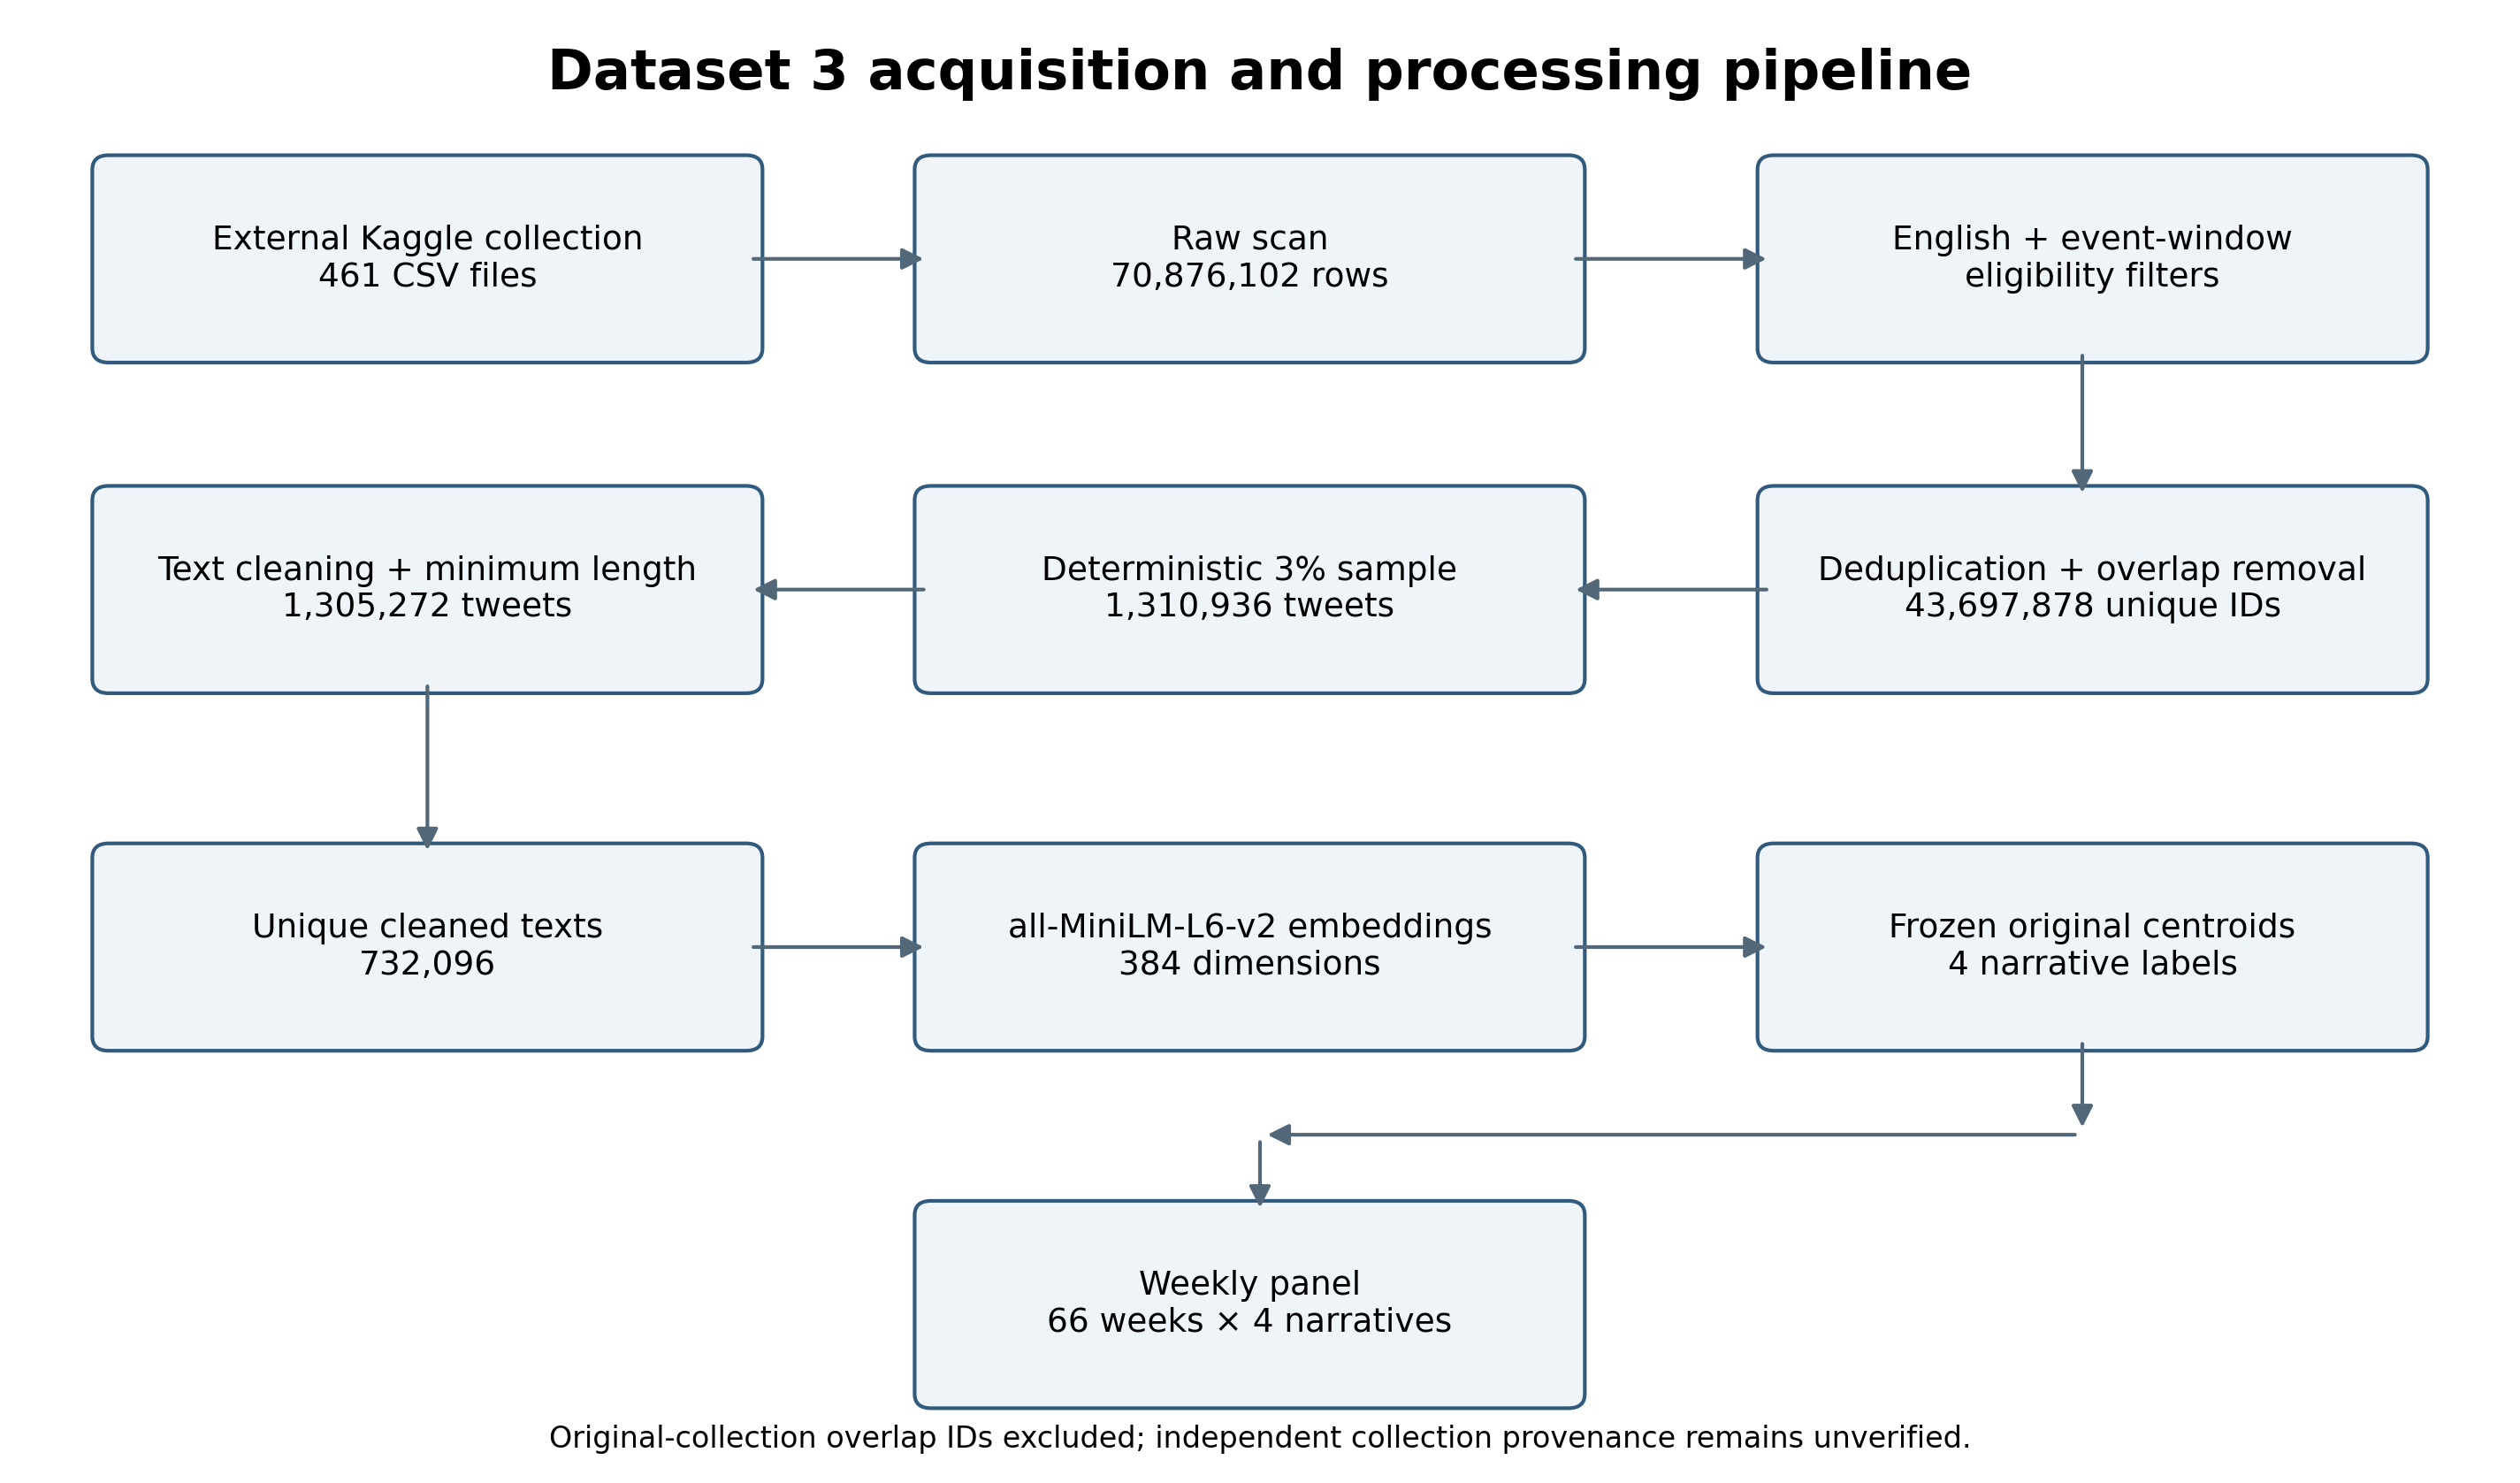


figure_2_weekly_tweet_volume.png


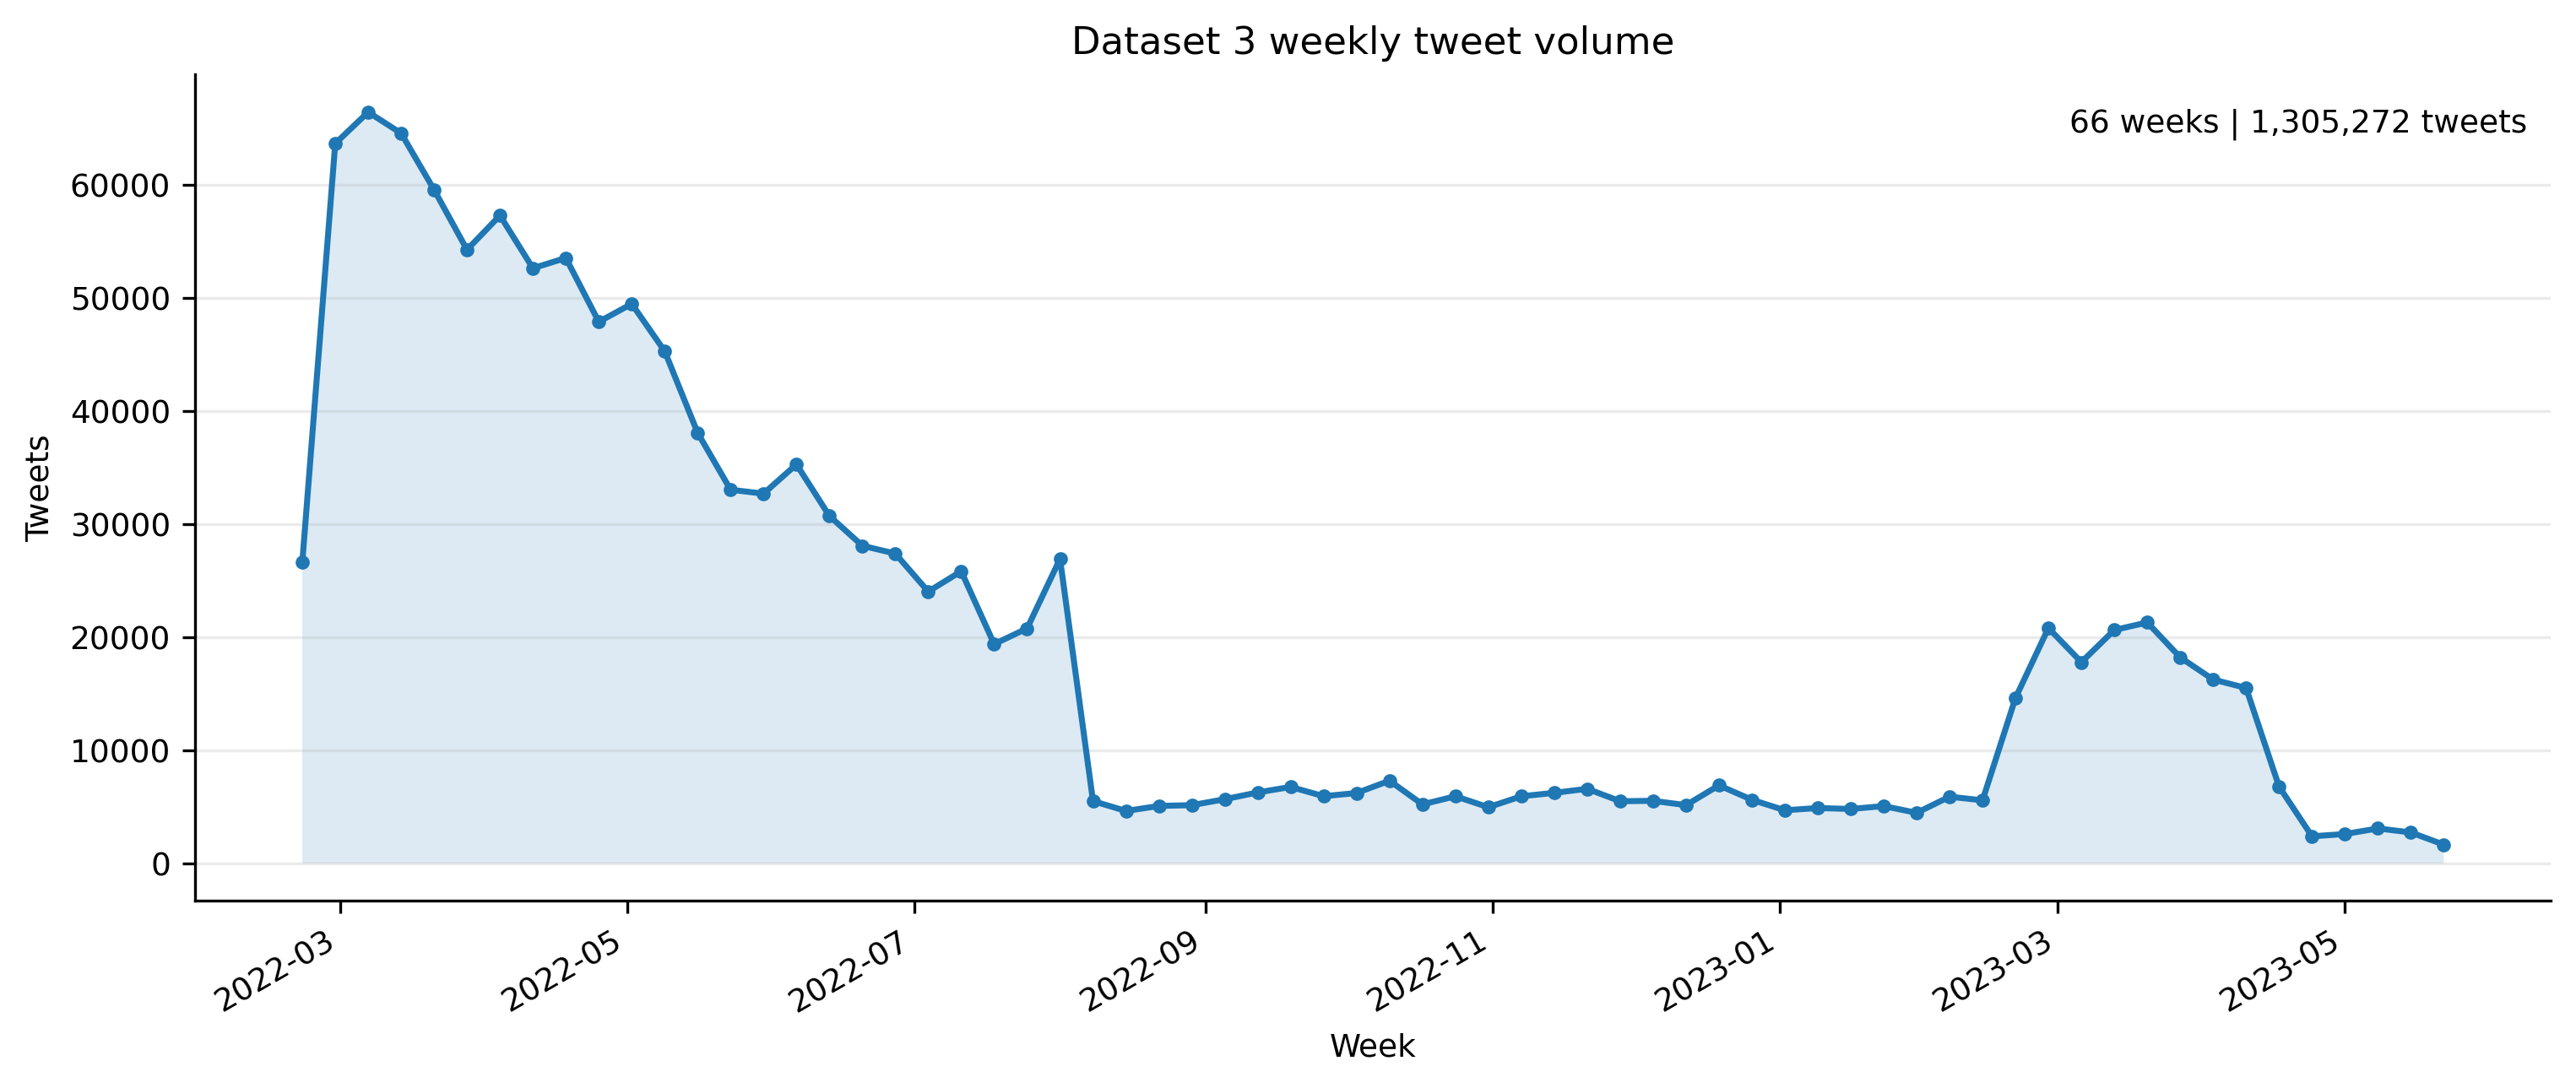


figure_3_narrative_distribution.png


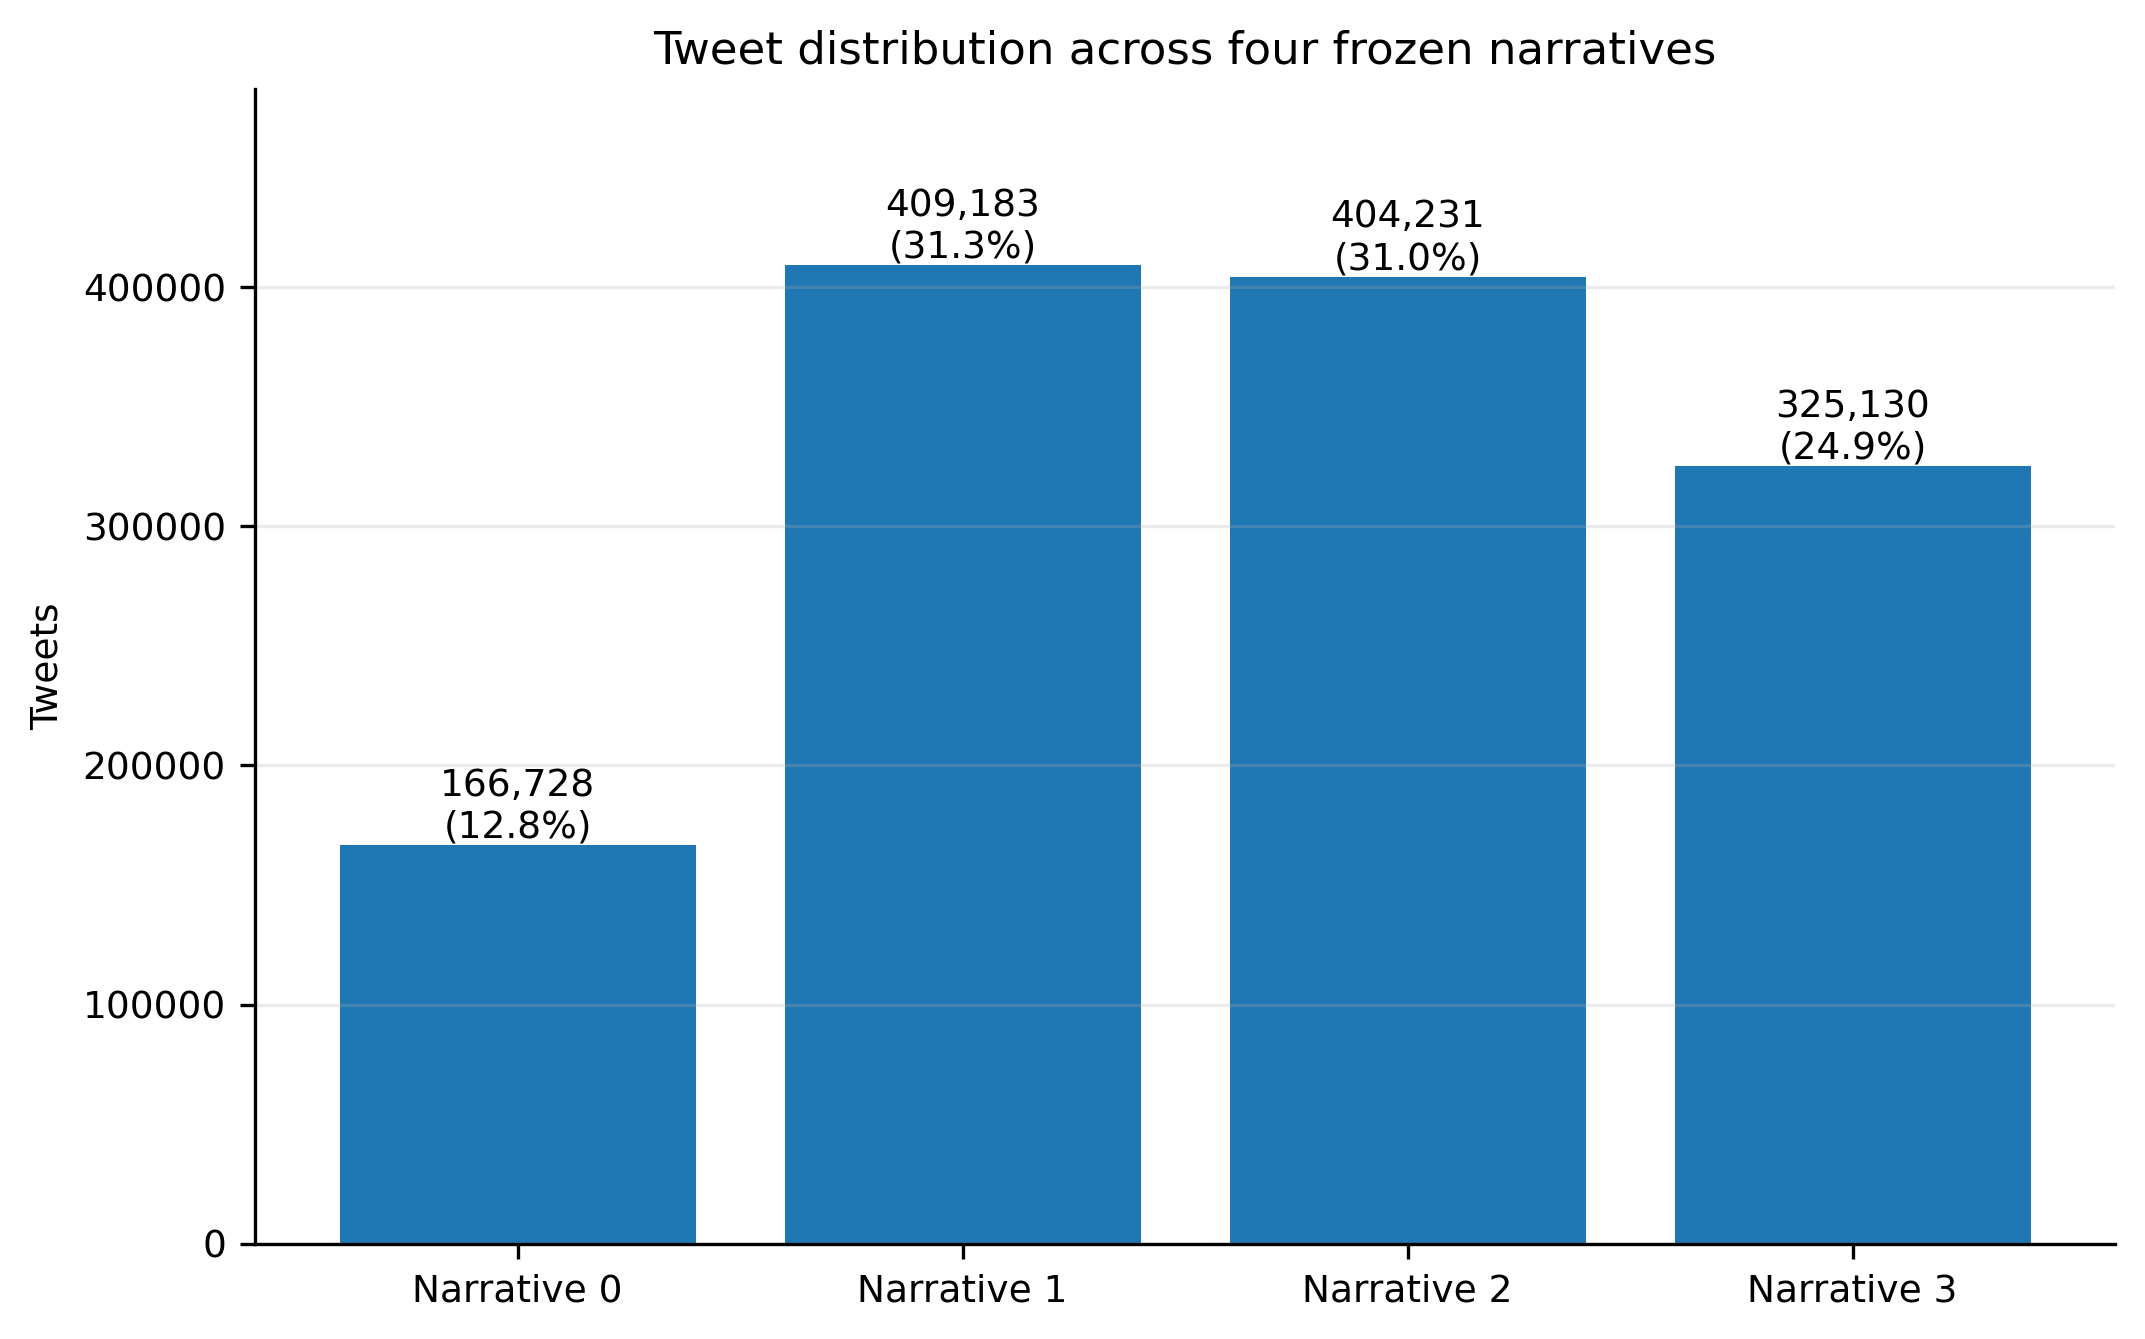


figure_4_baseline_comparison.png


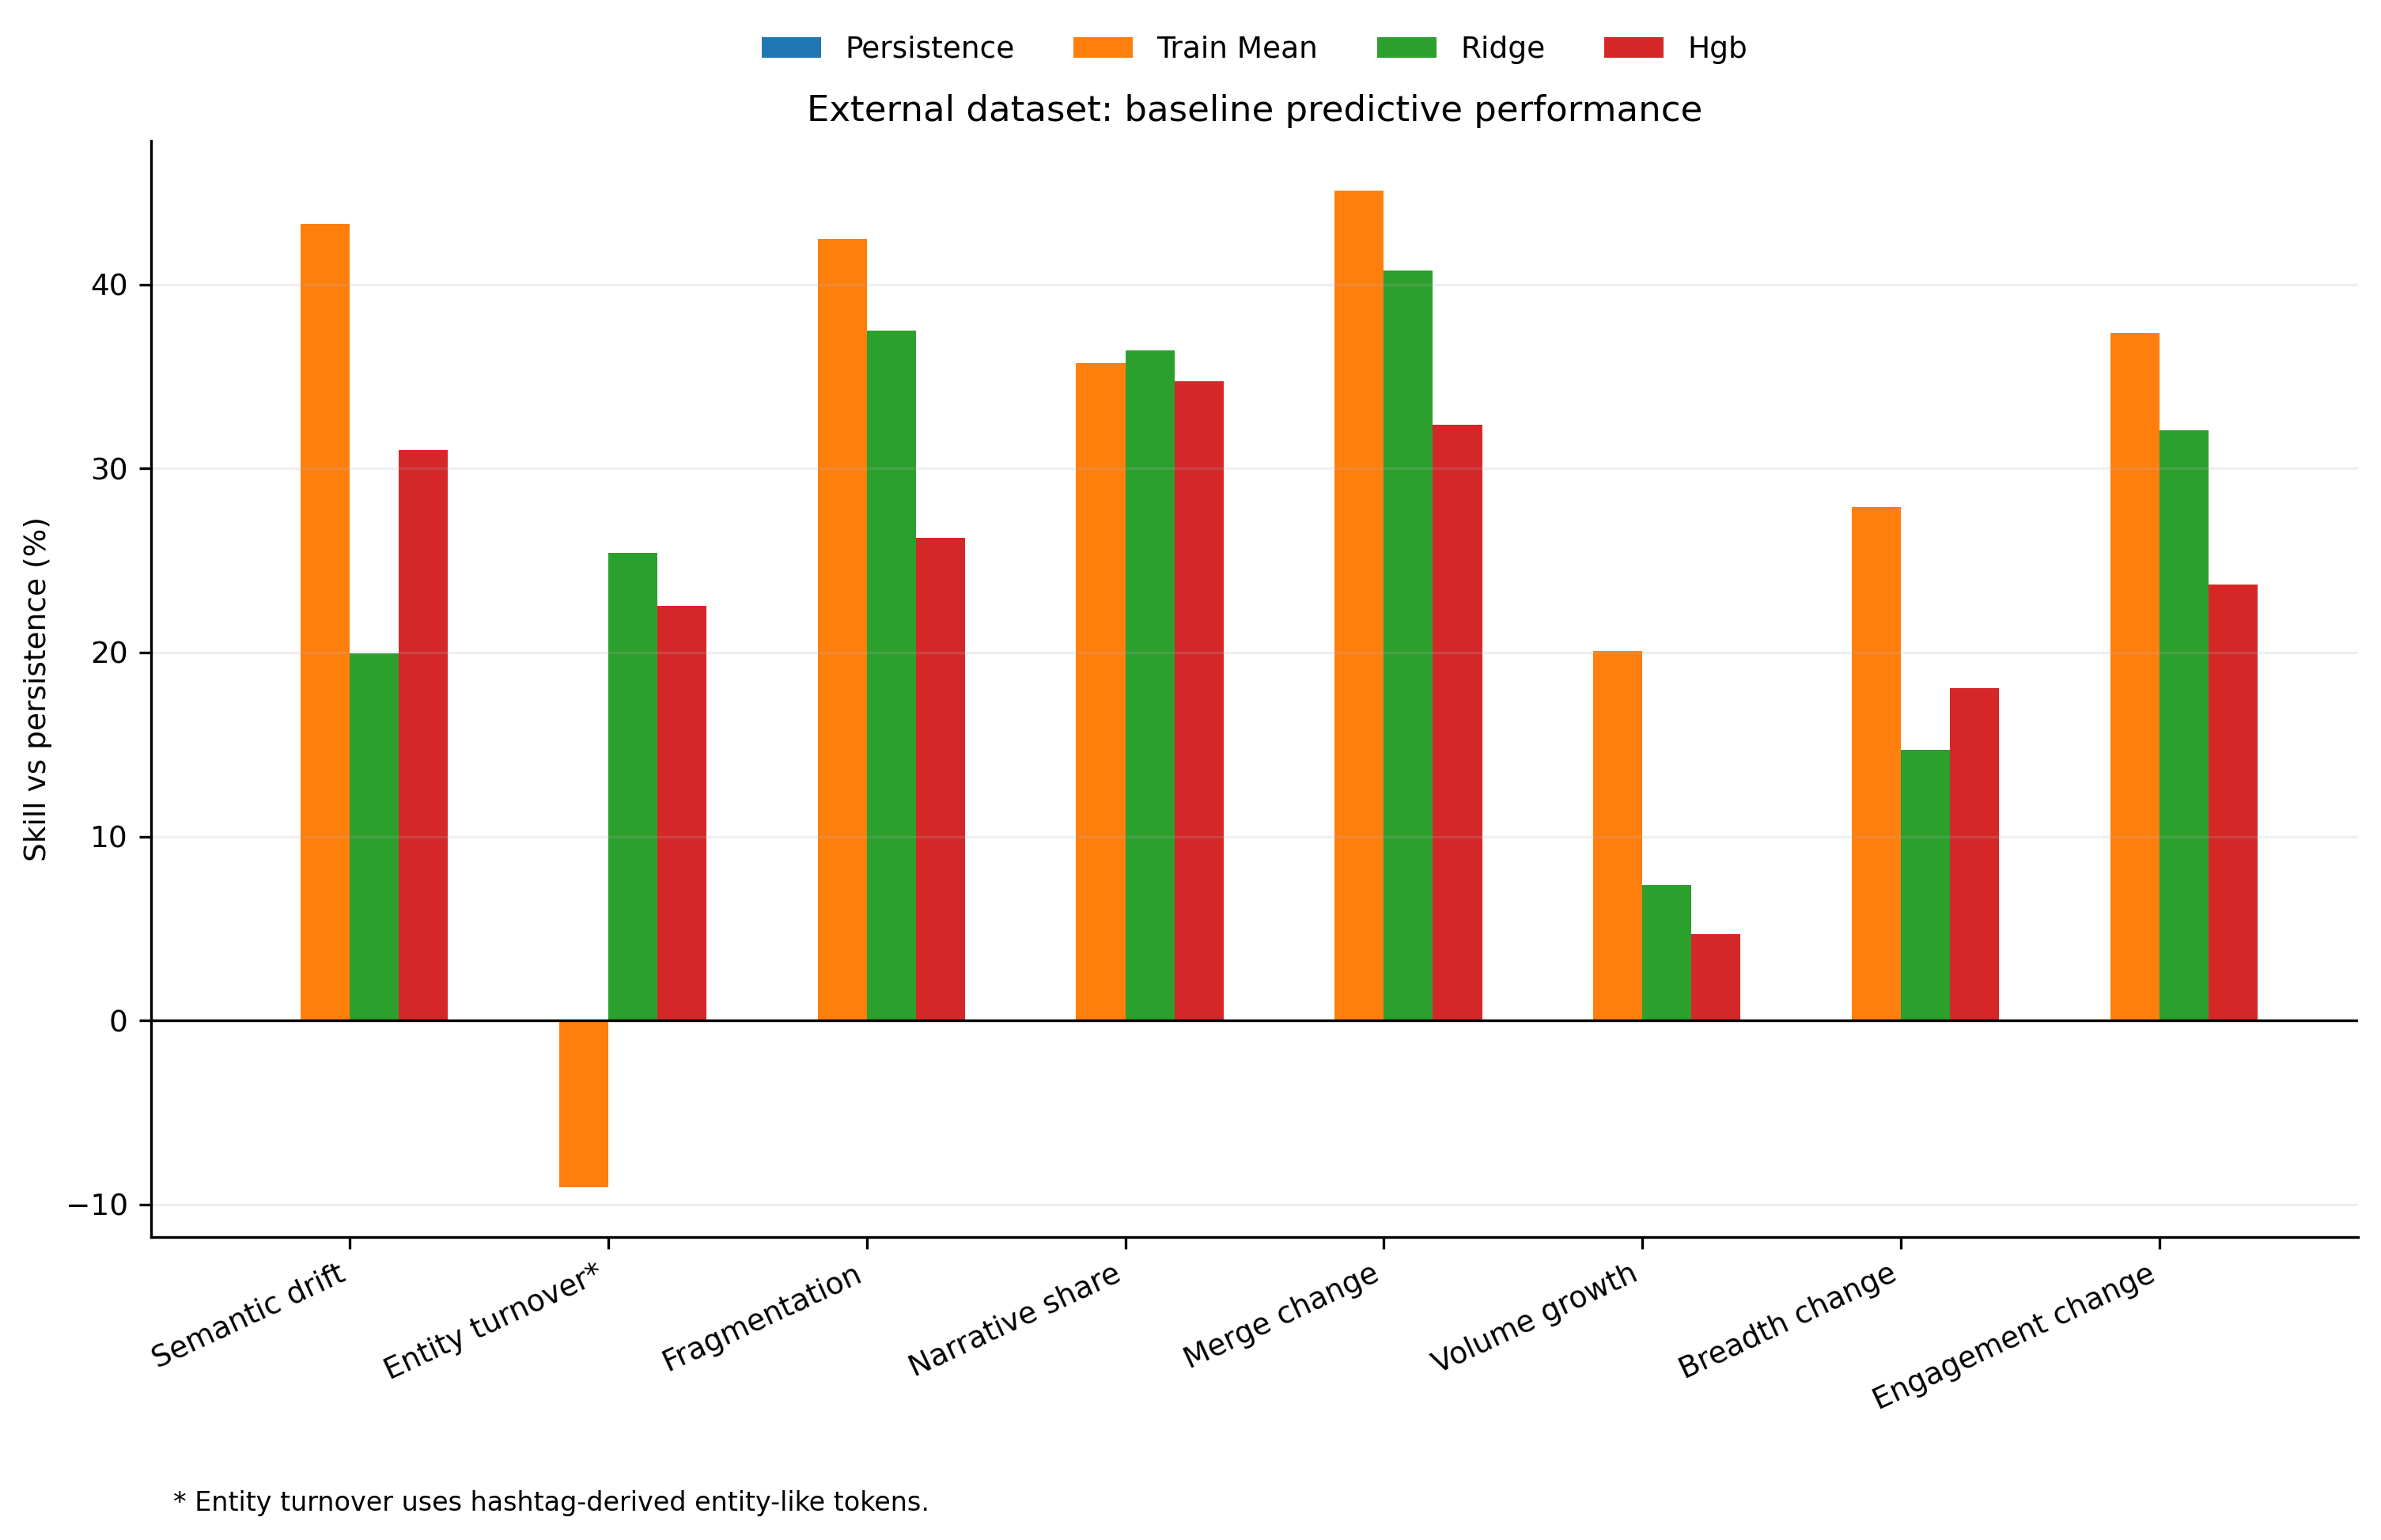


figure_5_competition_gains.png


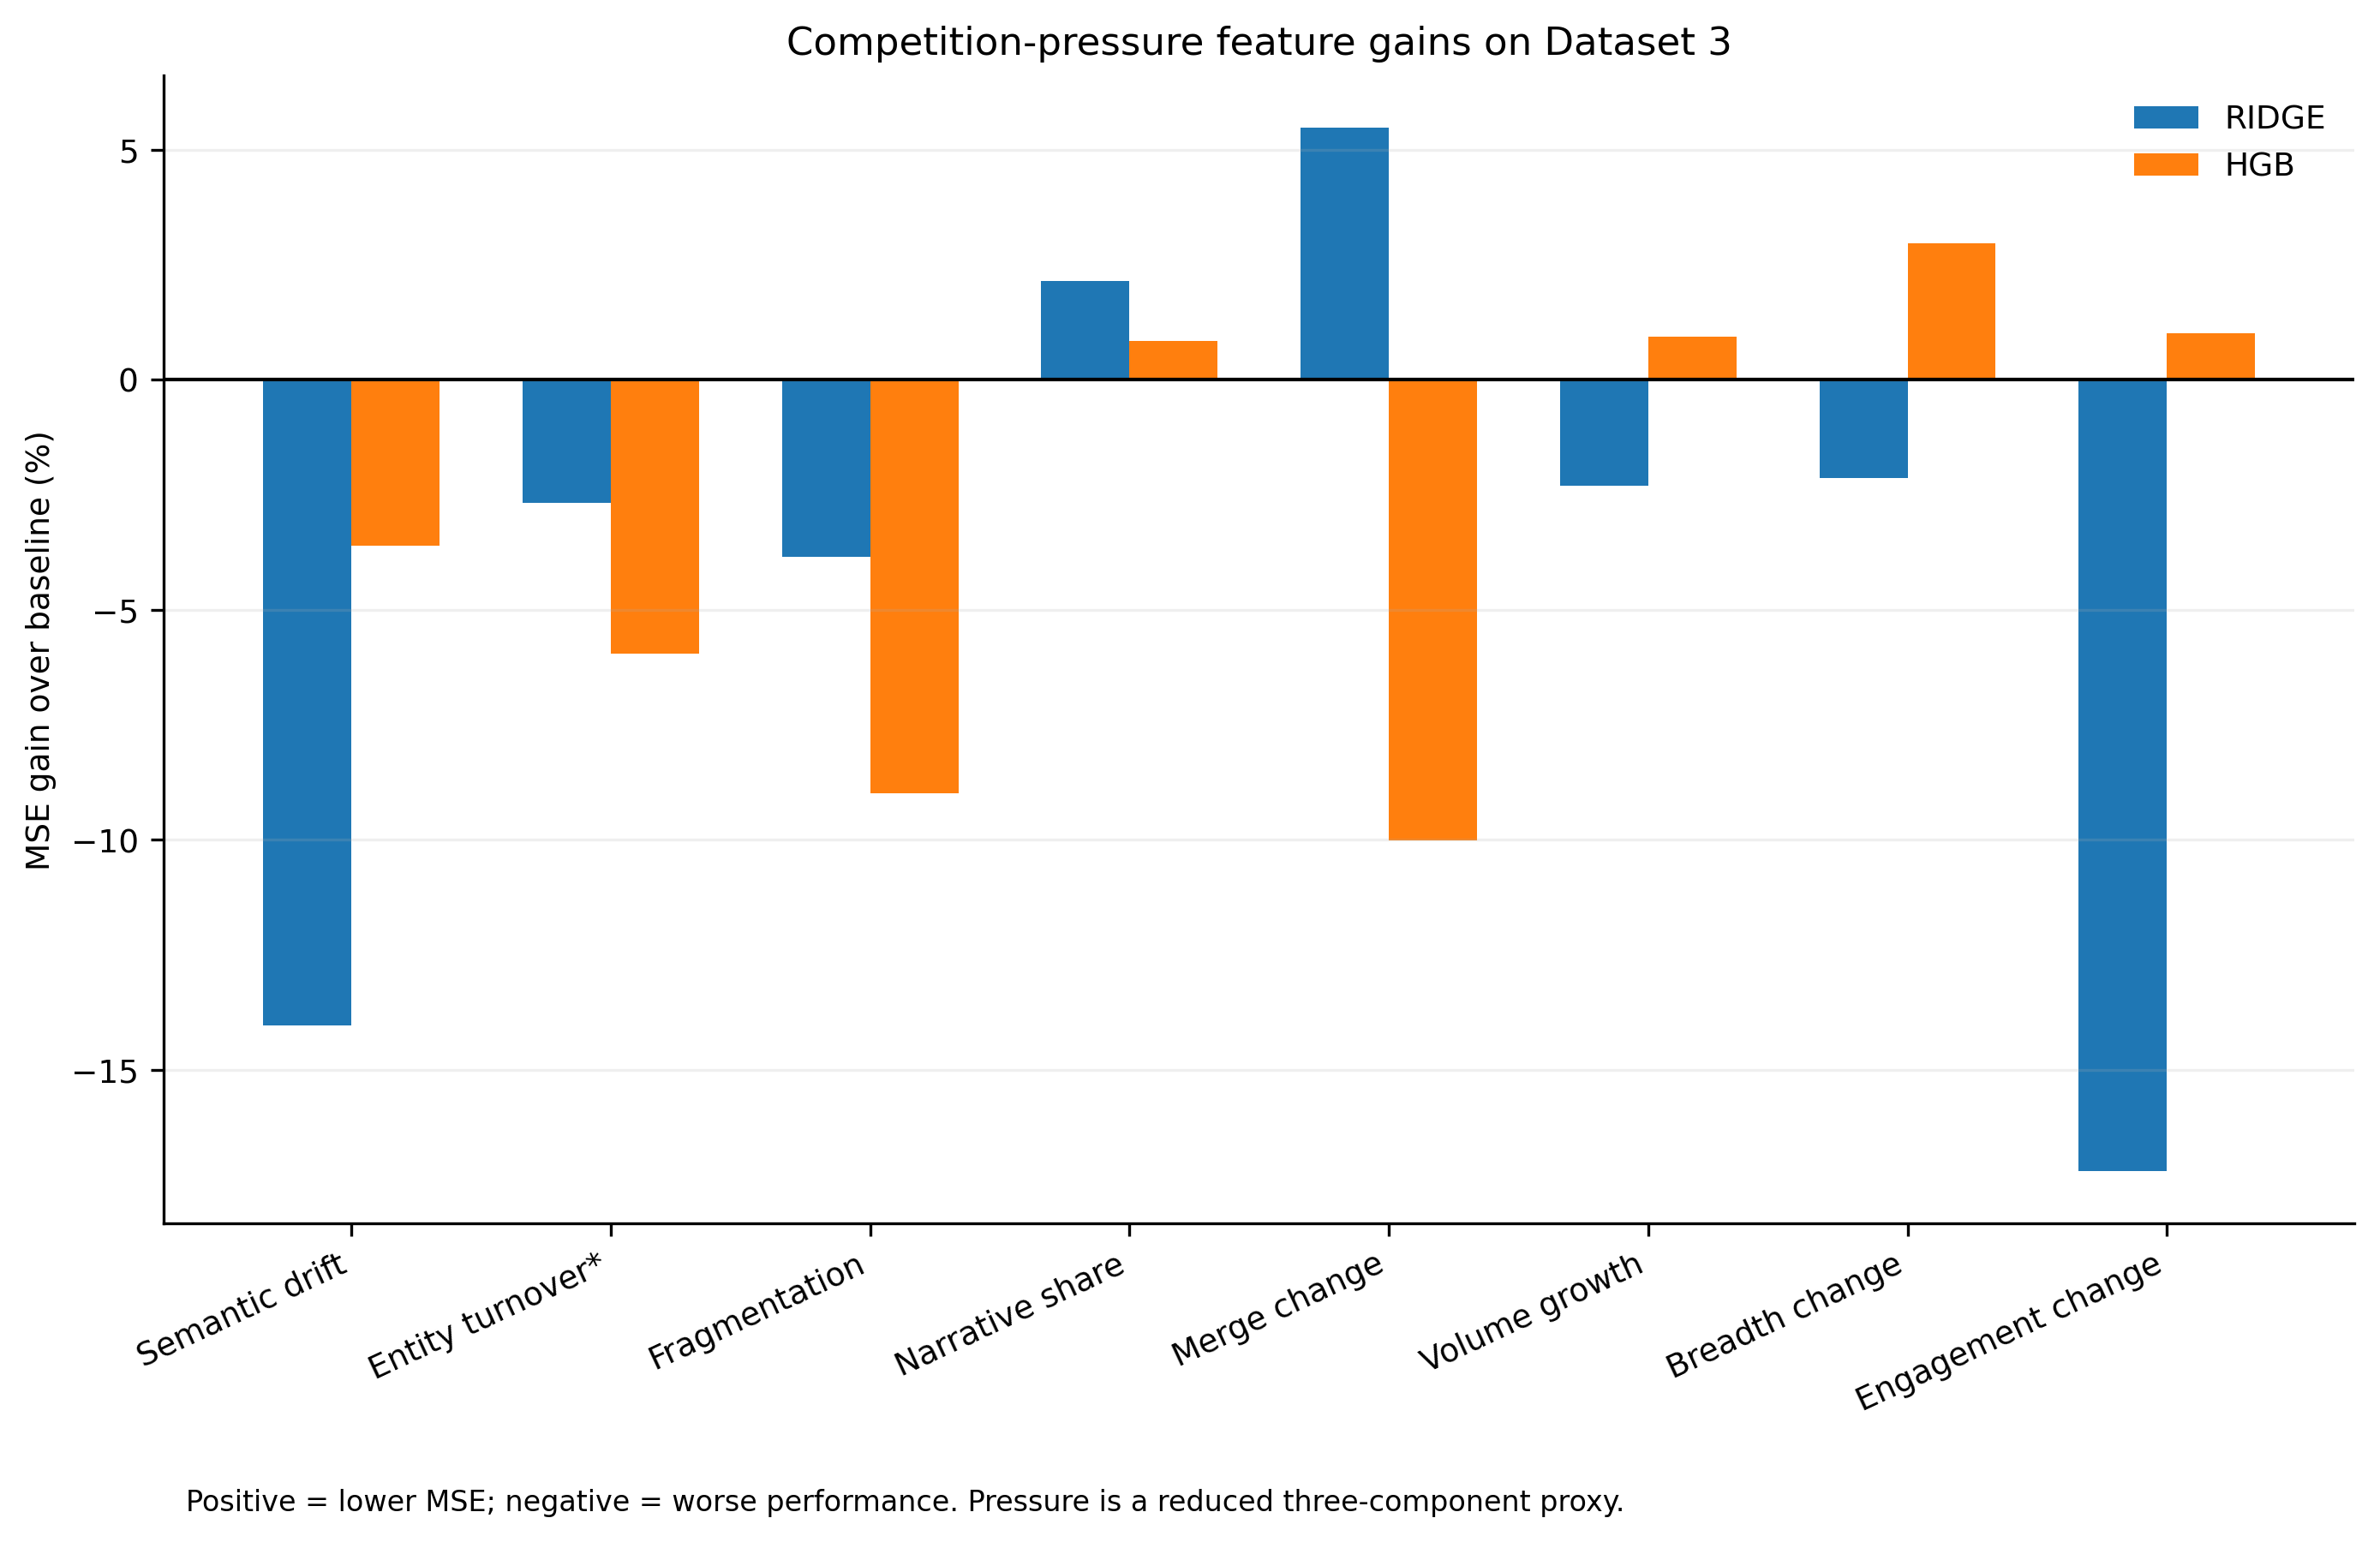


figure_6_placebo_holm_pvalues.png


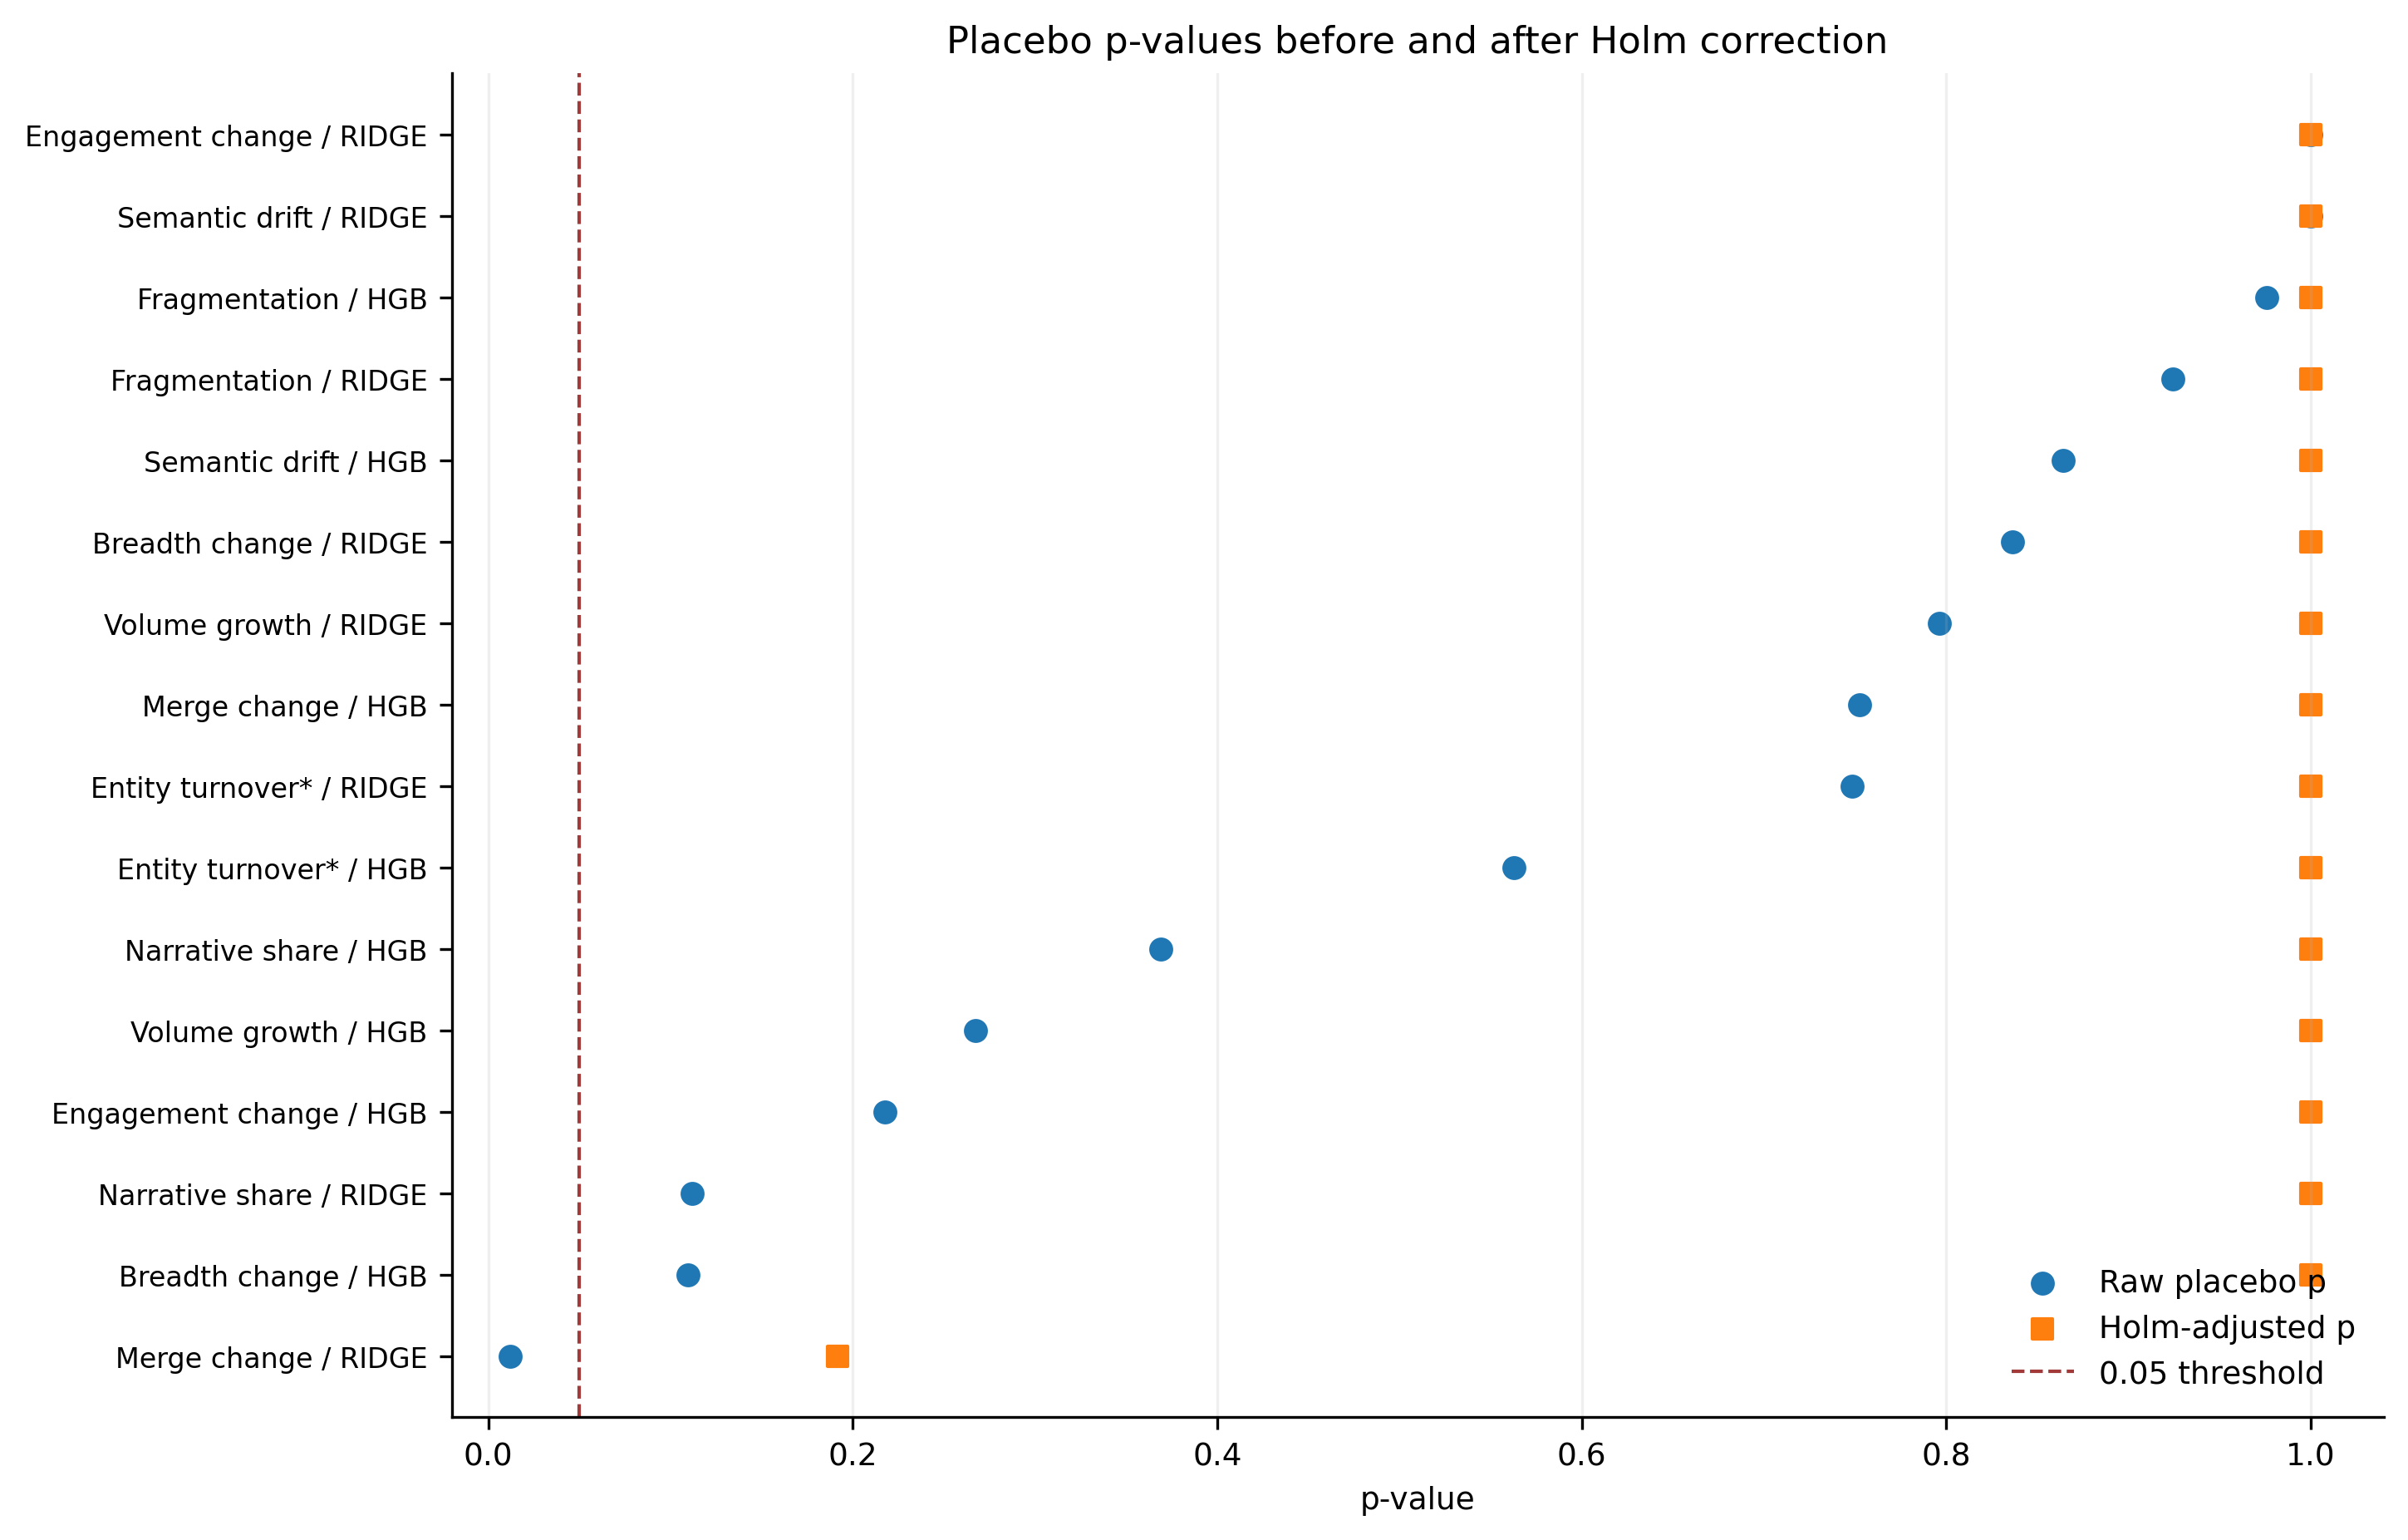

In [18]:
from pathlib import Path
from IPython.display import display, Image

fig_dir = Path("figs_rep")

for f in sorted(fig_dir.glob("figure_*.png")):
    print(f"\n{f.name}")
    display(Image(filename=str(f)))